# B4 · LLM en pratique : Hugging Face, prompting, RAG et LoRA — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b4_llm/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B4.Q1 à B4.Q12, B4.R1 à B4.R3, B4.1 à B4.5 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | B4.12 | Premier contact : AutoTokenizer, AutoModelForCausalLM, generate() et pipeline sur un petit modèle | 📦 | ★★ | 25 |
|  | B4.13 | Prédire : dix générations du même prompt à température 0, 0,7 et 1,5 | 🔮 | ★ | 10 |
|  | B4.14 | Chat template, message système, arrêt et streaming avec un modèle instruct | 📦 | ★★ | 25 |
|  | B4.15 | Prompting pour extraire des informations de Holmes : zéro-shot, few-shot, JSON validé, vote majoritaire | 📦 | ★★★ | 45 |
|  | B4.16 | Sensibilité au prompt : cinq formulations, trois graines, ordre des exemples | 🔬 | ★★★ | 40 |
| B | B4.17 | chunk_text et BM25 : découper un roman et classer ses passages | 🔨 | ★★★ | 45 |
|  | B4.18 | cosine_top_k, fusion de classements (RRF), recall@k et MRR | 🔨 | ★★ | 30 |
|  | B4.19 | Prédire : sur des questions paraphrasées, BM25 ou recherche dense gagne-t-elle ? | 🔮 | ★ | 10 |
|  | B4.20 | Recherche dense (MiniLM, e5) contre BM25 contre hybride sur 30 questions annotées | 📦 | ★★★ | 45 |
|  | B4.21 | Un RAG complet sur Holmes : récupération hybride, prompt avec citations, réponse d'un petit modèle | 📦 | ★★★ | 60 |
| B | B4.22 à B4.24 | suite de la recherche et du RAG : quatre défauts, évaluation et analyse des échecs, injection de prompt (*prochaine session de génération*) | | | |
| C | B4.25 à B4.28 | fine-tuning : LoRA à la main contre peft, style de Holmes, rang et modules ciblés, classification de textes (*prochaine session de génération*) | | | |
| D | B4.29 et B4.30 | livraison : pipeline reproductible et défi RAG (*prochaine session de génération*) | | | |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Estimer la mémoire d'un LLM (poids selon le dtype, KV cache) et appliquer à la main son chat template.
- Charger et faire générer de petits modèles avec transformers, écrire et évaluer des prompts sur plusieurs formulations et graines.
- Implémenter le découpage, BM25, la recherche dense, la fusion RRF, recall@k et MRR, puis construire, évaluer et diagnostiquer un RAG avec citations.
- Compter, écrire à la main et appliquer avec peft une adaptation LoRA, et comparer fine-tuning, prompting et classifieur classique.

**Rappel express.** Mémoire des poids $\approx N \times$ octets par paramètre (4 en float32, 2 en bfloat16, $\approx 0{,}5$ en int4) ; KV cache $= 2 \times L \times T \times n_{kv} d_h \times$ octets par valeur. BM25 : $\sum_{t \in q} \operatorname{idf}(t)\,\frac{f_{t,d}(k_1 + 1)}{f_{t,d} + k_1(1 - b + b\,|d| / \overline{|d|})}$, $\operatorname{idf}(t) = \ln\big(1 + \frac{N - n_t + 0{,}5}{n_t + 0{,}5}\big)$. RRF : $\sum_r 1/(k + \operatorname{rang}_r(d))$, $k = 60$. recall@$k$ $= |\text{top-}k \cap \text{pertinents}| / |\text{pertinents}|$ ; MRR = moyenne de $1/\operatorname{rang}$ du premier pertinent. LoRA : $\mathbf{W}' = \mathbf{W} + \frac{\alpha}{r}\mathbf{B}\mathbf{A}$, $\mathbf{B}_0 = 0$, $r(d + k)$ paramètres au lieu de $dk$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B4.1 à B4.5)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; un classement : une liste d'identifiants, du meilleur au moins bon (`[5, 6, 4]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la dérivation ∂ B4.6, l'estimation 🧮 B4.7, la réflexion (🗣️ B4.8, ⚖️ B4.9 et B4.10, 📄 B4.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math
import warnings
from fractions import Fraction

import numpy as np

warnings.filterwarnings("ignore", message=".*IProgress not found.*")    # tqdm without ipywidgets (transformers)
MB, GB = 10 ** 6, 10 ** 9                                           # the units of the chapter (decimal)

# ✏️ B4.1: SmolLM2-135M-Instruct (config.json, revision 12fd25f)
N_B41, LAYERS_B41, D_B41, V_B41, KV_HEADS_B41, DH_B41, CTX_B41 = 134_515_008, 30, 576, 49_152, 3, 64, 8_192
EMB_B41 = V_B41 * D_B41                                             # the token table (tied with the output layer)
EMB_SHARE_B41 = 100 * EMB_B41 / N_B41
FP32_B41, BF16_B41, INT4_B41 = 4 * N_B41 / MB, 2 * N_B41 / MB, 0.5 * N_B41 / MB
KV_TOKEN_B41 = 2 * LAYERS_B41 * KV_HEADS_B41 * DH_B41 * 2           # keys and values, every layer, bf16
KV_FULL_B41 = KV_TOKEN_B41 * CTX_B41 / MB
CONVERSATIONS_B41 = int((2 * GB - 2 * N_B41) // (KV_TOKEN_B41 * CTX_B41))
QWEN_FOOTPRINT, QWEN_SECONDS, QWEN_TOKENS = 1_976_131_328, 8.4, 64   # fiche §204.2, Qwen2.5-0.5B-Instruct in float32
SPEED_B41 = QWEN_TOKENS / QWEN_SECONDS * QWEN_FOOTPRINT / (4 * N_B41)

# ✏️ B4.2: five queries, five retrieved ids each
RETRIEVED_B42 = [[3, 1, 4, 0, 2], [5, 9, 2, 6, 8], [0, 7, 1, 2, 3], [6, 4, 8, 9, 1], [2, 0, 9, 3, 7]]
RELEVANT_B42 = [{1}, {2, 8}, {0, 5}, {7}, {3, 4, 9}]


def recall_b42(k, retrieved=RETRIEVED_B42, relevant=RELEVANT_B42, denominator="relevant"):
    """Mean of |top-k ∩ relevant| / |relevant| (denominator="k": the precision@k mistake)."""
    ratios = [len(set(r[:k]) & rel) / (len(rel) if denominator == "relevant" else k)
              for r, rel in zip(retrieved, relevant)]
    return sum(ratios) / len(ratios)


def first_rank_b42(r, rel):
    return next((i + 1 for i, doc in enumerate(r) if doc in rel), None)


MRR_B42 = sum(1 / rank if (rank := first_rank_b42(r, rel)) else 0
              for r, rel in zip(RETRIEVED_B42, RELEVANT_B42)) / 5
HIT3_B42 = sum(any(doc in rel for doc in r[:3]) for r, rel in zip(RETRIEVED_B42, RELEVANT_B42)) / 5
FULL5_B42 = sum(set(r[:5]) >= rel for r, rel in zip(RETRIEVED_B42, RELEVANT_B42))

# ✏️ B4.3: LoRA on Qwen2.5-0.5B-Instruct (24 layers, d_model = 896, k and v 896 -> 128, MLP 896 -> 4 864)
N_QWEN, LAYERS_QWEN, D_QWEN, KV_QWEN, MLP_QWEN, R_B43 = 494_032_768, 24, 896, 128, 4_864, 8


def lora_params(d_out, d_in, r=R_B43):
    return r * (d_out + d_in)


Q_B43, K_B43 = lora_params(D_QWEN, D_QWEN), lora_params(KV_QWEN, D_QWEN)
Q_SHARE_B43, K_SHARE_B43 = 100 * Q_B43 / D_QWEN ** 2, 100 * K_B43 / (KV_QWEN * D_QWEN)
LAYER_B43 = 2 * Q_B43 + 2 * K_B43                                   # q, k, v, o
MODEL_B43 = LAYERS_QWEN * LAYER_B43
TRAINABLE_PCT_B43 = 100 * MODEL_B43 / (N_QWEN + MODEL_B43)
ALL_LINEAR_B43 = LAYERS_QWEN * (LAYER_B43 + 3 * lora_params(MLP_QWEN, D_QWEN))
ADAPTER_MB_B43 = 4 * MODEL_B43 / MB
NO_SAVING_RANK_B43 = math.ceil(D_QWEN ** 2 / (2 * D_QWEN))           # r (d + k) >= d k

# ✏️ B4.4: the chat template of SmolLM2-135M-Instruct (revision 12fd25f), and the tokens of each piece
SMOL_TEMPLATE = ("{% for message in messages %}{% if loop.first and messages[0]['role'] != 'system' %}"
                 "{{ '<|im_start|>system\nYou are a helpful AI assistant named SmolLM, trained by Hugging Face"
                 "<|im_end|>\n' }}{% endif %}{{'<|im_start|>' + message['role'] + '\n' + message['content'] + "
                 "'<|im_end|>' + '\n'}}{% endfor %}{% if add_generation_prompt %}{{ '<|im_start|>assistant\n' }}"
                 "{% endif %}")
DEFAULT_SYSTEM = "You are a helpful AI assistant named SmolLM, trained by Hugging Face"
S_B44 = {"role": "system", "content": "Answer in one short sentence."}
U_B44 = {"role": "user", "content": "Where does Holmes live?"}
A_B44 = {"role": "assistant", "content": "In London, at 221B Baker Street."}
U2_B44 = {"role": "user", "content": "Who is his friend?"}
CONTENT_TOKENS = {DEFAULT_SYSTEM: 16, S_B44["content"]: 6, U_B44["content"]: 5, A_B44["content"]: 12,
                  U2_B44["content"]: 5}
ROLE_TOKENS = {"system": 1, "user": 1, "assistant": 2}


def by_hand_b44(messages, add_generation_prompt):
    """The chat template applied by hand: the string, its special tokens and its token count."""
    if messages[0]["role"] != "system":
        messages = [{"role": "system", "content": DEFAULT_SYSTEM}] + messages
    text = "".join(f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>\n" for m in messages)
    specials = 2 * len(messages)
    tokens = sum(1 + ROLE_TOKENS[m["role"]] + 1 + CONTENT_TOKENS[m["content"]] + 1 + 1 for m in messages)
    if add_generation_prompt:
        text, specials, tokens = text + "<|im_start|>assistant\n", specials + 1, tokens + 1 + 2 + 1
    return text, specials, tokens


U_GEN_B44 = by_hand_b44([U_B44], True)
SU_GEN_B44, SU_NOGEN_B44 = by_hand_b44([S_B44, U_B44], True), by_hand_b44([S_B44, U_B44], False)
TURN2_B44 = by_hand_b44([S_B44, U_B44, A_B44, U2_B44], True)
DOUBLE_SYSTEM_B44 = by_hand_b44([{"role": "system", "content": DEFAULT_SYSTEM}, S_B44, U_B44], True)

# ✏️ B4.5: BM25 by hand (k1 = 1.5, b = 0.75), three documents, query "nemo nautilus"
DOCS_B45 = [["nemo", "commande", "le", "nautilus"], ["le", "nautilus", "plonge"],
            ["le", "nautilus", "croise", "un", "nautilus", "au", "grand", "large"]]
QUERY_B45 = ["nemo", "nautilus"]


def bm25_b45(query=QUERY_B45, docs=DOCS_B45, k1=1.5, b=0.75, idf_form="plus_one"):
    """BM25 scores of the docstring; idf_form="original" drops the "1 +" of the idf."""
    n, avgdl = len(docs), sum(map(len, docs)) / len(docs)
    scores = np.zeros(n)
    for t in query:
        n_t = sum(t in doc for doc in docs)
        ratio = (n - n_t + 0.5) / (n_t + 0.5)
        idf = math.log(1 + ratio) if idf_form == "plus_one" else math.log(ratio)
        for i, doc in enumerate(docs):
            f = doc.count(t)
            if f:
                scores[i] += idf * f * (k1 + 1) / (f + k1 * (1 - b + b * len(doc) / avgdl))
    return scores


AVGDL_B45 = sum(map(len, DOCS_B45)) / 3
IDF_NAUTILUS_B45 = math.log(1 + 0.5 / 3.5)
SCORES_B45 = bm25_b45()
RANKING_B45 = [int(i) for i in np.argsort(-SCORES_B45, kind="stable")]
SCORES_B0_B45 = bm25_b45(b=0.0)
SCORES_K0_B45 = bm25_b45(k1=0.0)
SCORES_ORIGINAL_B45 = bm25_b45(idf_form="original")

# quizzes and recalls with a computation
Q3A, Q3B = 2 * 3e9 / GB, 0.5 * 3e9 / GB
Q8C = math.sqrt(0.8 * 0.2 / 100)
Q9E = 2 / (60 + 3)
Q11C = 4 * (512 + 512)
R1C = 2 * 24 * 2 * 64 * 2
A_R3, B_R3 = np.array([3.0, 4.0]), np.array([6.0, 8.0])
COS_R3 = float(A_R3 @ B_R3 / (np.linalg.norm(A_R3) * np.linalg.norm(B_R3)))
DIST_R3 = float(np.linalg.norm(A_R3 - B_R3))
SQ_R3 = 2 - 2 * 0.82
MULT_R3 = 50_000 * 768

# The same answers from the libraries (no download): mylearn (reference), scikit-learn, transformers and peft
import torch
from peft import LoraConfig, get_peft_model
from torch import nn
from transformers import AutoModelForCausalLM, LlamaConfig, Qwen2Config
from transformers.utils.chat_template_utils import render_jinja_template

R = mylearn.retrieval
# ✏️ B4.2: recall_at_k and mean_reciprocal_rank of the reference
for k, expected in ((1, recall_b42(1)), (3, recall_b42(3)), (5, recall_b42(5))):
    assert math.isclose(R.recall_at_k(RETRIEVED_B42, RELEVANT_B42, k=k), expected)
assert math.isclose(R.mean_reciprocal_rank(RETRIEVED_B42, RELEVANT_B42), MRR_B42)
assert R.mean_reciprocal_rank(RETRIEVED_B42, RELEVANT_B42) >= R.recall_at_k(RETRIEVED_B42, RELEVANT_B42, k=1)

# ✏️ B4.5: BM25 of the reference, then the same corpus with b = 0, k1 = 0 and the original idf
bm25 = R.BM25(k1=1.5, b=0.75).fit(DOCS_B45)
assert bm25.avgdl_ == AVGDL_B45 and math.isclose(bm25.idf_["nautilus"], IDF_NAUTILUS_B45)
assert np.allclose(bm25.get_scores(QUERY_B45), SCORES_B45)
assert np.allclose(R.BM25(k1=1.5, b=0.0).fit(DOCS_B45).get_scores(QUERY_B45), SCORES_B0_B45)
assert np.allclose(R.BM25(k1=0.0, b=0.75).fit(DOCS_B45).get_scores(QUERY_B45), SCORES_K0_B45)
assert SCORES_ORIGINAL_B45[0] < 0                                   # below a document with no query word (score 0)
assert RANKING_B45 == [int(i) for i in np.argsort(-bm25.get_scores(QUERY_B45), kind="stable")]

# quiz Q9 e: a document ranked 3rd in two rankings (reciprocal_rank_fusion only returns the ids: the score by hand)
assert R.reciprocal_rank_fusion([[1, 2, 7], [3, 4, 7]])[0] == 7 and math.isclose(float(Fraction(2, 63)), Q9E)

# rappel R3: cosine and Euclidean distance, scikit-learn and the B2 reference
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
assert math.isclose(cosine_similarity([A_R3], [B_R3])[0, 0], COS_R3)
assert math.isclose(mylearn.embeddings.cosine_similarity_matrix([A_R3], [B_R3])[0, 0], COS_R3)
assert math.isclose(euclidean_distances([A_R3], [B_R3])[0, 0], DIST_R3)
u = np.array([1.0, 0.0]); v = np.array([0.82, math.sqrt(1 - 0.82 ** 2)])
assert math.isclose(float(np.sum((u - v) ** 2)), SQ_R3)

# ✏️ B4.1: SmolLM2-135M built from its configuration on the meta device (shapes only, no download)
smol_config = LlamaConfig(hidden_size=576, intermediate_size=1536, num_hidden_layers=30, num_attention_heads=9,
                          num_key_value_heads=3, vocab_size=49152, max_position_embeddings=8192,
                          tie_word_embeddings=True)
with torch.device("meta"):
    smol = AutoModelForCausalLM.from_config(smol_config)
assert smol.num_parameters() == N_B41 and smol.model.embed_tokens.weight.numel() == EMB_B41
assert smol.lm_head.weight is smol.model.embed_tokens.weight
head_dim = smol_config.hidden_size // smol_config.num_attention_heads
assert 2 * smol_config.num_hidden_layers * smol_config.num_key_value_heads * head_dim * 2 == KV_TOKEN_B41

# ✏️ B4.3 and rappel R1: Qwen2.5-0.5B built from its configuration, then wrapped by peft (r = 8)
qwen_config = Qwen2Config(hidden_size=896, intermediate_size=4864, num_hidden_layers=24, num_attention_heads=14,
                          num_key_value_heads=2, vocab_size=151936, max_position_embeddings=32768,
                          tie_word_embeddings=True)


def peft_counts(target_modules, r=8):
    with torch.device("meta"):
        base = AutoModelForCausalLM.from_config(qwen_config)
    return get_peft_model(base, LoraConfig(r=r, lora_alpha=16, target_modules=target_modules, lora_dropout=0.0,
                                           task_type="CAUSAL_LM")).get_nb_trainable_parameters()


with torch.device("meta"):
    qwen = AutoModelForCausalLM.from_config(qwen_config)
assert qwen.num_parameters() == N_QWEN
attention = qwen.model.layers[0].self_attn
assert attention.k_proj.weight.shape == (KV_QWEN, D_QWEN) and attention.q_proj.weight.shape == (D_QWEN, D_QWEN)
trainable, total = peft_counts(["q_proj", "k_proj", "v_proj", "o_proj"])
assert trainable == MODEL_B43 and total == N_QWEN + MODEL_B43
assert math.isclose(100 * trainable / total, TRAINABLE_PCT_B43)
assert peft_counts("all-linear")[0] == ALL_LINEAR_B43
assert peft_counts(["q_proj", "k_proj", "v_proj", "o_proj"], r=16)[0] == 2 * MODEL_B43
layer = nn.Sequential(nn.Linear(D_QWEN, D_QWEN))                     # one 896 x 896 layer, as in a)
assert get_peft_model(layer, LoraConfig(r=8, target_modules=["0"])).get_nb_trainable_parameters()[0] == Q_B43
assert 2 * qwen_config.num_hidden_layers * qwen_config.num_key_value_heads * 64 * 2 == R1C

# ✏️ B4.4: the template rendered by transformers' own Jinja renderer, as apply_chat_template does
def render_b44(messages, add_generation_prompt):
    return render_jinja_template(conversations=[messages], chat_template=SMOL_TEMPLATE,
                                 add_generation_prompt=add_generation_prompt)[0][0]


for messages, gen, by_hand in (([U_B44], True, U_GEN_B44), ([S_B44, U_B44], True, SU_GEN_B44),
                               ([S_B44, U_B44], False, SU_NOGEN_B44), ([S_B44, U_B44, A_B44, U2_B44], True, TURN2_B44)):
    rendered = render_b44(messages, gen)
    assert rendered == by_hand[0], (rendered, by_hand[0])
    assert rendered.count("<|im_start|>") + rendered.count("<|im_end|>") == by_hand[1]
try:                                                                 # optional: the real tokenizer, if already cached
    from transformers import AutoTokenizer
    smol_tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct",
                                             revision="12fd25f77366fa6b3b4b768ec3050bf629380bac", local_files_only=True)
except OSError:
    print("ℹ️ SmolLM2's tokenizer is not in the local cache: token counts checked when the chapter was generated")
else:
    assert smol_tok.chat_template == SMOL_TEMPLATE
    for messages, gen, by_hand in (([U_B44], True, U_GEN_B44), ([S_B44, U_B44], True, SU_GEN_B44),
                                   ([S_B44, U_B44], False, SU_NOGEN_B44),
                                   ([S_B44, U_B44, A_B44, U2_B44], True, TURN2_B44)):
        ids = smol_tok.apply_chat_template(messages, add_generation_prompt=gen, return_dict=True)["input_ids"]
        assert len(ids) == by_hand[2] and len(smol_tok(by_hand[0])["input_ids"]) == by_hand[2]
    print("✅ token counts of ✏️ B4.4 checked with the tokenizer of SmolLM2-135M-Instruct (local cache)")
print("✅ the paper answers agree with mylearn (reference), scikit-learn, transformers and peft")

✅ token counts of ✏️ B4.4 checked with the tokenizer of SmolLM2-135M-Instruct (local cache)
✅ the paper answers agree with mylearn (reference), scikit-learn, transformers and peft


**B4.Q1 — Modèle de base, modèle instruct, modèle de chat : lequel pour quoi ?**

In [3]:
wb.record("B4.Q1a", "B", mistakes={"relis « Trois étapes, trois sortes de modèles » : ce que l'on veut ici est-il un dialogue ?": "A", "relis l'étape 1 de « Trois étapes » : quel modèle continue n'importe quel texte ?": "C"})
wb.record("B4.Q1b", True, mistakes={"compare les tokens du pré-entraînement et les paires du SFT (§204.1)": False})
wb.record("B4.Q1c", "C", mistakes={"relis le paragraphe sur les noms du Hub : Qwen3 fait l'inverse des autres": "A", "relis le paragraphe sur les noms du Hub : que signifie le suffixe « -Instruct » ?": "B"})
wb.record("B4.Q1d", "C", mistakes={"relis l'étape 1 de « Trois étapes » : que produit le pré-entraînement ?": "A", "un gabarit met en forme une conversation : apprend-il au modèle à suivre une consigne ?": "B"})
wb.record("B4.Q1e", False, mistakes={"relis l'étape 1 de « Trois étapes » : qu'est-ce qui peut suivre une question dans un texte ?": True})

WB_ANSWER {"hash": "587da99447b97618dc09e245f5c97f8f08a773df86aa582d43b0809aa0743859", "id": "B4.Q1a", "kind": "str", "mistakes": {"5a6f4b408d6f08b5a0e20cc87c0abe4031a777999be5d855d4a37eab30c8a4d3": "relis l'étape 1 de « Trois étapes » : quel modèle continue n'importe quel texte ?", "e27067e146062c0eb17baed35605f67fec3a50c698999babe860d71f87631800": "relis « Trois étapes, trois sortes de modèles » : ce que l'on veut ici est-il un dialogue ?"}}
📝 Ex B4.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "0bd64138fcee23b52a3c181993b92b53a8e6be0fdebf3f84982748250e482485", "id": "B4.Q1b", "kind": "bool", "mistakes": {"8331be05f668c156fae54beaefdd86f68eba974f07c0d52382ce01cb8910a7d4": "compare les tokens du pré-entraînement et les paires du SFT (§204.1)"}}
📝 Ex B4.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "a364087b4aa9c846bb29559d95ad2984751c5752de7fe8f22766df98fef58239", "id": "B4.Q1c", "kind": "str", "mistakes": {"21bc18e3a212e7a987baf3db89a6bfa2d6d86a0e098e215aa5cdd354096472c0

**B4.Q2 — « Open weights » n'est pas « open source » : lire la licence d'un modèle**

In [4]:
wb.record("B4.Q2a", True, mistakes={"relis la première puce de « Licences » (§204.1)": False})
wb.record("B4.Q2b", "B", mistakes={"la licence d'origine impose-t-elle une autre licence aux dérivés ? Relis « Licences »": "A", "relis ce que la licence de Llama 3.2 demande pour un modèle dérivé redistribué": "C"})
wb.record("B4.Q2c", False, mistakes={"relis le paragraphe sur l'Open Source AI Definition : que demande-t-elle en plus des poids ?": True})
wb.record("B4.Q2d", "C", mistakes={"relis la troisième puce de « Licences » : que faut-il pour un accès contrôlé ?": "A", "un miroir non autorisé respecte-t-il les conditions de l'éditeur ?": "B"})
wb.record("B4.Q2e", "A", mistakes={"transformers exécute ces modèles : le code d'inférence est-il caché ?": "B", "from_pretrained lit config.json : ce fichier manque-t-il ?": "C"})

WB_ANSWER {"hash": "63f9c5e258e9d96fba2965fffc74929a37377e030cf72cdeb7bfc217bf381bae", "id": "B4.Q2a", "kind": "bool", "mistakes": {"327a85745b0cd2e16a611ff822d541c91bf5d1651cc0ffb7f5e319628ad64cb9": "relis la première puce de « Licences » (§204.1)"}}
📝 Ex B4.Q2a : réponse enregistrée (bool).
WB_ANSWER {"hash": "eec6fe80b7b7895cb2b8ceef2b4fdf9f4f56ad98bde5f2819aea9e68c757febb", "id": "B4.Q2b", "kind": "str", "mistakes": {"ad8078928d0e4c4314e806cb00d198eb0419b3c6546996d05997d20fa53b767d": "relis ce que la licence de Llama 3.2 demande pour un modèle dérivé redistribué", "ce68c8d3026aade93d7996c56587fd50bc01eadde2b8029b855a56fff87459fd": "la licence d'origine impose-t-elle une autre licence aux dérivés ? Relis « Licences »"}}
📝 Ex B4.Q2b : réponse enregistrée (str).
WB_ANSWER {"hash": "7beaf06da6645993dce709809ca5c24cb644a83755e8d360f31a3d1773f8e3e1", "id": "B4.Q2c", "kind": "bool", "mistakes": {"f5d5f326298ab9f4b8def03132290feed34c1498099c6ea312889876465191d4": "relis le paragraphe sur l

**B4.Q3 — dtype, device et mémoire : ce qui décide si un modèle tient sur ton ordinateur**

In [5]:
wb.record("B4.Q3a", Q3A, decimals=1, mistakes={"combien d'octets par paramètre en bfloat16 ? Relis « La mémoire des poids »": 12.0,
          "relis la question : bfloat16, pas int4": 1.5, "1 Go = 10⁹ octets : vérifie la conversion": 6000.0})
wb.record("B4.Q3b", Q3B, decimals=1, mistakes={"relis la question : int4, à 0,5 octet par paramètre": 6.0,
          "combien d'octets par paramètre en int4 ? Relis « La mémoire des poids »": 3.0,
          "c'est le nombre de bits : on demande des Go": 12.0})
wb.record("B4.Q3c", True, mistakes={"relis l'encadré 🧮 sur float32 et bfloat16 : combien de bits d'exposant ?": False})
wb.record("B4.Q3d", "C", mistakes={"relis la formule du KV cache (§204.2) : V y apparaît-il ?": "A", "relis la formule du KV cache : quelle quantité grandit pendant la conversation ?": "B"})
wb.record("B4.Q3e", False, mistakes={"relis « Vitesse sur CPU » : compare les deux mesures de la fiche": True})

WB_ANSWER {"decimals": 1, "hash": "a34764beb49e4c7807d217f74d880fac407ef8bf61e06eaf406e8352df375476", "hash_coarse": "739b63803708fd37c1165e6ce21cf397489fb5eee927b30a0cb9d5751750c52d", "id": "B4.Q3a", "kind": "float", "magnitude": 0, "mistakes": {"86bbe2bd375a466ed2cb3a57cfbfa00c26e8706c26b5a6918fd6ead43f537640": "1 Go = 10⁹ octets : vérifie la conversion", "8ed8aa4f47099d582fe861081019a1f68864659b02cbbccbae2771a95ff34fa4": "relis la question : bfloat16, pas int4", "ad877b4b7858c813a6b95db51ef8c2fc138640d9bfad693b87ae8cef2fb40767": "combien d'octets par paramètre en bfloat16 ? Relis « La mémoire des poids »"}, "sign": 1}
📝 Ex B4.Q3a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"decimals": 1, "hash": "50788f375d8ae673bd464f95e521514bdd79c4eb1c9f4e9a96510a1975b689ea", "hash_coarse": "a3c105d04bc36354a54a682c165c5959e06bdf953c534fe77fd78bff82289baa", "id": "B4.Q3b", "kind": "float", "magnitude": 0, "mistakes": {"206bb6f35e23aa38df871faacea73a664ad43713e2d4a49ba25e5eef5d83cc59"

**B4.Q4 — Chat template : pourquoi ne pas écrire soi-même « User: … Assistant: … »**

In [6]:
wb.record("B4.Q4a", "A", mistakes={"relis « Rôles et chat template » : où le gabarit est-il rangé ?": "B", "generation_config.json règle la génération : relis « Rôles et chat template »": "C"})
wb.record("B4.Q4b", True, mistakes={"relis la première des trois choses à retenir (§204.3)": False})
wb.record("B4.Q4c", "C", mistakes={"le tokenizer réécrit-il le texte que tu lui donnes ? Relis le paragraphe qui suit les trois choses à retenir": "A", "relis le paragraphe qui suit les trois choses à retenir : le modèle a-t-il vu ce format ?": "B"})
wb.record("B4.Q4d", False, mistakes={"relis la fin du paragraphe sur le format écrit à la main (§204.3)": True})
wb.record("B4.Q4e", "B", mistakes={"skip_special_tokens sert au décodage : relis la troisième chose à retenir": "A", "add_generation_prompt agit sur la fin de la chaîne : relis la troisième chose à retenir": "C"})

WB_ANSWER {"hash": "a0f2240b84e8ee4ccbc962f8d9d48fe9f48671dbb1a4df0fee4f860068179fe7", "id": "B4.Q4a", "kind": "str", "mistakes": {"a9942ee1e7ab388fc91ccd31538a24905d6769cc259592177a2b6973de60ae6c": "relis « Rôles et chat template » : où le gabarit est-il rangé ?", "ef186bf266e7cfdcb734fd3cbe8fc3aab46104b5dd4a6b50af7129faa39aedc2": "generation_config.json règle la génération : relis « Rôles et chat template »"}}
📝 Ex B4.Q4a : réponse enregistrée (str).
WB_ANSWER {"hash": "fb6584d54e9db743f561cac8a7f2afef0dda177c57814c6e7c6379465974cac7", "id": "B4.Q4b", "kind": "bool", "mistakes": {"233143e52219ff92e4cea7b478147edeb92d459e72ba6b9ea0a7234b21a9061c": "relis la première des trois choses à retenir (§204.3)"}}
📝 Ex B4.Q4b : réponse enregistrée (bool).
WB_ANSWER {"hash": "fc453497c3f06ad26c62d1667965376b538de75331c4f7889e713d2f62ad505e", "id": "B4.Q4c", "kind": "str", "mistakes": {"4559aa06a59fd943e5f6760bb0caff03a5ca9ba99ec1251b12800c520cc8256c": "relis le paragraphe qui suit les trois chos

**B4.Q5 — Glouton, température, top-p : lequel pour extraire une date, lequel pour écrire un poème ?**

In [7]:
wb.record("B4.Q5a", "C", mistakes={"une température haute rend-elle la sortie plus ou moins variable ?": "A", "une graine différente à chaque appel donne-t-elle la même réponse ?": "B"})
wb.record("B4.Q5b", "A", mistakes={"le décodage glouton donne-t-il dix réponses différentes ?": "B", "relis la troisième puce de « generate() et ses réglages » : une température de 0 se passe-t-elle ?": "C"})
wb.record("B4.Q5c", False, mistakes={"relis le piège classique sur generation_config.json (§204.3)": True})
wb.record("B4.Q5d", True, mistakes={"relis la température au ch. 22 : diviser les logits par 0,5 écarte-t-il ou rapproche-t-il les probabilités ?": False})
wb.record("B4.Q5e", "B", mistakes={"top-p compte des probabilités, pas une part du vocabulaire (B3)": "A", "top-p cumule des probabilités : relis B3, top-k et top-p": "C"})

WB_ANSWER {"hash": "24257ec5e713d1b8da3410b23aab149d65fd7bc8560e8511b2af46f2d9711353", "id": "B4.Q5a", "kind": "str", "mistakes": {"37a82be0d7af5cf31fa446d587459d31e4b773678f3f08e3cc4e3b36e10f6e80": "une graine différente à chaque appel donne-t-elle la même réponse ?", "a950d331406540c71bfa6e4ad82196757152a5c675c9d8f8e155f0d64029dedc": "une température haute rend-elle la sortie plus ou moins variable ?"}}
📝 Ex B4.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "189c80e0b2b917dd7177751a2014dbf9c7cbe9a42c5bc1d48e9854903d5a6e6c", "id": "B4.Q5b", "kind": "str", "mistakes": {"1158cb6a0a7ee2d01d85e4676f2a7eb4e86432a64f5cfdf73d8da8b8d5b8c397": "relis la troisième puce de « generate() et ses réglages » : une température de 0 se passe-t-elle ?", "e0e4a6cd7aac5ed2eac4f924bddd8e77de3b09b2bb854387a7f302a3bf498280": "le décodage glouton donne-t-il dix réponses différentes ?"}}
📝 Ex B4.Q5b : réponse enregistrée (str).
WB_ANSWER {"hash": "0af3665a00d792d76c5c776851ad83ec9e9b1342aada3f709aa24080d4

**B4.Q6 — Zéro-shot, few-shot, chain-of-thought : vrai ou faux**

In [8]:
wb.record("B4.Q6a", False, mistakes={"relis la définition de l'apprentissage en contexte (§204.4)": True})
wb.record("B4.Q6b", True, mistakes={"relis « Un prompt est fragile » : que montrent Lu et coll. ?": False})
wb.record("B4.Q6c", True, mistakes={"relis « Zéro-shot et few-shot » : comment écrit-on les exemples pour un modèle de chat ?": False})
wb.record("B4.Q6d", False, mistakes={"relis la première réserve sur le chain-of-thought (§204.4)": True})
wb.record("B4.Q6e", False, mistakes={"relis la seconde réserve sur le chain-of-thought (§204.4)": True})

WB_ANSWER {"hash": "5f03b717a6179fe92db953997a30fb129021bb1d8d5f87c5bd5774f5629ae56c", "id": "B4.Q6a", "kind": "bool", "mistakes": {"29f18792e5ceac9005df18eadd3881f06568fd3dfdff58c9062f807324070717": "relis la définition de l'apprentissage en contexte (§204.4)"}}
📝 Ex B4.Q6a : réponse enregistrée (bool).
WB_ANSWER {"hash": "8a4d94a30fb55235e099ac90b51e68061819225e6f7a56f8fc1f5f289629458b", "id": "B4.Q6b", "kind": "bool", "mistakes": {"d9f54ddca2e2c8eb51378dee1c74f3c649d0800987208404527bbca0ee5c55e5": "relis « Un prompt est fragile » : que montrent Lu et coll. ?"}}
📝 Ex B4.Q6b : réponse enregistrée (bool).
WB_ANSWER {"hash": "132c580c0a326998f76cf268080c225776c6a636036087744670b4aedf43b865", "id": "B4.Q6c", "kind": "bool", "mistakes": {"80bc066bf4fcf60df3dad040c30093e2bdfd4479e28684e10f5f31ceac2a2bf9": "relis « Zéro-shot et few-shot » : comment écrit-on les exemples pour un modèle de chat ?"}}
📝 Ex B4.Q6c : réponse enregistrée (bool).
WB_ANSWER {"hash": "1255c3ba0576bf9a60ca3322cd980b3f

**B4.Q7 — Pourquoi un LLM invente : hallucination et token le plus probable**

In [9]:
wb.record("B4.Q7a", "A", mistakes={"relis « Ce que fait vraiment un LLM » : consulte-t-il une base de faits ?": "B", "relis « Ce que fait vraiment un LLM » : comment une réponse entière se construit-elle ?": "C"})
wb.record("B4.Q7b", False, mistakes={"relis la dernière parade de « Les hallucinations » (§204.10)": True})
wb.record("B4.Q7c", "C", mistakes={"une année plausible pour un fait qui n'existe pas : est-ce juste ?": "A", "Holmes a-t-il pu recevoir un prix Nobel ? Relis les causes d'hallucination": "B"})
wb.record("B4.Q7d", True, mistakes={"relis les parades de « Les hallucinations » : un RAG garantit-il une réponse vraie ?": False})
wb.record("B4.Q7e", False, mistakes={"relis le premier paragraphe de « Les hallucinations » : qu'a récompensé l'entraînement ?": True})

WB_ANSWER {"hash": "77ee90a39dda63169bd938b70daeea397ae0469bb0372583fb6092231ea5e951", "id": "B4.Q7a", "kind": "str", "mistakes": {"00d05b64bb30872339b565165667f849fb7100c0dface629809154e79524eb4a": "relis « Ce que fait vraiment un LLM » : consulte-t-il une base de faits ?", "216fdc6b74e0cd7d2805fbc67b7474f32d9e600d2a1f0391a9a03038af0a61d2": "relis « Ce que fait vraiment un LLM » : comment une réponse entière se construit-elle ?"}}
📝 Ex B4.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "efa8c182aff4adcd338df641810b934215933c7bc3bd7a517217562d6a02c9d0", "id": "B4.Q7b", "kind": "bool", "mistakes": {"8e5192cb9de584fe82a17de66be56336b9d7a47b24d7981000e4242d46c9c3cf": "relis la dernière parade de « Les hallucinations » (§204.10)"}}
📝 Ex B4.Q7b : réponse enregistrée (bool).
WB_ANSWER {"hash": "ea3ffb08189f9b8069fce11a7ba7d36d606dd9c2b660e3c634d6feb7c1bceceb", "id": "B4.Q7c", "kind": "str", "mistakes": {"067f8148bdb9869bfaf9803a28724415d01aa3e0dbd1d5e7589433411306f211": "une année plausi

**B4.Q8 — Évaluer un LLM : exact match, juge LLM, contamination des benchmarks**

In [10]:
wb.record("B4.Q8a", 1, mistakes={"relis la normalisation de l'exact match : que deviennent la casse et la ponctuation ?": 0})
wb.record("B4.Q8b", 1, mistakes={"relis la définition de « contient la réponse » : on cherche la référence dans la réponse": 0})
wb.record("B4.Q8c", Q8C, decimals=3, mistakes={"c'est la variance : on demande l'écart-type": 0.0016,
          "relis la formule de l'écart-type d'une proportion (§204.5) : n est-il sous la racine ?": 0.004,
          "relis la formule : n = 100 questions": 0.4})
wb.record("B4.Q8d", "C", mistakes={"relis « Le juge LLM » : un petit modèle fait-il un bon juge ?": "A", "l'échelle de la note change-t-elle le biais de position ?": "B"})
wb.record("B4.Q8e", True, mistakes={"relis « La contamination » : quel indice la fiche donne-t-elle ?": False})

WB_ANSWER {"hash": "833e894b26786a0088f301b383d11edbaf0973044f422f1fbacd000ffa40e421", "id": "B4.Q8a", "kind": "int", "magnitude": 0, "mistakes": {"48407692161b10d5eb73f82f3485d2d2720156a8098a7e122291a83a428677a2": "relis la normalisation de l'exact match : que deviennent la casse et la ponctuation ?"}, "sign": 1}
📝 Ex B4.Q8a : réponse enregistrée (int).
WB_ANSWER {"hash": "449942d9aff865c7579e0ffcc5f5368b9be7ab0ca3283ce5bebd6bedc5baf82b", "id": "B4.Q8b", "kind": "int", "magnitude": 0, "mistakes": {"ff2af04ebf5aab19a6b1a2621d35fa61a571c8d82b677f03fbe531b37c385cae": "relis la définition de « contient la réponse » : on cherche la référence dans la réponse"}, "sign": 1}
📝 Ex B4.Q8b : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "a6cc002c39acc3de515aea12aed6ccb049407053470b6e74f2852b3004a40293", "hash_coarse": "75973d4a32053e114c9adc62e4b0574350e9f3c03c72ea80f269ca97a8e68075", "id": "B4.Q8c", "kind": "float", "magnitude": -2, "mistakes": {"5e8d195b0c2d2e704c2eebea05259379a1

**B4.Q9 — BM25 ou recherche dense : qui retrouve « Watson » et qui retrouve « le docteur » ?**

In [11]:
wb.record("B4.Q9a", "B", mistakes={"l'idf pondère les mots communs : BM25 connaît-il des synonymes ?": "A", "le passage 0 contient-il le mot de la requête ?": "C"})
wb.record("B4.Q9b", True, mistakes={"relis la première des quatre idées de BM25 (§204.6)": False})
wb.record("B4.Q9c", "B", mistakes={"la recherche dense utilise-t-elle BM25 ? Relis « La recherche dense »": "A", "un embedding compte-t-il des lettres ? Relis « La recherche dense »": "C"})
wb.record("B4.Q9d", "A", mistakes={"relis le paragraphe sur les forces des deux recherches : un embedding connaît-il bien un code ?": "B", "relis le paragraphe sur les forces des deux recherches : se valent-elles sur un code ?": "C"})
wb.record("B4.Q9e", Q9E, decimals=4, mistakes={"relis la formule de la RRF : les rangs partent de 1, et k s'ajoute au rang": 2 / (60 + 2),
          "relis la question : le document est dans deux classements": 1 / 63,
          "relis la formule de la RRF : k = 60 s'ajoute au rang": 2 / 3})

WB_ANSWER {"hash": "ea82ae48811774870820fef58aad135af773a05d4a177cd52e8f8fcac7f24fcd", "id": "B4.Q9a", "kind": "str", "mistakes": {"7522d424975c036968a80f5f700f76b9617e63cf4912c80c44089963271372bc": "l'idf pondère les mots communs : BM25 connaît-il des synonymes ?", "bcea2eec3f0d1fe148075ad6341238e7c0ff54d3ccc6a6170fe441663aca2501": "le passage 0 contient-il le mot de la requête ?"}}
📝 Ex B4.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "c2e9ebba28a57a943bc5e76cfd0e7523aec6652e405f1371b95c96a83a67b13c", "id": "B4.Q9b", "kind": "bool", "mistakes": {"891b3eee8b6abe94dfdc3bbd947bcecab3474a12cb03a2925e1cb3131c3fe7e2": "relis la première des quatre idées de BM25 (§204.6)"}}
📝 Ex B4.Q9b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0a0983374d623854051a60a89abf26c92cc5e940e84516ad27e4c3ee164ca2c6", "id": "B4.Q9c", "kind": "str", "mistakes": {"3b961878071bd2e1efda824c16c68a003cb58d44d612290223acd8f3f717ec51": "la recherche dense utilise-t-elle BM25 ? Relis « La recherche dense »", "b

**B4.Q10 — RAG ou fine-tuning pour ajouter des connaissances ?**

In [12]:
wb.record("B4.Q10a", "B", mistakes={"relis « RAG ou fine-tuning ? » : un fine-tuning apprend-il bien des faits précis ?": "A", "relis « RAG ou fine-tuning ? » : que demande une documentation qui change chaque semaine ?": "C"})
wb.record("B4.Q10b", "B", mistakes={"relis « RAG ou fine-tuning ? » : le RAG change-t-il un comportement ?": "A", "relis « RAG ou fine-tuning ? » : à quoi sert le fine-tuning ?": "C"})
wb.record("B4.Q10c", True, mistakes={"relis les arguments du RAG dans « RAG ou fine-tuning ? »": False})
wb.record("B4.Q10d", False, mistakes={"relis « RAG ou fine-tuning ? » : un fine-tuning sur quelques exemples apprend-il bien des faits ?": True})
wb.record("B4.Q10e", "A", mistakes={"relis l'étape 1 des quatre étapes du RAG : qu'est-ce qui se calcule une fois ?": "B", "l'index contient-il encore l'ancienne procédure ?": "C"})

WB_ANSWER {"hash": "e2ece298b1846a755f627fbed86082e4814368d71d92a65b3c8f1388e48c4d51", "id": "B4.Q10a", "kind": "str", "mistakes": {"490fd5ebbfdab029d6948f5bc486d049a2448d680084653f53ee62caebabf46a": "relis « RAG ou fine-tuning ? » : un fine-tuning apprend-il bien des faits précis ?", "cae6c813d3a33584e32a96b50e4ae7b8f0406ad35c5088f5639a0c20c73fc9ce": "relis « RAG ou fine-tuning ? » : que demande une documentation qui change chaque semaine ?"}}
📝 Ex B4.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "4e796e660da0b987b125fcd6e9c7dee0ad4308a411cdf45d75a0a716fabb5fbd", "id": "B4.Q10b", "kind": "str", "mistakes": {"132298364ca1178b4185ad734e3be0974d591ad3ed5eac24d3b7e6d666381804": "relis « RAG ou fine-tuning ? » : à quoi sert le fine-tuning ?", "6c55e574386abb3f3434ba6a3ac7921efe4a0957f85253d29c6346c53a103d31": "relis « RAG ou fine-tuning ? » : le RAG change-t-il un comportement ?"}}
📝 Ex B4.Q10b : réponse enregistrée (str).
WB_ANSWER {"hash": "c9a147a1478b588bf028f54d8052bada9bd9c7e2

**B4.Q11 — LoRA : ce qui est gelé, ce qui est appris, ce que l'on fusionne**

In [13]:
wb.record("B4.Q11a", "B", mistakes={"relis la première puce de « Ce que dit chaque morceau » (§204.8)": "A", "relis la formule de LoRA : W disparaît-elle ?": "C"})
wb.record("B4.Q11b", True, mistakes={"relis la deuxième puce de « Ce que dit chaque morceau » : que vaut BA au départ ?": False})
wb.record("B4.Q11c", Q11C, mistakes={"c'est le nombre de poids de la matrice : on demande ceux de LoRA": 512 * 512,
          "relis la formule r(d + k) : il y a deux matrices, A et B": 4 * 512,
          "relis la question : r = 4": 8 * 1024})
wb.record("B4.Q11d", "C", mistakes={"relis « Fusionner l'adaptateur » : que deviennent les branches ?": "A", "relis « Fusionner l'adaptateur » : que devient W ?": "B"})
wb.record("B4.Q11e", False, mistakes={"calcule le facteur α/r avec les valeurs de la question": True})

WB_ANSWER {"hash": "f347a669c2ca526262f8c31fb43b946a1b1b711d15084e7d6e13e4f6c2e13812", "id": "B4.Q11a", "kind": "str", "mistakes": {"60768e19c59b2d914df857d41e316fff958a97203fdd66e3ebf866742870837b": "relis la formule de LoRA : W disparaît-elle ?", "e257d7034c6f6e7c2cfbcae87260402f35eaa45e3a057f3fa9b048416a1c1002": "relis la première puce de « Ce que dit chaque morceau » (§204.8)"}}
📝 Ex B4.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "3e13bc7d7988716230f7ad829a9285cf4bef00f54b17e13a80363047c7f156c1", "id": "B4.Q11b", "kind": "bool", "mistakes": {"aaaaeb97260df8b57221c96c2afe17d81a60f11752778bf530524ec8c4c7b8b7": "relis la deuxième puce de « Ce que dit chaque morceau » : que vaut BA au départ ?"}}
📝 Ex B4.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "960ae16d13ae74585da02a6791323087b012dde0ee4f535d8a3f60a92c0ba990", "id": "B4.Q11c", "kind": "int", "magnitude": 3, "mistakes": {"a2ba28ad62de38555c3ab23c561c1e1e4ba3b005e8c88bf6b3361e48d6008ebd": "relis la question : r = 4

**B4.Q12 — Injection de prompt : quand un document récupéré devient une instruction**

In [14]:
wb.record("B4.Q12a", "B", mistakes={"c'est l'injection directe : relis « L'injection de prompt » (§204.10)": "A", "c'est une hallucination : relis la définition de l'injection": "C"})
wb.record("B4.Q12b", False, mistakes={"relis « Les parades réduisent le risque sans l'annuler » (§204.10)": True})
wb.record("B4.Q12c", "C", mistakes={"une température basse empêche-t-elle le modèle de suivre une instruction ?": "A", "relis les parades de l'injection : la taille du modèle en fait-elle partie ?": "B"})
wb.record("B4.Q12d", True, mistakes={"relis la définition de l'injection indirecte : d'où viennent les instructions ?": False})
wb.record("B4.Q12e", "A", mistakes={"relis l'encadré 🕰️ sur l'OWASP : à quel rang est l'agentivité excessive ?": "B", "relis l'encadré 🕰️ sur l'OWASP : à quel rang est la désinformation ?": "C"})

WB_ANSWER {"hash": "b1cd0c6f11566641b4c119b75451ef7c349700d0d44bd8e798b92758bbcc0dcd", "id": "B4.Q12a", "kind": "str", "mistakes": {"6d3f5bf1ac6738c149f60bee5030459f24ad5d72c2f52b7daea4e23f348dfeb1": "c'est l'injection directe : relis « L'injection de prompt » (§204.10)", "a07bf8f4f8e9a38ed54ac337b88873675f0b061f11e11a29c3e373cd85fe53fd": "c'est une hallucination : relis la définition de l'injection"}}
📝 Ex B4.Q12a : réponse enregistrée (str).
WB_ANSWER {"hash": "5f083a173ef2345ec0f574e199a6345e1b43f94d49e66264ce5ac46519de55ef", "id": "B4.Q12b", "kind": "bool", "mistakes": {"f2a7b84702d28ee4d22a9ccedcaca795505c10b71a44b214f081346b7fb066dd": "relis « Les parades réduisent le risque sans l'annuler » (§204.10)"}}
📝 Ex B4.Q12b : réponse enregistrée (bool).
WB_ANSWER {"hash": "3ca252ab5da599a71b4c19329162a028ba10f8129fb94f1f3567b6cdd6b094cf", "id": "B4.Q12c", "kind": "str", "mistakes": {"13bd82fc1e04bff65d9800f25e753d3f5133a56435b309c375c8df92156e68ff": "relis les parades de l'injection : l

**B4.R1 — Ce que le masque causal et le KV cache imposent à la génération**

In [15]:
wb.record("B4.R1a", 100, mistakes={"avec un KV cache, le prompt repasse-t-il dans le modèle à chaque token ?": 500,
          "relis la question : la passe sur le prompt compte, et elle donne déjà le premier token": 99,
          "la passe sur le prompt produit-elle déjà un token ?": 101,
          "relis la question : on compte des passes avant, une par token produit": 400})
wb.record("B4.R1b", False, mistakes={"relis l'encadré 🔗 « Lien avec B3 » (§204.3) : peut-on écrire le token 2 avant de connaître le token 1 ?": True})
wb.record("B4.R1c", R1C, mistakes={"n'oublie pas le facteur 2 des clés et des valeurs": R1C // 2,
          "combien d'octets par valeur en bfloat16 ?": R1C * 2,
          "relis la formule du KV cache (§204.2) : ce sont les têtes de clés et valeurs qui comptent (GQA)": 2 * 24 * 896 * 2})
wb.record("B4.R1d", "C", mistakes={"le nombre de têtes change-t-il le nombre de passes avant ?": "A", "relis l'encadré 🔗 « Lien avec B3 » de §204.3 : de quoi le temps d'une réponse est-il proportionnel ?": "B"})
wb.record("B4.R1e", True, mistakes={"relis le masque causal (B3) : le token 50 voit-il le token 49 ?": False})

WB_ANSWER {"hash": "067115c3433a68e94721c85b4a37251ea3a2bd691cf4831b30b95b1396e3650b", "id": "B4.R1a", "kind": "int", "magnitude": 2, "mistakes": {"6bd47ceb0cf68d6ba930a426dbfe2dd308ff84f272ce03c7c30b9aebd2a708d4": "relis la question : la passe sur le prompt compte, et elle donne déjà le premier token", "84bde6e42977503d626bcdbba16ce401f47d09b5151507347af526f336565fef": "avec un KV cache, le prompt repasse-t-il dans le modèle à chaque token ?", "8b8f4791d91029b2921095acb79d72c9864e557705dbf3e7be37e9962d950e93": "relis la question : on compte des passes avant, une par token produit", "a8b5043a98ce944d1226eed47d1c9334cfbd4e229c895e1126b278ed518b2932": "la passe sur le prompt produit-elle déjà un token ?"}, "sign": 1}
📝 Ex B4.R1a : réponse enregistrée (int).
WB_ANSWER {"hash": "e0dfd307da50a71ba5f86517130aa9f95876328885107f217415bcd5b9e5e584", "id": "B4.R1b", "kind": "bool", "mistakes": {"a47f86becd6f10845ef05b3dcf54b60e9294dd5f6afc06b0d55c1cc08514758a": "relis l'encadré 🔗 « Lien avec B3 

**B4.R2 — Extraction de features ou fine-tuning : que change le nombre d'exemples ?**

In [16]:
wb.record("B4.R2a", "B", mistakes={"relis l'encadré 🔗 « Lien avec B1 » (§204.8) : avec peu d'exemples, qui gagnait ?": "A", "relis l'encadré 🔗 « Lien avec B1 » (§204.8) : les deux méthodes donnaient-elles la même chose ?": "C"})
wb.record("B4.R2b", True, mistakes={"relis B1 : que gèle l'extraction de features ?": False})
wb.record("B4.R2c", "A", mistakes={"relis l'encadré 🔗 « Lien avec B1 » (§204.8) : où LoRA place-t-il ses paramètres ?": "B", "relis la première puce de « Ce que dit chaque morceau » : W est-elle entraînée ?": "C"})
wb.record("B4.R2d", False, mistakes={"relis l'encadré 🔗 « Lien avec B1 » (§204.8) : que risque un fine-tuning complet avec peu d'exemples ?": True})
wb.record("B4.R2e", "A", mistakes={"c'est un problème de contexte, pas d'entraînement : relis B1": "B", "des poids sauvegardés se perdent-ils ? Relis la définition de B1": "C"})

WB_ANSWER {"hash": "9214972f214ed47923931ab3953c5eeee53e085e58cd01b7460d1fa3e53952a2", "id": "B4.R2a", "kind": "str", "mistakes": {"8ccecf20ebc6d7e39668c975f3c6cced15c8adac6850dd7538059abd2b47aa07": "relis l'encadré 🔗 « Lien avec B1 » (§204.8) : avec peu d'exemples, qui gagnait ?", "b8d5339418a1e8fd6c66ee4a467acfeeefcf391636d808f1d24fb6a453f67175": "relis l'encadré 🔗 « Lien avec B1 » (§204.8) : les deux méthodes donnaient-elles la même chose ?"}}
📝 Ex B4.R2a : réponse enregistrée (str).
WB_ANSWER {"hash": "bb6a1c3ed901efab37b627a069f4a1778b5d413892d2d5f59aa79abd9a234243", "id": "B4.R2b", "kind": "bool", "mistakes": {"50909381c6dfd2b4aac7e9591cbea4cf1e4c9bf2e18a32a294a12086a670414d": "relis B1 : que gèle l'extraction de features ?"}}
📝 Ex B4.R2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "2b842390b13ca61d6518e39572687820fcd80ac2e4d17bb162b4739e8da35dac", "id": "B4.R2c", "kind": "str", "mistakes": {"3737712df38fcdb9e6aa6ec76bb71223be5753374d72535943c8c45dc4a207d9": "relis la premiè

**B4.R3 — Les k plus proches voisins et le choix de la distance**

In [17]:
wb.record("B4.R3a", COS_R3, decimals=2, mistakes={"c'est le produit scalaire : divise-le par les normes": 50.0,
          "c'est la distance euclidienne : on demande le cosinus": 5.0})
wb.record("B4.R3b", DIST_R3, decimals=2, mistakes={"c'est le carré de la distance : prends sa racine": 25.0,
          "c'est le cosinus : on demande la distance euclidienne": 1.0,
          "la distance euclidienne est la racine de la somme des carrés des écarts": 7.0})
wb.record("B4.R3c", SQ_R3, decimals=2, mistakes={"relis la formule de la fiche (§204.6) : il y a un facteur 2": 1 - 0.82,
          "c'est la distance : on demande son carré": math.sqrt(SQ_R3),
          "vérifie le signe dans la formule de la fiche": 2 + 2 * 0.82})
wb.record("B4.R3d", True, mistakes={"relis la formule qui relie distance et cosinus pour des vecteurs de norme 1 (§204.6)": False})
wb.record("B4.R3e", MULT_R3, mistakes={"un produit scalaire de dimension 768 demande 768 multiplications : relis la question": 50_000,
          "relis la question : la dimension est 768": 50_000 * 384,
          "relis la question : 50 000 chunks": 10_000 * 768})

WB_ANSWER {"decimals": 2, "hash": "f379ac27a21ad2f2f3349febafe2117cf5d63e999692e2a1ee3ddefb661f3e3c", "hash_coarse": "f2afb8a8b69a7a5f714592514810db6e90636a0bf6ebef568848769a182933be", "id": "B4.R3a", "kind": "float", "magnitude": 0, "mistakes": {"0239ca320eda15398f9e57be389d667e2b0d687c543cf7354fa30953d343ae92": "c'est la distance euclidienne : on demande le cosinus", "9ce4ceff2e31214609337c978940392b7d133573ca49b72af9365414fc549c86": "c'est le produit scalaire : divise-le par les normes"}, "sign": 1}
📝 Ex B4.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "6895356937758f1cfd78bbeb386c77c4f72b2183ad1788771980c75c03a7237e", "hash_coarse": "bdbec5505bc2cb5cad3273bf2c43ffd633f93f03ce3fb90141c59f8cb037ed08", "id": "B4.R3b", "kind": "float", "magnitude": 0, "mistakes": {"8b4fd5e221b3812847353819fb92fcf267275f9b3e451f378f5f4006beff7722": "c'est le carré de la distance : prends sa racine", "c49d254ba223ab38ff1770a2ec794028a8809a1b870f286d99fd6d2c34217680":

**Ex B4.1 — Mémoire d'un modèle : paramètres, dtype et KV cache — tient-il sur ton ordinateur ?**

In [18]:
wb.record("B4.1a", EMB_B41, mistakes={"les poids liés ne comptent qu'une fois : relis l'énoncé": 2 * EMB_B41,
          "la table a une ligne par token du vocabulaire, de taille d": V_B41 * 64,
          "relis l'énoncé : V = 49 152 tokens": 50_257 * D_B41})
wb.record("B4.1b", EMB_SHARE_B41, decimals=1, mistakes={"on demande un pourcentage, pas une proportion": EMB_SHARE_B41 / 100,
          "les poids liés ne comptent qu'une fois : relis l'énoncé": 2 * EMB_SHARE_B41})
wb.record("B4.1c", FP32_B41, decimals=1, mistakes={"combien d'octets par paramètre en float32 ?": BF16_B41,
          "1 Mo = 10⁶ octets : vérifie la conversion": 4 * N_B41 / 2 ** 20,
          "c'est le nombre de bits : on demande des octets": 32 * N_B41 / MB})
wb.record("B4.1d", BF16_B41, decimals=1, mistakes={"combien d'octets par paramètre en bfloat16 ?": FP32_B41,
          "1 Mo = 10⁶ octets : vérifie la conversion": 2 * N_B41 / 2 ** 20,
          "relis la question : bfloat16, pas int4": INT4_B41})
wb.record("B4.1e", INT4_B41, decimals=1, mistakes={"combien d'octets par paramètre en int4 ? Relis l'énoncé": 4 * N_B41 / MB,
          "relis l'énoncé : 0,5 octet par paramètre": N_B41 / MB,
          "1 Mo = 10⁶ octets : vérifie la conversion": 0.5 * N_B41 / 2 ** 20})
wb.record("B4.1f", KV_TOKEN_B41, mistakes={"n'oublie pas le facteur 2 des clés et des valeurs": KV_TOKEN_B41 // 2,
          "combien d'octets par valeur en bfloat16 ?": KV_TOKEN_B41 // 2 * 4,
          "relis la formule du KV cache : ce sont les têtes de clés et valeurs (GQA) qui comptent": 2 * 30 * 9 * 64 * 2,
          "relis la formule du KV cache : une couche, ou toutes ?": KV_TOKEN_B41 // 30})
wb.record("B4.1g", KV_FULL_B41, decimals=1, mistakes={"relis la formule du KV cache : ce sont les têtes de clés et valeurs (GQA) qui comptent": 3 * KV_FULL_B41,
          "n'oublie pas le facteur 2 des clés et des valeurs": KV_FULL_B41 / 2,
          "1 Mo = 10⁶ octets : vérifie la conversion": KV_TOKEN_B41 * CTX_B41 / 2 ** 20,
          "relis l'énoncé : le contexte compte 8 192 tokens": KV_TOKEN_B41 * 8_000 / MB})
wb.record("B4.1h", False, mistakes={"compare tes réponses à g) et d)": True})
wb.record("B4.1i", CONVERSATIONS_B41, mistakes={"n'oublie pas de retirer les poids des 2 Go": int(2 * GB // (KV_TOKEN_B41 * CTX_B41)),
          "relis la question : les poids sont en bfloat16": int((2 * GB - 4 * N_B41) // (KV_TOKEN_B41 * CTX_B41))},
          fractional="on demande un nombre de conversations entières")
wb.record("B4.1j", round(SPEED_B41), mistakes={"c'est la vitesse de Qwen2.5 : applique la proportion des mémoires": round(QWEN_TOKENS / QWEN_SECONDS),
          "un modèle plus petit va-t-il plus vite ou plus lentement ? Vérifie le sens du rapport": round(QWEN_TOKENS / QWEN_SECONDS * 4 * N_B41 / QWEN_FOOTPRINT),
          "relis la question : compare les mémoires en float32 des deux modèles": round(QWEN_TOKENS / QWEN_SECONDS * QWEN_FOOTPRINT / (2 * N_B41)),
          "relis l'énoncé : quelle mesure de Qwen2.5 prend-il ? Et arrondis à l'entier le plus proche, pas vers le bas": round(SPEED_B41) - 1},
          fractional="arrondis à l'entier le plus proche")
wb.record("B4.1k", True, mistakes={"compare ta réponse à c) à 1 Go = 1 000 Mo": False})

WB_ANSWER {"hash": "f4ed400be076d787cbf83579ac7940018ea93cb7a7b6eb6ab20afc1a102ee11a", "id": "B4.1a", "kind": "int", "magnitude": 7, "mistakes": {"16714fab10fd944ed03cc91a475ddae097e7d2306d8a6842dd115a118b534e95": "la table a une ligne par token du vocabulaire, de taille d", "823aba6cb1d43ebf824fc61717a0c727290bc00ad8a1180d43c4d2b3a46e2425": "relis l'énoncé : V = 49 152 tokens", "8d90800a2523f2473033369a6b0850afa58a1d9d46a6b5b6fc5a4abaea38c487": "les poids liés ne comptent qu'une fois : relis l'énoncé"}, "sign": 1}
📝 Ex B4.1a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "4d756568c10eb39226a23fd0a564f18e56a2a5edc0171363d953fc44f82b0eba", "hash_coarse": "85fbf3b71558fb9537daacbd067438ec144eeac0f36e9a887c2ff0291851843b", "id": "B4.1b", "kind": "float", "magnitude": 1, "mistakes": {"5c12fb7ac0fd09b5fee3b39336707ff63bd8fc5146b441543aaaaaab0b886f56": "on demande un pourcentage, pas une proportion", "9da1d0944908b41df4977b8330b28fd424a5978486c6c288518c53d643050077": "les poi

**Ex B4.2 — Recall@k et MRR pour cinq requêtes**

In [19]:
wb.record("B4.2a", recall_b42(1), decimals=3, mistakes={"relis la définition du recall@k : par quoi divise-t-on, pour chaque question ?": 0.2})
wb.record("B4.2b", recall_b42(3), decimals=3, mistakes={"le recall divise par le nombre de pertinents, pas par k": recall_b42(3, denominator="k"),
          "relis la question : on demande le recall, pas la part des questions réussies": HIT3_B42,
          "relis la question : les trois premiers résultats": recall_b42(2)})
wb.record("B4.2c", recall_b42(5), decimals=3, mistakes={"le recall divise par le nombre de pertinents, pas par k": recall_b42(5, denominator="k"),
          "relis la question : on demande le recall, pas la part des questions réussies": 0.8,
          "relis la question : les cinq premiers résultats": recall_b42(4)})
wb.record("B4.2d", MRR_B42, decimals=3, mistakes={"on prend le rang du premier pertinent, pas la somme sur tous les pertinents": (1 / 2 + 1 / 3 + 1 / 5 + 1 + 0 + 1 / 3 + 1 / 4) / 5,
          "une question sans pertinent retrouvé compte 0, et la moyenne porte sur les cinq questions": MRR_B42 * 5 / 4,
          "le MRR moyenne l'inverse du rang, pas le rang": (2 + 3 + 1 + 0 + 3) / 5})
wb.record("B4.2e", HIT3_B42, decimals=3, mistakes={"relis la question : on compte les questions qui ont au moins un pertinent, pas les pertinents": recall_b42(3),
          "relis la question : les trois premiers résultats": 0.4})
wb.record("B4.2f", False, mistakes={"compare tes réponses à b) et e)": True})
wb.record("B4.2g", FULL5_B42, mistakes={"relis la question : tous les pertinents de la question, pas au moins un": 4,
          "recompte question par question : une question à deux pertinents peut aussi avoir un recall@5 de 1": 1,
          "recompte question par question : a-t-on retrouvé tous les pertinents de chacune ?": 3})
wb.record("B4.2h", True, mistakes={"pour une question, compare la part de ses pertinents au rang 1 et l'inverse du rang de son premier pertinent": False})

WB_ANSWER {"decimals": 3, "hash": "274b6bc6de6218d9c5aaaf2b7f2f5b18d8e24aeb27d0bce1d4dc871e06a5d0b8", "hash_coarse": "4caf36ea45e22a0a2bae249942f7cc92af5a446badf84873eae205e671df66ef", "id": "B4.2a", "kind": "float", "magnitude": -1, "mistakes": {"114e11ac6818f21d49ab3f60b07b576834a28c34438dd70d232277044371dee2": "relis la définition du recall@k : par quoi divise-t-on, pour chaque question ?"}, "sign": 1}
📝 Ex B4.2a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "319b38f8711906276f631a0f45dbcc12429b079fb817e1e7f7bb774d21cc4668", "hash_coarse": "714a55b1c12a927abdee2c62f2d53fd854037319b20b62155cd84b091a7b3b33", "id": "B4.2b", "kind": "float", "magnitude": -1, "mistakes": {"8f1709558b44b6aa0eb044093ea5dc265f4f9f608ff0178cd96b8dff39ae1993": "relis la question : on demande le recall, pas la part des questions réussies", "9de21c04907f530dd336cac77a167a22a805a952d1ab0a2f16fa2e1ad96a9b3c": "relis la question : les trois premiers résultats", "a1c00225cff981790f

**Ex B4.3 — LoRA : paramètres entraînables d'une couche 896×896 de rang 8, puis de tout un modèle**

In [20]:
wb.record("B4.3a", Q_B43, mistakes={"relis la formule r(d + k) : il y a deux matrices, A et B": R_B43 * D_QWEN,
          "c'est le nombre de poids de la matrice : on demande ceux de LoRA": D_QWEN ** 2,
          "relis la formule r(d + k) : r s'ajoute-t-il ou se multiplie-t-il ?": 2 * D_QWEN + R_B43})
wb.record("B4.3b", Q_SHARE_B43, decimals=2, mistakes={"on demande un pourcentage, pas une proportion": Q_SHARE_B43 / 100,
          "relis la question : la matrice de q_proj, sans son biais": 100 * Q_B43 / (D_QWEN ** 2 + D_QWEN)})
wb.record("B4.3c", K_SHARE_B43, decimals=2, mistakes={"relis l'énoncé : k_proj va de 896 à 128": Q_SHARE_B43,
          "on demande un pourcentage, pas une proportion": K_SHARE_B43 / 100})
wb.record("B4.3d", LAYER_B43, mistakes={"relis l'énoncé : k_proj et v_proj vont de 896 à 128": 4 * Q_B43,
          "relis la question : quatre matrices, q, k, v et o": 2 * Q_B43 + K_B43,
          "relis la question : une seule couche": MODEL_B43})
wb.record("B4.3e", MODEL_B43, mistakes={"relis l'énoncé : k_proj et v_proj vont de 896 à 128": LAYERS_QWEN * 4 * Q_B43,
          "relis l'énoncé : 24 couches": 28 * LAYER_B43,
          "relis la question : q, k, v et o, pas seulement q et v": LAYERS_QWEN * (Q_B43 + K_B43)})
wb.record("B4.3f", TRAINABLE_PCT_B43, decimals=4, mistakes={"relis la question : « all params » compte aussi les adaptateurs": 100 * MODEL_B43 / N_QWEN,
          "on demande un pourcentage, pas une proportion": TRAINABLE_PCT_B43 / 100})
wb.record("B4.3g", ALL_LINEAR_B43, mistakes={"relis l'énoncé : les trois couches du MLP comptent aussi": MODEL_B43,
          "relis l'énoncé : le MLP va de 896 à 4 864, puis revient à 896": LAYERS_QWEN * (LAYER_B43 + 3 * Q_B43),
          "relis la question : sans la tête de sortie": ALL_LINEAR_B43 + lora_params(151_936, D_QWEN)})
wb.record("B4.3h", True, mistakes={"relis la formule r(d + k) : comment dépend-elle de r ?": False})
wb.record("B4.3i", ADAPTER_MB_B43, decimals=1, mistakes={"combien d'octets par paramètre en float32 ?": 2 * MODEL_B43 / MB,
          "1 Mo = 10⁶ octets : vérifie la conversion": 4 * MODEL_B43 / 2 ** 20,
          "c'est la mémoire du modèle entier : on demande celle de l'adaptateur": 4 * (N_QWEN + MODEL_B43) / MB})
wb.record("B4.3j", NO_SAVING_RANK_B43, mistakes={"relis la question : « au moins autant » ; vérifie le cas d'égalité": NO_SAVING_RANK_B43 - 1,
          "relis la formule r(d + k) : il y a deux matrices, A et B": D_QWEN,
          "écris l'inégalité r(d + k) ≥ dk et résous-la en r": NO_SAVING_RANK_B43 + 1},
          fractional="on demande un rang, un nombre entier")
wb.record("B4.3k", False, mistakes={"compare tes réponses à b) et c)": True})

WB_ANSWER {"hash": "226cf822e0985a8ac70ab4b830b82327a2ee9cb82995de9c44fe340f775d4ace", "id": "B4.3a", "kind": "int", "magnitude": 4, "mistakes": {"12df512073673d46bf0c7e9a925cf0a927a2b92df6f87c408e96bb6fe78a8227": "relis la formule r(d + k) : r s'ajoute-t-il ou se multiplie-t-il ?", "26f06cc1b71324ae8d48c3f6f87ddff71c162d5805e13ed77f500edb1a536a60": "relis la formule r(d + k) : il y a deux matrices, A et B", "a9b0b59969bfaa4f9083fd87c541c3cfcdf824998b2ef335d49f459628372215": "c'est le nombre de poids de la matrice : on demande ceux de LoRA"}, "sign": 1}
📝 Ex B4.3a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "b12ce31c70accc2388d63a737df8fe200d8515dc48180447d505a35bfcbeff71", "hash_coarse": "2b49426c08635d20a6a2b1af32e0707f9d5df7dfa170e9f5f7210e5db137e425", "id": "B4.3b", "kind": "float", "magnitude": 0, "mistakes": {"329b4815d63459479322388321d5d95b68ddf5e1f4ec8ae2f1e3bc1c8e5e6a7b": "relis la question : la matrice de q_proj, sans son biais", "6eabb9e26e655b0bb9c373a1e

**Ex B4.4 — Un chat template à la main : rôles, tokens spéciaux et prompt de génération**

In [21]:
wb.record("B4.4a", U_GEN_B44[1], mistakes={"relis la condition `if loop.first and …` du gabarit : que se passe-t-il sans message système ?": U_GEN_B44[1] - 2,
          "relis la question : add_generation_prompt=True": U_GEN_B44[1] - 1,
          "les retours à la ligne ne sont pas des tokens spéciaux : relis le tableau": U_GEN_B44[1] + 5})
wb.record("B4.4b", U_GEN_B44[2], mistakes={"relis la condition `if loop.first and …` du gabarit : que se passe-t-il sans message système ?": U_GEN_B44[2] - 21,
          "relis le tableau : `assistant` compte 2 tokens": U_GEN_B44[2] - 1,
          "n'oublie pas les retours à la ligne, un token chacun": U_GEN_B44[2] - 5,
          "relis la question : add_generation_prompt=True": U_GEN_B44[2] - 4})
wb.record("B4.4c", SU_GEN_B44[2], mistakes={"relis la condition `if loop.first and …` : le message système par défaut est-il ajouté quand S existe ?": DOUBLE_SYSTEM_B44[2],
          "relis le tableau : `assistant` compte 2 tokens": SU_GEN_B44[2] - 1,
          "n'oublie pas les retours à la ligne, un token chacun": SU_GEN_B44[2] - 5,
          "relis la question : add_generation_prompt=True": SU_NOGEN_B44[2]})
wb.record("B4.4d", SU_NOGEN_B44[2], mistakes={"relis la question : add_generation_prompt=False": SU_GEN_B44[2],
          "n'oublie pas les retours à la ligne, un token chacun": SU_NOGEN_B44[2] - 4,
          "relis la condition `if loop.first and …` : le message système par défaut est-il ajouté quand S existe ?": DOUBLE_SYSTEM_B44[2] - 4})
wb.record("B4.4e", TURN2_B44[2], mistakes={"relis la question : le prompt du deuxième tour contient toute la conversation": SU_GEN_B44[2],
          "relis le tableau : `assistant` compte 2 tokens, aussi dans le tour de A": TURN2_B44[2] - 1,
          "le tour de A est-il fermé par `<|im_end|>\n` comme les autres ?": TURN2_B44[2] - 2,
          "relis la condition `if loop.first and …` : le message système par défaut s'ajoute-t-il ici ?": TURN2_B44[2] + 21})
wb.record("B4.4f", "B", mistakes={"relis la condition `if loop.first and …` : le message système par défaut est-il ajouté quand S existe ?": "A", "relis la question : add_generation_prompt=True": "C"})
wb.record("B4.4g", False, mistakes={"relis le tableau : quels morceaux sont des tokens spéciaux ? En vois-tu un dans cette chaîne ?": True})
wb.record("B4.4h", True, mistakes={"relis le gabarit : la boucle `for` parcourt-elle tous les messages ?": False})

WB_ANSWER {"hash": "ce9f7b731728127c9c6bc5e7762469721a9ef0a213b6eebad2a1c090d1d51329", "id": "B4.4a", "kind": "int", "magnitude": 0, "mistakes": {"3de714dcc1b9e73ac77d8c5b4ab6659defdd00574cbd779aec04152a75cab657": "les retours à la ligne ne sont pas des tokens spéciaux : relis le tableau", "91389aaf537326ad6f719b90376a572af65cd85d7fe29138090423b98cedd2bb": "relis la question : add_generation_prompt=True", "aefbd1c32da7a560522f901b0e24ffb3355e854641a73b9aa1bac3f0fda28305": "relis la condition `if loop.first and …` du gabarit : que se passe-t-il sans message système ?"}, "sign": 1}


📝 Ex B4.4a : réponse enregistrée (int).
WB_ANSWER {"hash": "7c55b83e7df37efc2fc2921cb22ad8ae841cd54f4d7f230bb0d20c38b8d36bba", "id": "B4.4b", "kind": "int", "magnitude": 1, "mistakes": {"24969b1bc3c3a04b94d5f176761ccc4df654ffffde921d08c3de63b2becb7ce7": "relis la condition `if loop.first and …` du gabarit : que se passe-t-il sans message système ?", "3412fb181be4c795518114591e5a6af34bcf98d857f53a0c7d2407840165028d": "n'oublie pas les retours à la ligne, un token chacun", "b55fd7d894ed77333ec9c1deb5fdc196fe459e83903dc6f619228c4ad2980ea2": "relis le tableau : `assistant` compte 2 tokens", "e6984a986baced39f95bc28aed71557f077686d3a888d5939147e10591022019": "relis la question : add_generation_prompt=True"}, "sign": 1}
📝 Ex B4.4b : réponse enregistrée (int).
WB_ANSWER {"hash": "6015f3af58435023f06cfa037daa9d4273d8dc8b53d82890882f4171e83ea333", "id": "B4.4c", "kind": "int", "magnitude": 1, "mistakes": {"47293b8427e76bb705ac53bd62f14c390e458b661dbbab4b8900540db824582e": "relis le tableau : `

**Ex B4.5 — BM25 à la main : trois documents, une requête de deux mots**

In [22]:
wb.record("B4.5a", AVGDL_B45, decimals=4, mistakes={"compte à nouveau les mots de chaque document": 16 / 3,
          "relis la question : la longueur moyenne, pas totale": 15.0})
wb.record("B4.5b", IDF_NAUTILUS_B45, decimals=4, mistakes={"relis la formule : l'idf de la docstring a un « 1 + »": math.log(0.5 / 3.5),
          "n_t compte les documents qui contiennent le terme, pas ses occurrences": math.log(1 + (3 - 4 + 0.5) / (4 + 0.5)),
          "relis la formule : n_t + 0,5 au dénominateur": math.log(1 + 0.5 / 3),
          "le logarithme est naturel ici, pas décimal": math.log10(1 + 0.5 / 3.5)})
wb.record("B4.5c", SCORES_B45[1], decimals=4, mistakes={"relis la formule : le dénominateur dépend de la longueur relative du document": float(SCORES_B0_B45[1]),
          "relis la formule : le facteur k₁ + 1 au numérateur": float(SCORES_B45[1] / 2.5),
          "n_t compte les documents qui contiennent le terme, pas ses occurrences": float(SCORES_B45[1] / IDF_NAUTILUS_B45 * math.log(1 + (3 - 4 + 0.5) / 4.5))})
wb.record("B4.5d", SCORES_B45[2], decimals=4, mistakes={"le doc 2 contient « nautilus » deux fois : f = 2": float(bm25_b45(docs=[DOCS_B45[0], DOCS_B45[1], ["le", "nautilus", "croise", "un", "x", "au", "grand", "large"]])[2]),
          "relis la formule : le dénominateur dépend de la longueur relative du document": float(SCORES_B0_B45[2]),
          "relis la formule : le facteur k₁ + 1 au numérateur": float(SCORES_B45[2] / 2.5)})
wb.record("B4.5e", SCORES_B45[0], decimals=4, mistakes={"n'oublie pas la contribution de « nautilus »": float(bm25_b45(query=["nemo"])[0]),
          "n'oublie pas la contribution de « nemo »": float(bm25_b45(query=["nautilus"])[0]),
          "relis la formule : le dénominateur dépend de la longueur relative du document": float(SCORES_B0_B45[0]),
          "relis la formule : l'idf de la docstring a un « 1 + »": float(SCORES_ORIGINAL_B45[0])})
wb.record("B4.5f", RANKING_B45, mistakes={"un document court peut-il battre un document qui contient le terme plus souvent ? Compare c) et d)": [0, 2, 1],
          "on classe du meilleur au moins bon": RANKING_B45[::-1]})
wb.record("B4.5g", False, mistakes={"recalcule les scores des docs 1 et 2 avec b = 0": True})
wb.record("B4.5h", float(SCORES_K0_B45[0]), decimals=4, mistakes={"relis la question : k₁ = 0, la fréquence ne compte plus": float(SCORES_B45[0]),
          "relis la question : on additionne les contributions des deux termes": float(SCORES_K0_B45[0] - IDF_NAUTILUS_B45)})
wb.record("B4.5i", True, mistakes={"calcule l'idf original de « nautilus », puis le score du doc 0": False})

WB_ANSWER {"decimals": 4, "hash": "b6522a8be0f0bb236d3f9c83370f04f558a18c6227065d6f42201a760341f600", "hash_coarse": "a48b7d23d5e59d27712d1dcc1e059c58989e04f695be6a154ede2eaa02ca9226", "id": "B4.5a", "kind": "float", "magnitude": 0, "mistakes": {"13710febca9f76f4944a1d322e4a239c0716cd6cd2f84e1f1623a96271bfae49": "relis la question : la longueur moyenne, pas totale", "c50e5d972154a1dce41aedad101c91d795261a72a74ed41431770dac72dab79d": "compte à nouveau les mots de chaque document"}, "sign": 1}


📝 Ex B4.5a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "c20c86da620b1753765885d8d50fdc620ff0a9812275cb8437868cc78a0bad43", "hash_coarse": "da5c14202078836e299d49330fa5809c7776ca74bc9c715e9f1901bfba132d92", "id": "B4.5b", "kind": "float", "magnitude": -1, "mistakes": {"4a676091a25a3ef092cb7c07a8814988b934c5b919d31f9f41f56ffda41c28b5": "relis la formule : l'idf de la docstring a un « 1 + »", "8c57528fd119936032f8e598247154bc865299dc925a40f25ff2a4e392a32a3e": "relis la formule : n_t + 0,5 au dénominateur", "e24d526e3fe0f87cf5ac697d432668b5eba141fc6efde153b17aba0ee68442d8": "le logarithme est naturel ici, pas décimal", "e8a5d9a283e790cdb715f590eff112818e135529f07c20c39ba452306c6ec0c5": "n_t compte les documents qui contiennent le terme, pas ses occurrences"}, "sign": 1}
📝 Ex B4.5b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "698342560e501f363f52fa195eec2235ccf23a74d98e52cf46bbe104c6927a10", "hash_coarse": "ac2cc1c82d0

## Partie A · Usage et prompting

Tu fais tourner un vrai petit LLM sur ton CPU : SmolLM2-135M-Instruct (135 millions de paramètres, Apache 2.0), à une révision figée, en float32. Tu le charges et le mesures (B4.12), tu prédis ce que fait la température (B4.13), tu écris une conversation avec son chat template, un message système, une chaîne d'arrêt et le streaming (B4.14), puis tu lui fais extraire des informations de Holmes en JSON validé (B4.15) et tu mesures la fragilité d'un prompt (B4.16).

**Les réponses générées sont mises en cache.** Une génération coûte d'une à quelques secondes ; les expériences en demandent des dizaines. `LLM.generate(prompt, ..., cache=CACHE)` (la cellule suivante) relit une réponse déjà générée **pour exactement la même entrée** : le même modèle à la même révision, les mêmes tokens de prompt, les mêmes réglages, la même graine, les mêmes versions de transformers et de torch. Changer un seul caractère du prompt donne une autre clé, donc une nouvelle génération : le cache ne remplace jamais ton code, il évite seulement de refaire un calcul identique. Il est rangé hors du dépôt (`data/downloads/llm/`, sur Colab `/content/wb_cache/llm/`) ; `CACHE.clear()` le vide.

La cellule suivante charge les outils de la partie : `SMOL` (le dépôt, la révision et la licence du modèle), `CACHE`, `LLM` (le même SmolLM2, chargé par `wb.llm` : les vérifications et les expériences s'en servent ; ta version vient en B4.12), et `spy_from_pretrained`, qui note les appels à `from_pretrained` pendant une vérification. Premier lancement : environ 270 Mo à télécharger, une fois.

In [23]:
# Tools for the notebook exercises of part A (usage and prompting)
import json
import threading
import time
import warnings
from collections import Counter

warnings.filterwarnings("ignore", message=".*IProgress not found.*")    # tqdm without ipywidgets (transformers)

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from transformers import AutoModelForCausalLM, AutoTokenizer, TextIteratorStreamer, TextStreamer, pipeline
from wb import llm as wbllm
from wb import rag as wbrag
from wb.nbtools import StopCheck, checked, filled, fr, pair, refuses, returned, run_pytest_group, same, verdict, written

SMOL = wbllm.LLMS["smollm2"]                      # repo, revision and licence of SmolLM2-135M-Instruct
CACHE = wbllm.GenerationCache("solution", frozen=wb.repo_root() / wbllm.SOLUTION_CACHE)   # precomputed replies; never the learner's
LLM = wbllm.try_llm("smollm2", "B4.12", weights=True)   # the reference loader of the checks and the experiments


def spy_from_pretrained(calls):
    """A context manager: while it is open, AutoTokenizer.from_pretrained and AutoModelForCausalLM.from_pretrained
    write (kind, name, revision, dtype) into `calls`, then do their usual work; restored afterwards."""
    import contextlib

    @contextlib.contextmanager
    def spy():
        saved = {cls: cls.__dict__.get("from_pretrained") for cls in (AutoTokenizer, AutoModelForCausalLM)}
        for cls, kind in ((AutoTokenizer, "tokenizer"), (AutoModelForCausalLM, "model")):
            original = cls.from_pretrained

            def wrapper(*args, _original=original, _kind=kind, **kwargs):
                name = args[0] if args else kwargs.get("pretrained_model_name_or_path")
                calls.append((_kind, str(name), kwargs.get("revision"), kwargs.get("dtype", kwargs.get("torch_dtype"))))
                return _original(*args, **kwargs)

            cls.from_pretrained = wrapper
        try:
            yield calls
        finally:
            for cls, attr in saved.items():
                if attr is None:
                    del cls.from_pretrained
                else:
                    cls.from_pretrained = attr

    return spy()


print(f"Modèle des expériences : {SMOL['repo']} @ {SMOL['revision'][:7]} ({SMOL['license']}) ; "
      f"cache des réponses : {CACHE.path}")

Modèle des expériences : HuggingFaceTB/SmolLM2-135M-Instruct @ 12fd25f (Apache 2.0) ; cache des réponses : /home/claude/workbookia/data/downloads/llm/generations-solution.json


### Ex B4.12 — Premier contact : AutoTokenizer, AutoModelForCausalLM, generate() et pipeline sur un petit modèle 📦 ★★ ⏱️ 25 min
**Objectif :** charger un petit LLM à une révision figée, le compter, le faire générer, mesurer sa vitesse et la comparer à ton estimation.  
**Prérequis :** ✏️ B4.1 · fiche §204.2 (« Trois objets », « Vitesse sur CPU », « Le pipeline : une ligne pour essayer »), §204.3 (« `generate()` et ses réglages ») · **Fil rouge :** Holmes · **Parcours :** R, C

**Contrat**
- `load_12()` rend `(tok, model)` : `AutoTokenizer.from_pretrained` et `AutoModelForCausalLM.from_pretrained` sur `SMOL["repo"]`, **avec** `revision=SMOL["revision"]`, le modèle en float32 (`dtype=torch.float32` : sur un CPU sans instructions bfloat16, le float32 va plus vite, fiche §204.2) et en mode eval.
- `complete_12(tok, model, prompt, max_new_tokens)` continue le **texte brut** `prompt` (sans chat template, `tok(prompt, return_tensors="pt")`), de façon gloutonne (`do_sample=False`), et rend `(text, n_new)` : le texte des seuls tokens générés, décodé sans les tokens spéciaux, et leur nombre.
- `counts_12(tok, model)` rend le triplet `(n_prompt, n_linear, n_block)` :
  - a) `n_prompt` : le nombre de tokens de `tok(PROMPT_12)` ;
  - b) `n_linear` : le nombre de modules `nn.Linear` du modèle, la tête de sortie comprise ;
  - c) `n_block` : le nombre de paramètres du premier bloc décodeur, `model.model.layers[0]`.
- `make_pipe_12(tok, model)` rend un `pipeline("text-generation", ...)` construit sur ces deux objets.
- `estimate_12` : ta vitesse estimée en ✏️ B4.1 j), en tokens par seconde (rien à recalculer : recopie ton résultat).

La cellule de vérification appelle `load_12` en notant ses appels à `from_pretrained` (révision, dtype), contrôle le float32 et le mode eval, vérifie tes trois comptes par `wb.check` (la cellule les calcule avec ta fonction : ne les tape pas), puis génère 64 tokens après une passe de chauffe, compare ta continuation à celle de la référence et **mesure** ta vitesse. Une durée n'est jamais une réponse vérifiée : elle dépend de la machine et de sa charge. Enfin, le pipeline répond à `QUESTION_12` en 24 tokens gloutons ; sa réponse est comparée à celle de la référence.

Dans tes notes : ta mesure contre ton estimation de ✏️ B4.1 j) : dans quel sens se trompe le calcul « par proportion des mémoires », et d'où vient l'écart (taille de la table des tokens, petites matrices, surcoût de Python à chaque token) ? Que contient la sortie de `generate()` avant que tu gardes les seuls tokens générés ? Que fait le pipeline à ta place, et que perds-tu à t'en servir pour une expérience ?

In [24]:
PROMPT_12 = ("To Sherlock Holmes she is always the woman. I have seldom heard him mention her under any other "
             "name.")                                              # a raw text, continued without chat template
QUESTION_12 = "Who is Doctor Watson?"                              # a user message, for the pipeline

In [25]:
def load_12():
    """(tok, model): SmolLM2-135M-Instruct at its frozen revision, float32, eval mode."""
    tok = AutoTokenizer.from_pretrained(SMOL["repo"], revision=SMOL["revision"])
    model = AutoModelForCausalLM.from_pretrained(SMOL["repo"], revision=SMOL["revision"], dtype=torch.float32)
    return tok, model.eval()                     # from_pretrained already gives eval(): said explicitly


def complete_12(tok, model, prompt, max_new_tokens):
    """Greedy continuation of a raw text: (generated text, number of generated tokens)."""
    enc = tok(prompt, return_tensors="pt")
    with torch.inference_mode():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
    new = out[0, enc["input_ids"].shape[1]:]
    return tok.decode(new, skip_special_tokens=True), int(new.shape[0])


def counts_12(tok, model):
    """(tokens of PROMPT_12, nn.Linear modules, parameters of the first decoder block)."""
    n_prompt = len(tok(PROMPT_12)["input_ids"])
    n_linear = sum(isinstance(m, nn.Linear) for m in model.modules())
    n_block = sum(p.numel() for p in model.model.layers[0].parameters())
    return n_prompt, n_linear, n_block


def make_pipe_12(tok, model):
    return pipeline("text-generation", model=model, tokenizer=tok)


estimate_12 = 28.0   # ✏️ B4.1 j), by proportion of the memories (the solution of B4.1)


tok_12 = model_12 = None
calls_12 = []
with checked("B4.12"):
    with spy_from_pretrained(calls_12), wb.transfer.quiet_hub():
        loaded_12 = load_12()
    tok_12, model_12 = pair("B4.12", "load_12", loaded_12, names=("tok", "model"))
    seen_12 = sorted({(kind, rev) for kind, name, rev, _ in calls_12 if name == SMOL["repo"]}, key=str)
    verdict("B4.12", {("tokenizer", SMOL["revision"]), ("model", SMOL["revision"])} <= set(seen_12),
            f"tokenizer et modèle lus par from_pretrained à la révision figée {SMOL['revision'][:7]}.",
            f"load_12 doit appeler AutoTokenizer.from_pretrained et AutoModelForCausalLM.from_pretrained avec "
            f"{SMOL['repo']!r} et revision=SMOL[\"revision\"] ; vu : {seen_12 or 'aucun appel'}.")
    if not isinstance(model_12, nn.Module):
        print(f"❌ Ex B4.12 : le second élément rendu par load_12 doit être le modèle (un nn.Module), pas "
              f"{type(model_12).__name__}.")
        model_12 = None
        raise StopCheck
    dtype_12 = next(model_12.parameters()).dtype
    verdict("B4.12", dtype_12 == torch.float32, "poids en float32.",
            f"les poids doivent être en float32 (dtype=torch.float32 dans from_pretrained) ; reçu {dtype_12}.")
    verdict("B4.12", not model_12.training, "modèle en mode eval.", "le modèle doit être en mode eval (model.eval()).")

if model_12 is not None:
    with checked("B4.12"):
        counted_12 = counts_12(tok_12, model_12)
        if returned("B4.12", "counts_12", counted_12):
            if not (isinstance(counted_12, (tuple, list)) and len(counted_12) == 3):
                print("❌ Ex B4.12 : counts_12 doit rendre un triplet (n_prompt, n_linear, n_block).")
                raise StopCheck
            for letter_12, value_12 in zip("abc", counted_12):
                wb.check(f"B4.12{letter_12}", value_12, computed=True)
    with checked("B4.12"):
        complete_12(tok_12, model_12, PROMPT_12, 4)                       # warm-up: the first call is slower
        start_12 = time.perf_counter()
        text_12, n_new_12 = pair("B4.12", "complete_12", complete_12(tok_12, model_12, PROMPT_12, 64),
                                 names=("text", "n_new"))
        seconds_12 = time.perf_counter() - start_12
        want_12 = LLM.generate(PROMPT_12, chat=False, max_new_tokens=64, cache=CACHE)
        verdict("B4.12", text_12 == want_12,
                "la continuation gloutonne est celle de la référence (texte brut, tokens générés seuls).",
                f"continuation inattendue : attendu {want_12[:70]!r}…, reçu {str(text_12)[:70]!r}… (texte brut sans "
                "chat template, do_sample=False, seulement les tokens générés, sans tokens spéciaux)")
        verdict("B4.12", isinstance(n_new_12, int) and 1 <= n_new_12 <= 64,
                f"{n_new_12} tokens générés.", f"n_new doit être le nombre de tokens générés (un entier de 1 à 64) ; "
                f"reçu {n_new_12!r}.")
        if isinstance(n_new_12, int) and n_new_12 > 0:
            speed_12 = n_new_12 / seconds_12
            print(f"Mesure : {n_new_12} tokens en {fr(seconds_12, 2)} s, soit {fr(speed_12, 1)} tokens par seconde "
                  "(une mesure, pas une réponse : elle dépend de la machine).")
            if filled(estimate_12):
                print(f"Ton estimation de ✏️ B4.1 j) : {fr(float(estimate_12), 1)} tokens par seconde ; "
                      f"mesure / estimation = {fr(speed_12 / float(estimate_12), 2)}.")
    with checked("B4.12"):
        pipe_12 = make_pipe_12(tok_12, model_12)
        with wb.text.quiet_transformers():
            out_12 = pipe_12([{"role": "user", "content": QUESTION_12}], max_new_tokens=24, do_sample=False)
        reply_12 = out_12[0]["generated_text"][-1]["content"]
        want_reply_12 = LLM.generate(QUESTION_12, max_new_tokens=24, cache=CACHE)
        verdict("B4.12", reply_12 == want_reply_12,
                f"le pipeline rend la réponse gloutonne attendue : {reply_12!r}",
                f"le pipeline devrait rendre {want_reply_12!r} (do_sample=False, 24 tokens) ; reçu {reply_12!r}.")

✅ Ex B4.12 : tokenizer et modèle lus par from_pretrained à la révision figée 12fd25f.
✅ Ex B4.12 : poids en float32.
✅ Ex B4.12 : modèle en mode eval.
✅ Ex B4.12a : Bravo !
✅ Ex B4.12b : Exact !
✅ Ex B4.12c : Bien joué !


✅ Ex B4.12 : la continuation gloutonne est celle de la référence (texte brut, tokens générés seuls).
✅ Ex B4.12 : 64 tokens générés.
Mesure : 64 tokens en 3,29 s, soit 19,5 tokens par seconde (une mesure, pas une réponse : elle dépend de la machine).
Ton estimation de ✏️ B4.1 j) : 28,0 tokens par seconde ; mesure / estimation = 0,70.


✅ Ex B4.12 : le pipeline rend la réponse gloutonne attendue : 'Dr. Watson is a renowned British physician and scientist, known for his groundbreaking work in the field of medicine and his tire'


In [26]:
wb.record("B4.12a", 22, mistakes={"c’est le nombre de mots : un token n’est pas un mot (B2)": 19, "c’est le nombre de caractères : compte les identifiants que rend le tokenizer": 101, "tu comptes le prompt après le chat template : on demande les tokens de tok(PROMPT_12), le texte brut": 52}, fractional="un nombre de tokens est un entier : len(tok(PROMPT_12)[\"input_ids\"])")
wb.record("B4.12b", 211, mistakes={"la tête de sortie (lm_head) est aussi un nn.Linear, même si son poids est lié à la table des tokens": 210, "c’est le nombre de couches denses d’un seul bloc : compte dans tout le modèle": 7, "c’est le nombre de blocs : compte les nn.Linear de tout le modèle": 30}, fractional="un nombre de modules est un entier")
wb.record("B4.12c", 3540096, mistakes={"les deux couches de normalisation du bloc (RMSNorm) ont aussi des poids": 3538944, "tu ne comptes que l’attention : le MLP du bloc compte aussi": 884736, "tu ne comptes que le MLP : l’attention du bloc compte aussi": 2654208}, fractional="un nombre de paramètres est un entier : additionne p.numel() sur model.model.layers[0].parameters()")

WB_ANSWER {"fractional": "un nombre de tokens est un entier : len(tok(PROMPT_12)[\"input_ids\"])", "hash": "4bec70479266130758b0950cb8c1c257c110ca97f10832a9b74be0fc288d8e20", "id": "B4.12a", "kind": "int", "magnitude": 1, "mistakes": {"29aa7c3260bf912a1843ed93ec93927f2ec620590e6b95d9e32fd3e03668bcd5": "tu comptes le prompt après le chat template : on demande les tokens de tok(PROMPT_12), le texte brut", "923c1083292f8d8750561a69484866f1fa488ad07dd8c1522fe85bcd7a65b670": "c’est le nombre de caractères : compte les identifiants que rend le tokenizer", "b73d644e23d4fb61cdb8df713c2031456cd7e2c8433e8d4969c26b7120038962": "c’est le nombre de mots : un token n’est pas un mot (B2)"}, "sign": 1}
📝 Ex B4.12a : réponse enregistrée (int).
WB_ANSWER {"fractional": "un nombre de modules est un entier", "hash": "0fbadfc079c8db47f3678a33b3179a18ba9ae620bc34bf82e6d48939c07d3ed4", "id": "B4.12b", "kind": "int", "magnitude": 2, "mistakes": {"c08ff09cdd894ee18edcf6d587b88329c65a64a11d4c1597e9300ca36f898e1

### Ex B4.13 — Prédire : dix générations du même prompt à température 0, 0,7 et 1,5 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que donnent dix tirages à température 0,7 face à la réponse gloutonne d'un petit modèle.  
**Prérequis :** Ex B4.12 · B3 (décodage) · ch. 22 (température) · fiche §204.3 (« `generate()` et ses réglages », piège des réglages cachés) · **Fil rouge :** Holmes · **Parcours :** C

Le prompt `PROMPT_13` demande à SmolLM2 le nom du médecin qui partage l'appartement de Sherlock Holmes. La cellule suivante donne `draws_13(temperature)` : dix réponses de 24 tokens au plus, gloutonnes pour une température de 0 (`do_sample=False`), tirées au hasard sinon, **sans filtre** top-k ni top-p, après `torch.manual_seed(seed)` pour les graines 0 à 9 (et par le cache).

**Avant d'exécuter**, écris tes deux prédictions :
- a) `identical_13` : à 0,7, au moins 3 des 10 réponses sont-elles identiques, mot pour mot, à la réponse à température 0 ? `True` ou `False` ;
- b) `watson_13` : à 0,7, au moins 7 des 10 réponses nomment-elles Watson ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites. Elle affiche ensuite les trente réponses, et pour chaque température le nombre de réponses distinctes, de réponses qui nomment Watson et de réponses identiques à la gloutonne ; elle vérifie tes prédictions à la fin. Elle ne dépend pas de ton code.

In [27]:
PROMPT_13 = "Name the doctor who shares rooms with Sherlock Holmes. Answer with a name."
TEMPERATURES_13 = (0.0, 0.7, 1.5)
SEEDS_13 = range(10)


def draws_13(temperature):
    """The 10 replies of SmolLM2 to PROMPT_13 (24 new tokens at most): greedy for a temperature of 0, else a random
    draw at this temperature, without top-k or top-p filter, after torch.manual_seed(seed) for seed = 0 to 9."""
    if temperature == 0:
        return [LLM.generate(PROMPT_13, max_new_tokens=24, cache=CACHE) for _ in SEEDS_13]
    return [LLM.generate(PROMPT_13, max_new_tokens=24, do_sample=True, temperature=temperature, top_k=0, top_p=1.0,
                         seed=seed, cache=CACHE) for seed in SEEDS_13]

In [28]:
identical_13, watson_13 = False, False

In [29]:
wb.record("B4.13a", False, mistakes={"relis, à la température 0,7, la colonne « identiques à la réponse gloutonne »": True})
wb.record("B4.13b", False, mistakes={"relis, à la température 0,7, combien des 10 réponses nomment Watson": True})

WB_ANSWER {"hash": "4fba677cdad08ee1772e4b8b4dcc73ec108ebd89b49fe9485e463ebf44948a71", "id": "B4.13a", "kind": "bool", "mistakes": {"05f5091ad58c3de7a2091f8e9ffdd15d4efd21888833ac712290efe0dadbd9fc": "relis, à la température 0,7, la colonne « identiques à la réponse gloutonne »"}}
📝 Ex B4.13a : réponse enregistrée (bool).
WB_ANSWER {"hash": "968fb04dacd6b933e7fd07824e88f0ab8ec32c54194f683aeedc9c9c73862266", "id": "B4.13b", "kind": "bool", "mistakes": {"b773a91f78dc95219e04890052a7b771751515482cf6de3e309fb0a6c3ccca6e": "relis, à la température 0,7, combien des 10 réponses nomment Watson"}}
📝 Ex B4.13b : réponse enregistrée (bool).


In [30]:
if any(answer is ... or answer is None for answer in [identical_13, watson_13]):
    print("⏳ Ex B4.13 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    if LLM is None:
        print("⏳ Ex B4.13 : SmolLM2 n'a pas pu être chargé : l'expérience est « à valider sur Colab ».")
    else:
        replies_13 = {t: draws_13(t) for t in TEMPERATURES_13}
        greedy_13 = replies_13[0.0][0]
        for t, replies in replies_13.items():
            names = sum("watson" in r.lower() for r in replies)
            twins = sum(r == greedy_13 for r in replies)
            print(f"\n— température {fr(t, 1)} : {len(set(replies))} réponses distinctes sur 10, {names} nomment Watson, "
                  f"{twins} identiques à la réponse gloutonne")
            for seed, r in zip(SEEDS_13, replies):
                print(f"  {seed} : {r!r}")
        wb.check("B4.13a", identical_13)
        wb.check("B4.13b", watson_13)


— température 0,0 : 1 réponses distinctes sur 10, 10 nomment Watson, 10 identiques à la réponse gloutonne
  0 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  1 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  2 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  3 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  4 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  5 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  6 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  7 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  8 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'
  9 : 'The doctor who shares rooms with Sherlock Holmes is Dr. John Watson.'

— température 0,7 : 10 réponses distinctes sur 10, 2 nomment Watson, 0 identiques à la réponse gloutonne
  0 : 'The Doctor

Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? À quelle température écrirais-tu un résumé, une extraction de date, un slogan ? Le modèle « sait »-il que le médecin s'appelle Watson, si 0,7 le dit rarement ? Refais l'expérience avec `top_k=20, top_p=0.8` (les réglages de Qwen2.5, fiche §204.3) : que change le filtre ?

### Ex B4.14 — Chat template, message système, arrêt et streaming avec un modèle instruct 📦 ★★ ⏱️ 25 min
**Objectif :** écrire une conversation avec le chat template, puis arrêter et diffuser la génération.  
**Prérequis :** Ex B4.12 · ✏️ B4.4 · fiche §204.3 (« S'arrêter », « Le streaming », « Rôles et chat template ») · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

**Contrat**
- `chat_14(tok, model, messages, max_new_tokens=48, stop_strings=None, streamer=None)` rend la réponse gloutonne du modèle à la conversation `messages` (une liste de `{"role": ..., "content": ...}`) :
  - le prompt : `tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)` ;
  - `generate()` avec `do_sample=False`, `max_new_tokens`, et, s'ils sont donnés, `stop_strings` (avec `tokenizer=tok`, que demandent les chaînes d'arrêt) et `streamer` ;
  - les seuls tokens générés, décodés sans les tokens spéciaux, **coupés avant** la première chaîne d'arrêt : `generate()` la laisse (fiche §204.3), parfois suivie du reste du token qui la contient (un token « `\n\n` » pour la chaîne « `\n` »).
- `stream_14(tok, model, messages, max_new_tokens=48)` rend la liste des morceaux de la même réponse, dans l'ordre où un `TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)` les donne pendant que `generate()` tourne dans un autre fil d'exécution (`threading.Thread`) : leur concaténation est la réponse.

La cellule de vérification prend ton modèle de B4.12 (ou, s'il manque, le même SmolLM2 chargé par la référence) et compare tes réponses à celles de la référence : une question seule (`ONE_14`, dont elle affiche le prompt après le chat template), deux messages système (`SYSTEM_14` : une réponse courte ; une consigne en français pour une question sur Verne), un second tour (ta première réponse renvoyée comme message `assistant`, puis une nouvelle question), une liste (`LIST_14`) coupée au premier retour à la ligne par `stop_strings=["\n"]`, puis le streaming : un `TextStreamer` qui affiche la réponse pendant la génération, et tes morceaux de `stream_14`.

Dans tes notes : quel message système le gabarit de SmolLM2 ajoute-t-il quand tu n'en donnes pas, et qu'en penses-tu pour un produit (✏️ B4.4) ? La consigne en français est-elle suivie par ce modèle de 135 M de paramètres, entraîné surtout sur de l'anglais ? Au second tour, que renvoies-tu au modèle, et pourquoi le temps de réponse grandit-il avec la conversation ? À quoi sert le streaming si la réponse complète prend le même temps ?

In [31]:
ONE_14 = [{"role": "user", "content": "Who is Sherlock Holmes?"}]
SYSTEM_14 = {
    "short": [{"role": "system", "content": "Answer in one short sentence."}] + ONE_14,
    "french": [{"role": "system", "content": "Tu réponds toujours en français."},
               {"role": "user", "content": "Qui est Phileas Fogg ?"}],
}
LIST_14 = [{"role": "user", "content": "Name three stories about Sherlock Holmes, one per line."}]

In [32]:
def chat_14(tok, model, messages, max_new_tokens=48, stop_strings=None, streamer=None):
    """Greedy reply to a conversation (chat template, new tokens only, stop string removed)."""
    enc = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    with torch.inference_mode():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, stop_strings=stop_strings,
                             tokenizer=tok if stop_strings else None, streamer=streamer)
    reply = tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    for stop in stop_strings or ():
        reply = reply.split(stop)[0]             # cut before the stop string (its last token may hold more)
    return reply


def stream_14(tok, model, messages, max_new_tokens=48):
    """The pieces of the reply, as a TextIteratorStreamer yields them while generate() runs in a thread."""
    enc = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)

    def run():
        with torch.inference_mode():
            model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, streamer=streamer)

    thread = threading.Thread(target=run)
    thread.start()
    pieces = list(streamer)                      # blocks until the generation ends
    thread.join()
    return pieces


if LLM is not None and globals().get("model_12") is not None:
    TOK_14, MODEL_14 = tok_12, model_12
elif LLM is not None:
    TOK_14, MODEL_14 = LLM.tokenizer, LLM.model
    print("ℹ️ Ex B4.14 : load_12 (B4.12) n'est pas encore écrit : la suite prend le même SmolLM2, chargé par la référence.")
else:
    TOK_14 = MODEL_14 = None
    print("⏳ Ex B4.14 : SmolLM2 n'a pas pu être chargé : l'exercice est « à valider sur Colab ».")


def expected_14(messages, stop_strings=None):
    """The reference reply (greedy, 48 tokens), cut before its first stop string."""
    reply = LLM.generate(messages, max_new_tokens=48, stop_strings=stop_strings, cache=CACHE)
    for stop in stop_strings or ():
        reply = reply.split(stop)[0]
    return reply


if MODEL_14 is not None:
    with checked("B4.14"):
        print("Le prompt de ONE_14 après le chat template :", repr(LLM.render(ONE_14)))
        reply_14 = chat_14(TOK_14, MODEL_14, ONE_14)
        if returned("B4.14", "chat_14", reply_14):
            want_14 = expected_14(ONE_14)
            verdict("B4.14", reply_14 == want_14, f"une question : {reply_14!r}",
                    f"chat_14(ONE_14) devrait rendre {want_14!r} (chat template avec add_generation_prompt=True, "
                    f"glouton, tokens générés seuls) ; reçu {reply_14!r}.")
        for name_14, conv_14 in SYSTEM_14.items():
            got_14, want_14 = chat_14(TOK_14, MODEL_14, conv_14), expected_14(conv_14)
            verdict("B4.14", got_14 == want_14, f"message système « {conv_14[0]['content']} » : {got_14!r}",
                    f"avec le message système {conv_14[0]['content']!r}, attendu {want_14!r} ; reçu {got_14!r}.")
        two_14 = ONE_14 + [{"role": "assistant", "content": expected_14(ONE_14)},
                           {"role": "user", "content": "Who is his best friend?"}]
        got_14, want_14 = chat_14(TOK_14, MODEL_14, two_14), expected_14(two_14)
        verdict("B4.14", got_14 == want_14, f"second tour (l'historique repasse dans le prompt) : {got_14!r}",
                f"au second tour, attendu {want_14!r} ; reçu {got_14!r}.")
    with checked("B4.14"):
        full_14 = chat_14(TOK_14, MODEL_14, LIST_14)
        cut_14 = chat_14(TOK_14, MODEL_14, LIST_14, stop_strings=["\n"])
        want_cut_14 = expected_14(LIST_14, stop_strings=["\n"])
        verdict("B4.14", cut_14 == want_cut_14 and "\n" not in cut_14,
                f"arrêt au premier retour à la ligne, coupé avant lui : {cut_14!r} (sans arrêt : {full_14!r})",
                f"avec stop_strings=[\"\\n\"], attendu {want_cut_14!r} (le texte coupé avant la chaîne d'arrêt) ; "
                f"reçu {cut_14!r}.")
    with checked("B4.14"):
        print("Diffusé au fil de l'eau par TextStreamer : ", end="", flush=True)
        streamed_14 = chat_14(TOK_14, MODEL_14, ONE_14,
                              streamer=TextStreamer(TOK_14, skip_prompt=True, skip_special_tokens=True))
        verdict("B4.14", streamed_14 == expected_14(ONE_14), "avec un TextStreamer, la réponse rendue est la même.",
                "avec streamer=TextStreamer(...), chat_14 doit rendre la même réponse que sans.")
        pieces_14 = stream_14(TOK_14, MODEL_14, ONE_14)
        if returned("B4.14", "stream_14", pieces_14):
            ok_14 = isinstance(pieces_14, list) and all(isinstance(p, str) for p in pieces_14)
            joined_14 = "".join(pieces_14) if ok_14 else None
            verdict("B4.14", ok_14 and joined_14 == expected_14(ONE_14) and len(pieces_14) > 1,
                    f"TextIteratorStreamer : {len(pieces_14) if ok_14 else 0} morceaux, dont la concaténation est la "
                    f"réponse ; les premiers : {str(pieces_14)[:80]}",
                    "stream_14 doit rendre la liste des morceaux (plus d'un) dont la concaténation est la réponse "
                    f"gloutonne ; reçu {str(pieces_14)[:120]}.")

Le prompt de ONE_14 après le chat template : '<|im_start|>system\nYou are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>\n<|im_start|>user\nWho is Sherlock Holmes?<|im_end|>\n<|im_start|>assistant\n'


✅ Ex B4.14 : une question : 'Sherlock Holmes is a renowned British detective, renowned for his exceptional skills in solving mysteries and crimes. He is a man of few words, but his intellect and sharp mind make him a formidable figure in the world of detective work. Holmes is'


✅ Ex B4.14 : message système « Answer in one short sentence. » : 'Sherlock Holmes is a fictional character from the Arthur Conan Doyle books.'


✅ Ex B4.14 : message système « Tu réponds toujours en français. » : 'Phileas Fogg is a fictional character from the works of Robert A. Heinlein. He is a space-faring astronaut who is known for his eccentricities and his love of adventure. He is a member of the Space Expedition'


✅ Ex B4.14 : second tour (l'historique repasse dans le prompt) : 'Sherlock Holmes is best friends with Dr. Watson, a renowned British novelist and professor of psychology. They are known for their witty and insightful discussions, and their friendship is a source of great comfort and inspiration for Sherlock Holmes.'


✅ Ex B4.14 : arrêt au premier retour à la ligne, coupé avant lui : 'Here are three stories about Sherlock Holmes, one per line:' (sans arrêt : 'Here are three stories about Sherlock Holmes, one per line:\n\n1. "The Mysterious Case of the Missing Clock" (1892): A murder mystery that took place in a small town, where Sherlock Holmes was')
Diffusé au fil de l'eau par TextStreamer : 

... (41 outputs left out)

Holmes 

is


✅ Ex B4.14 : avec un TextStreamer, la réponse rendue est la même.


✅ Ex B4.14 : TextIteratorStreamer : 49 morceaux, dont la concaténation est la réponse ; les premiers : ['', '', 'Sherlock ', 'Holmes ', 'is ', 'a ', 'renowned ', 'British ', '', 'dete


### Ex B4.15 — Prompting pour extraire des informations de Holmes : zéro-shot, few-shot, JSON validé, vote majoritaire 📦 ★★★ ⏱️ 45 min
**Objectif :** faire extraire des informations en JSON, valider la sortie, et comparer zéro-shot, few-shot et vote majoritaire.  
**Prérequis :** Ex B4.14 · 0A.39 et 0A.47 (JSON, validation) · fiche §204.4 (« La sortie structurée », « Voter : l'auto-cohérence »), §204.5 (« Les métriques ») · **Fil rouge :** Holmes · **Parcours :** R, C

La tâche : pour un court passage de Holmes, rendre un JSON `{"name": ..., "place": ..., "year": ...}`, la personne nommée, le lieu, et l'année écrite dans le texte, chaque valeur `null` si le texte ne la donne pas. La cellule suivante donne `SYSTEM_15` (la consigne), `EXTRACT_15` (8 passages et leur réponse attendue, écrits pour le workbook), `EXAMPLES_15` (trois autres passages et leur réponse, pour les exemples d'un prompt few-shot), `field_ok_15` et `score_15` (la part de JSON valides et la précision de chaque champ ; un texte qui contient les mots attendus compte juste : « Lebanon, Pennsylvania » pour « Lebanon »).

**Contrat**
- `parse_json_15(reply)` rend le dictionnaire `{"name", "place", "year"}` d'une réponse, ou `None` :
  - la réponse sans les blancs autour, puis sans une balise Markdown qui l'entoure (`` ```json `` … `` ``` ``, ou `` ``` `` … `` ``` ``), lue par `json.loads` ; un texte autour du JSON (« Here is the JSON: … ») le rend invalide ;
  - `None` si ce n'est pas un objet JSON avec **exactement** les trois clés de `KEYS_15`, ou si une valeur a le mauvais type : `name` et `place` une chaîne ou `null`, `year` un entier (pas un booléen, pas une chaîne comme `"1888"`) ou `null` ;
  - ne lève jamais d'exception.
- `messages_15(text, examples=(), system=SYSTEM_15)` rend les messages : le message système `system`, puis, pour chaque `(texte, réponse)` de `examples`, un message `user` (le texte) suivi d'un message `assistant` (`json.dumps(réponse)`), enfin le message `user` `text`. Sans exemple, c'est un prompt zéro-shot.
- `vote_15(replies)` rend le dictionnaire le plus fréquent parmi les réponses que `parse_json_15` accepte (deux dictionnaires sont égaux quand leurs trois valeurs le sont), le premier vu en cas d'égalité, `None` si aucune n'est valide ; la liste reçue n'est pas modifiée.

La cellule de vérification essaie `parse_json_15` sur treize réponses d'essai, la structure de `messages_15` et `vote_15` sur quatre listes. L'expérience compare ensuite, sur les 8 passages : le **zéro-shot** (glouton), le **few-shot** avec les deux premiers exemples (glouton), et le **vote** sur 5 tirages few-shot à $T = 0{,}7$ (graines 0 à 4) ; 56 générations de 40 tokens au plus, environ 1 min 30 sur CPU la première fois (puis le cache).

Dans tes notes : quelles erreurs de format fait le modèle en zéro-shot, et lesquelles disparaissent avec deux exemples ? Le vote corrige-t-il des erreurs de contenu, ou seulement de format ? Sur 8 passages, un écart d'une réponse vaut combien de points, et que peux-tu conclure (fiche §204.5) ? Quelle consigne ou quel exemple ajouterais-tu pour le champ qui échoue le plus ?

In [33]:
SYSTEM_15 = ("Extract information from the text. Reply with JSON only, with exactly three keys: name (the full name "
             "of the person named in the text, or null), place (the place named in the text, or null) and year (a "
             "year written in the text, as an integer, or null).")
EXTRACT_15 = [   # 8 short passages of Holmes and what they contain (written for the workbook)
    {"text": "One night—it was on the twentieth of March, 1888—I was returning from a journey to a patient (for I had "
             "now returned to civil practice), when my way led me through Baker Street.",
     "gold": {"name": None, "place": "Baker Street", "year": 1888}},
    {"text": "“Mr. Victor Hatherley, hydraulic engineer, 16A, Victoria Street (3rd floor).” That was the name, style, "
             "and abode of my morning visitor.",
     "gold": {"name": "Victor Hatherley", "place": "Victoria Street", "year": None}},
    {"text": "Mr. Henry Baker can have the same by applying at 6:30 this evening at 221B, Baker Street.",
     "gold": {"name": "Henry Baker", "place": "Baker Street", "year": None}},
    {"text": "Then he sealed it and addressed it to “Captain James Calhoun, Barque Lone Star, Savannah, Georgia.”",
     "gold": {"name": "James Calhoun", "place": "Savannah", "year": None}},
    {"text": "On account of the bequest of the late Ezekiah Hopkins, of Lebanon, Pennsylvania, U.S.A., there is now "
             "another vacancy open which entitles a member of the League to a salary of £ 4 a week.",
     "gold": {"name": "Ezekiah Hopkins", "place": "Lebanon", "year": None}},
    {"text": "“THE RED-HEADED LEAGUE IS DISSOLVED. October 9, 1890.”",
     "gold": {"name": None, "place": None, "year": 1890}},
    {"text": "“I am Alexander Holder, of the banking firm of Holder & Stevenson, of Threadneedle Street.”",
     "gold": {"name": "Alexander Holder", "place": "Threadneedle Street", "year": None}},
    {"text": "By degrees he made friends in the neighbourhood, and in 1887 he married the daughter of a local brewer, "
             "by whom he now has two children.",
     "gold": {"name": None, "place": None, "year": 1887}},
]
EXAMPLES_15 = [  # (text, answer): the examples of a few-shot prompt, other passages of Holmes
    ("“I have been a governess for five years,” said she, “in the family of Colonel Spence Munro, but two months ago "
     "the colonel received an appointment at Halifax, in Nova Scotia.”",
     {"name": "Spence Munro", "place": "Halifax", "year": None}),
    ("One day—it was in March, 1883—a letter with a foreign stamp lay upon the table in front of the colonel’s plate.",
     {"name": None, "place": None, "year": 1883}),
    ("“He travels for Westhouse & Marbank, the great claret importers of Fenchurch Street.”",
     {"name": None, "place": "Fenchurch Street", "year": None}),
]
KEYS_15 = ("name", "place", "year")


def field_ok_15(pred, gold):
    """A field is right when null is predicted for null, the same integer for a year, and a text that contains the
    expected words for a name or a place (« Lebanon, Pennsylvania » for « Lebanon »)."""
    if gold is None or isinstance(gold, int):
        return pred == gold and type(pred) is type(gold)
    return isinstance(pred, str) and wbrag.answer_in(pred, {"answer": gold, "aliases": []})


def score_15(predictions, golds):
    """{"valid": share of valid JSON replies, "name", "place", "year": accuracy of each field, "all": mean of the
    three}; an invalid reply (None) counts wrong for its three fields."""
    out = {"valid": float(np.mean([p is not None for p in predictions]))}
    for key in KEYS_15:
        out[key] = float(np.mean([p is not None and field_ok_15(p[key], g[key]) for p, g in zip(predictions, golds)]))
    out["all"] = float(np.mean([out[key] for key in KEYS_15]))
    return out

In [34]:
def parse_json_15(reply):
    """The extracted dict, or None (fences removed; exactly the three keys; types checked)."""
    text = reply.strip()
    if text.startswith("```"):
        text = text.removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    try:
        data = json.loads(text)
    except json.JSONDecodeError:
        return None
    if not isinstance(data, dict) or set(data) != set(KEYS_15):
        return None
    if not all(data[k] is None or isinstance(data[k], str) for k in ("name", "place")):
        return None
    year = data["year"]
    if year is not None and (isinstance(year, bool) or not isinstance(year, int)):
        return None
    return {k: data[k] for k in KEYS_15}


def messages_15(text, examples=(), system=SYSTEM_15):
    """System message, the examples as user/assistant turns, then the text."""
    messages = [{"role": "system", "content": system}]
    for example_text, answer in examples:
        messages += [{"role": "user", "content": example_text}, {"role": "assistant", "content": json.dumps(answer)}]
    return messages + [{"role": "user", "content": text}]


def vote_15(replies):
    """The most frequent valid answer (the first seen on a tie), or None."""
    parsed = [p for p in (parse_json_15(r) for r in replies) if p is not None]
    if not parsed:
        return None
    counts = Counter(tuple(p[k] for k in KEYS_15) for p in parsed)   # Counter keeps the order of first sight
    best = counts.most_common(1)[0][0]
    return dict(zip(KEYS_15, best))


CASES_15 = [   # (reply, expected): replies that a small model gives
    ('{"name": "Irene Adler", "place": "London", "year": 1858}', {"name": "Irene Adler", "place": "London", "year": 1858}),
    ('```json\n{"name": null, "place": "Baker Street", "year": null}\n```', {"name": None, "place": "Baker Street", "year": None}),
    ('```\n{"name": "Holmes", "place": null, "year": 1890}\n```', {"name": "Holmes", "place": None, "year": 1890}),
    ('  {"year": 1888, "place": null, "name": null}  ', {"name": None, "place": None, "year": 1888}),
    ('Here is the JSON:\n{"name": "Watson", "place": null, "year": null}', None),
    ('{"name": "Watson", "place": null}', None),
    ('{"name": "Watson", "place": null, "year": null, "age": 35}', None),
    ('{"name": "Watson", "place": null, "year": "1888"}', None),
    ('{"name": "Watson", "place": null, "year": true}', None),
    ('{"name": ["Watson"], "place": null, "year": null}', None),
    ('[{"name": "Watson", "place": null, "year": null}]', None),
    ('{"name": "Watson", "place": null, "year": null', None),
    ('', None),
]
with checked("B4.15"):
    for reply_15, want_15 in CASES_15:
        got_15 = parse_json_15(reply_15)
        if got_15 != want_15 or (want_15 is not None and set(got_15) != set(KEYS_15)):
            print(f"❌ Ex B4.15 : parse_json_15({reply_15!r}) devrait rendre {want_15!r} ; reçu {got_15!r}.")
            break
    else:
        print(f"✅ Ex B4.15 : parse_json_15 juge comme attendu les {len(CASES_15)} réponses d'essai (balises "
              "Markdown, texte autour, clé en trop ou manquante, types).")
with checked("B4.15"):
    msgs_15 = messages_15("Some text.", EXAMPLES_15[:2])
    if returned("B4.15", "messages_15", msgs_15):
        roles_15 = [m.get("role") for m in msgs_15] if isinstance(msgs_15, list) else None
        verdict("B4.15", roles_15 == ["system", "user", "assistant", "user", "assistant", "user"]
                and msgs_15[0]["content"] == SYSTEM_15 and msgs_15[-1]["content"] == "Some text."
                and msgs_15[1]["content"] == EXAMPLES_15[0][0]
                and json.loads(msgs_15[2]["content"]) == EXAMPLES_15[0][1],
                "messages_15 : système, deux exemples (utilisateur puis assistant en JSON), puis le texte.",
                f"messages_15 avec deux exemples : rôles attendus system, user, assistant, user, assistant, user, le "
                f"texte en dernier et chaque réponse d'exemple en JSON ; reçu les rôles {roles_15}.")
        zero_15 = messages_15("Some text.")
        verdict("B4.15", [m["role"] for m in zero_15] == ["system", "user"],
                "messages_15 sans exemple : le zéro-shot, système puis texte.",
                f"sans exemple, attendu deux messages (system, user) ; reçu {[m.get('role') for m in zero_15]}.")
        other_15 = messages_15("Some text.", system="Be brief.")
        verdict("B4.15", other_15[0]["content"] == "Be brief.", "le message système se change par `system`.",
                "messages_15 doit prendre son message système dans l'argument `system` (B4.16 s'en sert).")
with checked("B4.15"):
    a_15 = '{"name": "Watson", "place": null, "year": null}'
    b_15 = '{"name": "Holmes", "place": null, "year": null}'
    c_15 = '```json\n{"name": "Holmes", "place": null, "year": null}\n```'
    replies_v15 = [a_15, "nonsense", b_15, c_15, a_15, "{}"]
    copy_v15 = list(replies_v15)
    for replies, want in (([a_15, "nonsense", b_15, c_15], {"name": "Holmes", "place": None, "year": None}),
                          ([a_15, b_15], {"name": "Watson", "place": None, "year": None}),
                          (["nonsense", "{}"], None), ([], None)):
        got = vote_15(replies)
        verdict("B4.15", got == want, f"vote_15 sur {len(replies)} réponses : {got}",
                f"vote_15 sur {replies!r} devrait rendre {want!r} (la plus fréquente parmi les réponses valides, la "
                f"première vue en cas d'égalité, None si aucune) ; reçu {got!r}.")
    vote_15(replies_v15)
    verdict("B4.15", replies_v15 == copy_v15, "la liste reçue n'a pas changé.", "vote_15 a modifié la liste reçue.")

✅ Ex B4.15 : parse_json_15 juge comme attendu les 13 réponses d'essai (balises Markdown, texte autour, clé en trop ou manquante, types).
✅ Ex B4.15 : messages_15 : système, deux exemples (utilisateur puis assistant en JSON), puis le texte.
✅ Ex B4.15 : messages_15 sans exemple : le zéro-shot, système puis texte.
✅ Ex B4.15 : le message système se change par `system`.
✅ Ex B4.15 : vote_15 sur 4 réponses : {'name': 'Holmes', 'place': None, 'year': None}
✅ Ex B4.15 : vote_15 sur 2 réponses : {'name': 'Watson', 'place': None, 'year': None}
✅ Ex B4.15 : vote_15 sur 2 réponses : None
✅ Ex B4.15 : vote_15 sur 0 réponses : None
✅ Ex B4.15 : la liste reçue n'a pas changé.


In [35]:
STRATEGIES_15 = ("zéro-shot", "few-shot (2 exemples)", "vote (5 tirages few-shot à T = 0,7)")
results_15 = None
if LLM is None:
    print("⏳ Ex B4.15 : SmolLM2 n'a pas pu être chargé : l'expérience est « à valider sur Colab ».")
elif all(written(probe) for probe in (lambda: parse_json_15("{}"), lambda: messages_15("x"), lambda: vote_15([]))):
    with checked("B4.15"):
        golds_15 = [item["gold"] for item in EXTRACT_15]
        predictions_15 = {s: [] for s in STRATEGIES_15}
        for item in EXTRACT_15:
            zero = LLM.generate(messages_15(item["text"]), max_new_tokens=40, cache=CACHE)
            few_msgs = messages_15(item["text"], EXAMPLES_15[:2])
            few = LLM.generate(few_msgs, max_new_tokens=40, cache=CACHE)
            draws = [LLM.generate(few_msgs, max_new_tokens=40, do_sample=True, temperature=0.7, seed=s, cache=CACHE)
                     for s in range(5)]
            predictions_15[STRATEGIES_15[0]].append(parse_json_15(zero))
            predictions_15[STRATEGIES_15[1]].append(parse_json_15(few))
            predictions_15[STRATEGIES_15[2]].append(vote_15(draws))
            print(f"• {item['text'][:60]}…\n    zéro-shot : {zero[:90]!r}\n    few-shot  : {few[:90]!r}")
        results_15 = {s: score_15(predictions_15[s], golds_15) for s in STRATEGIES_15}
        print(f"\n{'stratégie':40} JSON valide   name   place   year   moyenne")
        for s, r in results_15.items():
            print(f"{s:40} {fr(r['valid'], 2):>11} {fr(r['name'], 2):>6} {fr(r['place'], 2):>7} "
                  f"{fr(r['year'], 2):>6} {fr(r['all'], 2):>9}")
else:
    print("⏳ Ex B4.15 : l'expérience attend tes trois fonctions.")

• One night—it was on the twentieth of March, 1888—I was retur…
    zéro-shot : "Here's a revised version of the text with some suggested edits for clarity and concision:\n"
    few-shot  : '{"name": "Baker Street", "place": "Baker Street", "year": 1888}'
• “Mr. Victor Hatherley, hydraulic engineer, 16A, Victoria Str…
    zéro-shot : 'Here is the JSON response:\n\n```json\n{\n  "name": "Mr. Victor Hatherley",\n  "place": "3rd fl'
    few-shot  : '{"name": "Victor Hatherley", "place": "3rd floor", "style": "16A", "habit": "morning visit'
• Mr. Henry Baker can have the same by applying at 6:30 this e…
    zéro-shot : 'Here is the JSON response:\n\n```json\n{\n  "name": "Mr. Henry Baker",\n  "place": "6:30",\n  "y'
    few-shot  : '{"name": "Spence Munro", "place": "Halifax", "year": 1883}'
• Then he sealed it and addressed it to “Captain James Calhoun…
    zéro-shot : 'Here is the JSON response:\n\n```json\n{\n  "name": "Captain James Calhoun",\n  "place": "Savan'
    few-shot  : '{"name

### Ex B4.16 — Sensibilité au prompt : cinq formulations, trois graines, ordre des exemples 🔬 ★★★ ⏱️ 40 min
**Objectif :** mesurer la dispersion d'une extraction entre formulations du prompt, et la comparer à celle due aux graines.  
**Prérequis :** Ex B4.15 · ch. 2 (écart-type) · fiche §204.4 (« Un prompt est fragile »), §204.5 (« La variance ») · **Fil rouge :** Holmes · **Parcours :** C

Les ampleurs publiées (fiche §204.4) portent sur d'autres modèles et d'autres tâches : tu mesures ici sur la tâche de B4.15. La cellule suivante donne `FORMULATIONS_16` (cinq messages système qui demandent la même chose, avec d'autres mots et une autre mise en forme ; `F0` est `SYSTEM_15`), `ORDERS_16` (trois ordres des trois exemples de `EXAMPLES_15`), `SEEDS_16` (0, 1, 2), `SNIPPETS_16` (les 6 premiers passages de `EXTRACT_15` en mode rapide, les 8 en mode complet) et `MODEL_16` (SmolLM2 en mode rapide ; Qwen2.5-0.5B-Instruct en mode complet).

**Contrat**
- `accuracy_16(system, examples, seed)` rend la précision moyenne des champs, `score_15(...)["all"]`, des réponses de `MODEL_16` aux passages de `SNIPPETS_16` : pour chaque passage, les messages `messages_15(texte, examples, system)` et **un** tirage, `MODEL_16.generate(messages, max_new_tokens=40, do_sample=True, temperature=0.7, seed=seed, cache=CACHE)`, lu par `parse_json_15` (tes fonctions de B4.15).
- `spread_16(table)` reçoit un tableau `(n_variantes, n_graines)` de précisions, une ligne par variante du prompt, et rend `(mean, between, within)` : la moyenne du tableau, l'écart-type (`ddof=0`) des moyennes des lignes (la dispersion **entre** variantes), et la moyenne des écarts-types (`ddof=0`) de chaque ligne (la dispersion due aux **graines**).

La cellule de vérification essaie `spread_16` sur un petit tableau, puis `accuracy_16` avec un modèle factice qui note ses appels (les messages, les réglages, le nombre d'appels) et rend un JSON fixe. L'expérience remplit deux tableaux, cinq formulations × trois graines (trois exemples dans l'ordre de `EXAMPLES_15`), puis trois ordres des exemples × trois graines (la formulation `F0`), affiche leurs dispersions et les trace : 108 générations en mode rapide, environ 3 min sur CPU la première fois ; en mode complet, Qwen2.5 sur les 8 passages, environ 10 min.

Dans tes notes : l'écart entre formulations dépasse-t-il la dispersion due aux graines, et de combien ? Laquelle des deux conclusions est fragile avec 6 passages et 3 graines (combien vaut un passage sur la précision moyenne) ? Que changerais-tu au protocole pour départager deux formulations (fiche §204.5) ? Garderais-tu la meilleure formulation, ou la plus stable ?

In [36]:
FORMULATIONS_16 = [   # five system messages, the same instruction worded differently
    SYSTEM_15,
    "Read the text and return a JSON object with the keys name, place and year. Use null when the text does not "
    "give a value. The year is an integer. Output only the JSON.",
    "You are an information extraction system. Output format: {\"name\": string or null, \"place\": string or "
    "null, \"year\": integer or null}. No explanation.",
    "TASK: find the person, the place and the year mentioned in the text.\nFORMAT: one JSON object, keys name, "
    "place, year; null for a missing value.",
    "extract name, place and year from the text as json (null if absent, year as a number). only json.",
]
ORDERS_16 = [(0, 1, 2), (2, 0, 1), (1, 2, 0)]    # three orders of the three few-shot examples of EXAMPLES_15
SEEDS_16 = (0, 1, 2)
SNIPPETS_16 = EXTRACT_15[:6] if FAST_MODE else EXTRACT_15
MODEL_16 = LLM if FAST_MODE else wbllm.try_llm("qwen2.5", "B4.16")   # full mode: Qwen2.5-0.5B-Instruct (≈ 10 min)
# The full protocol, precomputed by tools/chapters/history_chB4.py with the solution of this exercise
FULL_16 = {'model': 'Qwen2.5-0.5B-Instruct', 'snippets': 8, 'grid_f': [[0.6666666666666666, 0.5416666666666666, 0.6666666666666666], [0.5, 0.5, 0.4583333333333333], [0.5416666666666666, 0.5416666666666666, 0.75], [0.5, 0.5, 0.5833333333333334], [0.4583333333333333, 0.5416666666666666, 0.5]], 'grid_o': [[0.6666666666666666, 0.5416666666666666, 0.6666666666666666], [0.5, 0.5416666666666666, 0.6666666666666666], [0.4166666666666667, 0.4583333333333333, 0.5416666666666666]]}

In [37]:
def accuracy_16(system, examples, seed):
    """Mean field accuracy over SNIPPETS_16, one draw at T = 0.7 per passage."""
    predictions = []
    for item in SNIPPETS_16:
        reply = MODEL_16.generate(messages_15(item["text"], examples, system), max_new_tokens=40, do_sample=True,
                                  temperature=0.7, seed=seed, cache=CACHE)
        predictions.append(parse_json_15(reply))
    return score_15(predictions, [item["gold"] for item in SNIPPETS_16])["all"]


def spread_16(table):
    """(mean, std of the row means, mean of the row stds), ddof = 0."""
    table = np.asarray(table, dtype=float)
    return float(table.mean()), float(table.mean(axis=1).std()), float(table.std(axis=1).mean())


with checked("B4.16"):
    toy_16 = [[0.5, 0.7, 0.6], [0.2, 0.2, 0.2]]
    got_16 = spread_16(toy_16)
    if returned("B4.16", "spread_16", got_16):
        same("B4.16", "spread_16 sur un petit tableau (moyenne, entre les lignes, dans les lignes)", got_16,
             [0.4, 0.2, float(np.std([0.5, 0.7, 0.6])) / 2], rtol=1e-9, atol=1e-12)


class FakeModel16:
    """Stands for MODEL_16 during the check: it records the calls and answers a fixed JSON."""

    def __init__(self):
        self.calls = []

    def generate(self, messages, **settings):
        self.calls.append((messages, settings))
        return '{"name": "Henry Baker", "place": "Baker Street", "year": null}'


with checked("B4.16"):
    saved_16, fake_16 = MODEL_16, FakeModel16()
    try:
        MODEL_16 = fake_16
        value_16 = accuracy_16("Be brief.", EXAMPLES_15[:1], 5)
    finally:
        MODEL_16 = saved_16
    want_16 = score_15([{"name": "Henry Baker", "place": "Baker Street", "year": None}] * len(SNIPPETS_16),
                       [item["gold"] for item in SNIPPETS_16])["all"]
    calls_ok_16 = len(fake_16.calls) == len(SNIPPETS_16)
    verdict("B4.16", calls_ok_16, f"une réponse demandée par passage ({len(SNIPPETS_16)}).",
            f"accuracy_16 doit appeler MODEL_16.generate une fois par passage de SNIPPETS_16 ({len(SNIPPETS_16)}) ; "
            f"vu {len(fake_16.calls)} appels.")
    if calls_ok_16:
        msgs_16, settings_16 = fake_16.calls[0]
        verdict("B4.16", msgs_16 == messages_15(SNIPPETS_16[0]["text"], EXAMPLES_15[:1], "Be brief."),
                "les messages viennent de messages_15 avec le système et les exemples reçus.",
                "les messages de chaque appel doivent être messages_15(texte, examples, system).")
        verdict("B4.16", settings_16.get("do_sample") is True and settings_16.get("temperature") == 0.7
                and settings_16.get("seed") == 5 and settings_16.get("max_new_tokens") == 40
                and settings_16.get("cache") is CACHE,
                "un tirage à T = 0,7 avec la graine reçue, 40 tokens au plus, par le cache.",
                f"chaque appel doit passer do_sample=True, temperature=0.7, seed=seed, max_new_tokens=40 et "
                f"cache=CACHE ; vu {sorted((k, v) for k, v in settings_16.items() if k != 'cache')}.")
        same("B4.16", "la précision moyenne rendue (score_15(...)[\"all\"])", value_16, want_16, rtol=1e-12, atol=1e-12)

✅ Ex B4.16 : spread_16 sur un petit tableau (moyenne, entre les lignes, dans les lignes) : [0.4, 0.2, 0.04082483], comme attendu.
✅ Ex B4.16 : une réponse demandée par passage (6).
✅ Ex B4.16 : les messages viennent de messages_15 avec le système et les exemples reçus.
✅ Ex B4.16 : un tirage à T = 0,7 avec la graine reçue, 40 tokens au plus, par le cache.
✅ Ex B4.16 : la précision moyenne rendue (score_15(...)["all"]) : 0.38888889, comme attendu.


6 passages, 3 graines, 0 s (une mesure)

formulation : moyenne 0,163, écart-type entre les 5 variantes 0,036, écart-type moyen dû aux graines 0,136
  F0         0,000  0,167  0,333   moyenne 0,167
  F1         0,000  0,000  0,444   moyenne 0,148
  F2         0,167  0,278  0,222   moyenne 0,222
  F3         0,056  0,000  0,444   moyenne 0,167
  F4         0,000  0,111  0,222   moyenne 0,111

ordre des exemples : moyenne 0,167, écart-type entre les 3 variantes 0,091, écart-type moyen dû aux graines 0,087
  (0, 1, 2)  0,000  0,167  0,333   moyenne 0,167
  (2, 0, 1)  0,278  0,222  0,333   moyenne 0,278
  (1, 2, 0)  0,000  0,000  0,167   moyenne 0,056


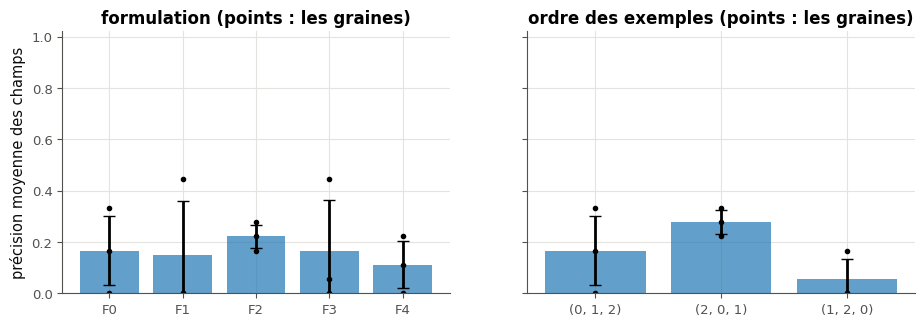

Protocole complet (précalculé par tools/chapters/history_chB4.py) : Qwen2.5-0.5B-Instruct, 8 passages, les mêmes formulations, ordres et graines :
  formulation : moyenne 0,550, écart-type entre les variantes 0,057, écart-type moyen dû aux graines 0,050
  ordre des exemples : moyenne 0,556, écart-type entre les variantes 0,063, écart-type moyen dû aux graines 0,061


In [38]:
grid_f16 = grid_o16 = None
if MODEL_16 is None:
    print("⏳ Ex B4.16 : le modèle n'a pas pu être chargé : l'expérience est « à valider sur Colab ».")
elif written(lambda: spread_16([[0.0]])) and written(lambda: accuracy_16(SYSTEM_15, (), 0)):
    with checked("B4.16"):
        start_16 = time.perf_counter()
        grid_f16 = np.array([[accuracy_16(f, EXAMPLES_15, s) for s in SEEDS_16] for f in FORMULATIONS_16])
        grid_o16 = np.array([[accuracy_16(SYSTEM_15, [EXAMPLES_15[i] for i in order], s) for s in SEEDS_16]
                             for order in ORDERS_16])
        print(f"{len(SNIPPETS_16)} passages, {len(SEEDS_16)} graines, "
              f"{fr(time.perf_counter() - start_16, 0)} s (une mesure)")
        for title, grid, labels in (("formulation", grid_f16, [f"F{i}" for i in range(len(FORMULATIONS_16))]),
                                    ("ordre des exemples", grid_o16, [str(o) for o in ORDERS_16])):
            mean, between, within = spread_16(grid)
            print(f"\n{title} : moyenne {fr(mean, 3)}, écart-type entre les {len(grid)} variantes {fr(between, 3)}, "
                  f"écart-type moyen dû aux graines {fr(within, 3)}")
            for label, row in zip(labels, grid):
                print(f"  {label:10} " + "  ".join(fr(v, 3) for v in row) + f"   moyenne {fr(row.mean(), 3)}")
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
        for ax, grid, labels, title in ((axes[0], grid_f16, [f"F{i}" for i in range(len(FORMULATIONS_16))], "formulation"),
                                        (axes[1], grid_o16, [str(o) for o in ORDERS_16], "ordre des exemples")):
            ax.bar(labels, grid.mean(axis=1), yerr=grid.std(axis=1), capsize=4, color="tab:blue", alpha=0.7)
            for k, row in enumerate(grid):
                ax.plot([k] * len(row), row, "k.", ms=6)
            ax.set_title(f"{title} (points : les graines)")
            ax.set_ylim(0, 1.02)
        axes[0].set_ylabel("précision moyenne des champs")
        plt.show()
        if FAST_MODE and FULL_16:
            print(f"Protocole complet (précalculé par tools/chapters/history_chB4.py) : {FULL_16['model']}, "
                  f"{FULL_16['snippets']} passages, les mêmes formulations, ordres et graines :")
            for title, key in (("formulation", "grid_f"), ("ordre des exemples", "grid_o")):
                grid = np.array(FULL_16[key])
                print(f"  {title} : moyenne {fr(grid.mean(), 3)}, écart-type entre les variantes "
                      f"{fr(grid.mean(axis=1).std(), 3)}, écart-type moyen dû aux graines {fr(grid.std(axis=1).mean(), 3)}")
else:
    print("⏳ Ex B4.16 : l'expérience attend accuracy_16 et spread_16 (et les fonctions de B4.15).")

## Partie B · Recherche et RAG

Un RAG ne répond bien que si la recherche lui montre le bon passage. Tu écris dans `mylearn/retrieval.py` le découpage et BM25 (B4.17), la recherche dense, la fusion RRF et les métriques (B4.18), tu prédis qui de BM25 ou de la recherche dense retrouve des questions paraphrasées (B4.19), tu compares les méthodes sur 30 questions annotées (B4.20), puis tu assembles un RAG complet avec citations vérifiées (B4.21).

**Les questions** (`data/qa/`, data card `data/cards/qa.md`, écrites pour le workbook) : 30 questions factuelles sur les douze nouvelles de Holmes, chacune avec sa réponse courte, des variantes acceptées et son **extrait source** (au plus 21 mots du texte, situé par ses positions de caractères) ; 10 d'entre elles sont **paraphrasées** : aucun de leurs mots-clés n'apparaît dans les 140 mots qui entourent leur extrait. Un chunk est **pertinent** quand il contient l'extrait entier (`wbrag.relevant_ids`) : la vérité ne dépend pas du découpage, et un recouvrement de 20 mots garde chaque extrait entier dans au moins un chunk. S'y ajoutent 10 questions en français sur les chapitres I à VII du *Tour du monde en quatre-vingts jours*, et 5 questions sans réponse dans les nouvelles (la partie suivante s'en sert).

**Contrat commun de `retrieval.py`** (les docstrings, plus ces précisions que vérifient les tests) :
- tes fonctions ne modifient jamais leurs entrées ; les listes sont acceptées partout où un tableau l'est ;
- les valeurs sont comparées à rtol = atol = $10^{-6}$, les identifiants, les indices et les chunks exactement ;
- `cosine_top_k` réutilise ta `cosine_similarity_matrix` de `mylearn/embeddings.py` (B2, 🔨 B2.23) : le stub l'importe. Si ce fichier manque dans ta librairie, la référence le remplace (une ligne ℹ️ le dit) ; s'il existe mais que la fonction n'est pas écrite, les tests qui en dépendent affichent ⏳ en nommant son fichier et son chapitre.

La cellule suivante charge les outils de la partie : `TEST_RET` (le fichier des tests), `QA`, `QA_FR`, `DOCS` et `DOCS_FR` (les nouvelles et les chapitres, `[(titre, texte)]`), `REF_CHUNKS` et `REF_DOC` (le découpage de référence, 120 mots, recouvrement de 20, nouvelle par nouvelle : 1 045 chunks, et la nouvelle de chaque chunk), `tokenize` (les tokens de BM25 : minuscules, suites de lettres et de chiffres ; la **même** fonction pour le corpus et les requêtes).

In [39]:
# Tools for the notebook exercises of part B (retrieval and RAG)
TEST_RET = "tests/test_chb4_retrieval.py"         # the tests of your library retrieval.py
QA = wbrag.load_qa("holmes")                      # the 30 annotated questions on Holmes
QA_FR = wbrag.load_qa("verne")                    # the 10 questions in French on Verne (chapters I to VII)
DOCS = wbrag.documents("holmes")                  # the 12 stories: [(title, text)]
DOCS_FR = wbrag.documents("verne")
REF_CHUNKS, REF_DOC = wbrag.reference_chunks("holmes")   # the reference chunking (120 words, overlap 20)
tokenize = wbrag.tokenize                         # the tokens of BM25: the same for the corpus and the queries
print(f"{len(QA)} questions sur Holmes ({sum(q['paraphrased'] for q in QA)} paraphrasées), {len(QA_FR)} sur Verne ; "
      f"Holmes : {len(DOCS)} nouvelles, {len(REF_CHUNKS)} chunks de référence de 120 mots.")
print("Exemple :", {k: QA[0][k] for k in ("id", "question", "answer", "evidence", "story_title")})

30 questions sur Holmes (10 paraphrasées), 10 sur Verne ; Holmes : 12 nouvelles, 1045 chunks de référence de 120 mots.
Exemple : {'id': 'H01', 'question': "What is the address of Irene Adler's house, according to the King of Bohemia?", 'answer': 'Briony Lodge', 'evidence': '“Is Briony Lodge, Serpentine Avenue, St. John’s Wood.”', 'story_title': 'A Scandal in Bohemia'}


### Ex B4.17 — chunk_text et BM25 : découper un roman et classer ses passages 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire le découpage avec recouvrement et BM25 de ta librairie, puis classer les passages de Holmes.  
**Prérequis :** ✏️ B4.5 · ch. 13 (TF-IDF, 13.30) · fiche §204.6 (« Découper », « De TF-IDF à BM25 ») · **Fil rouge :** Holmes/Verne · **mylearn :** `retrieval.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/retrieval.py` (créé par `python tools/start_chapter.py B4`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb4_retrieval.py -q` les lance tous dans un terminal.

**Contrat**
- `chunk_text(text, chunk_size=200, overlap=50, unit="word")` :
  - les fenêtres de `chunk_size` unités commencent toutes les `chunk_size - overlap` unités, jusqu'à la première qui atteint la fin du texte (la dernière peut être plus courte) ; un texte d'exactement `chunk_size` unités donne **un seul** chunk ;
  - `unit="word"` : le texte coupé aux blancs (`split()`), chaque chunk recollé avec une seule espace ; `unit="char"` : **chaque caractère** est une unité, espaces et retours à la ligne compris, sans aucune normalisation (le « whitespace-normalised » de la docstring ne concerne que l'unité `"word"`) ;
  - les arguments sont vérifiés **avant** tout calcul : `ValueError` si `chunk_size < 1`, `overlap < 0` ou `overlap >= chunk_size` (la fenêtre n'avancerait pas : les tests passent par une garde qui arrête une boucle sans fin), ou pour une unité inconnue.
- `BM25(k1=1.5, b=0.75)`, `fit(corpus)`, `get_scores(query)` : la formule de la fiche, avec l'idf toujours positif $\ln\big(1 + \frac{N - n_t + 0{,}5}{n_t + 0{,}5}\big)$ :
  - `fit` reçoit des documents déjà tokenisés (des listes de chaînes), apprend `idf_` (un dictionnaire, une entrée par terme du corpus), `doc_len_` (un tableau NumPy), `avgdl_`, `n_docs_` et `term_freqs_` (une liste de dictionnaires, un par document), et rend `self` ; un second `fit` remplace toutes les statistiques ;
  - le corpus peut contenir des documents vides : ils comptent dans $N$ et dans $\overline{|d|}$, et leur score est 0 ;
  - `get_scores` rend un tableau NumPy de flottants de forme `(n_docs,)` ; un document qui ne contient pas un terme de la requête reçoit **0** de ce terme, y compris avec `k1 = 0` ou pour un document vide avec `b = 1` : un dénominateur nul donne 0, jamais NaN ; les tokens sont comparés tels quels (casse comprise) ;
  - `ValueError` pour `get_scores` avant `fit`, un corpus vide, `k1 < 0` ou `b` hors de $[0, 1]$ (ces deux-là peuvent être refusés dès le constructeur ou par `fit`).

La première cellule de vérification essaie `chunk_text` sur l'exemple de la fiche, un texte d'exactement `chunk_size` mots, l'unité `"char"` et un refus ; BM25 sur les quatre documents de la fiche (contre un calcul de référence), le cas `k1 = 0` avec un document vide et un refus ; puis elle découpe les douze nouvelles de Holmes (120 mots, recouvrement de 20 : les chunks doivent être ceux de `REF_CHUNKS`) et affiche les trois passages que ton BM25 classe en tête pour « violin music concert ». La seconde lance les 62 tests de l'exercice (`-k "test_chunk_text_ or test_bm25_"`).

Dans tes notes : combien de chunks donne la formule de la fiche pour une nouvelle de $n$ mots, et pourquoi le total (1 045) dépasse-t-il le nombre de mots divisé par 100 ? Pourquoi un recouvrement de 20 mots garde-t-il entier tout extrait de 21 mots au plus ? Les trois passages de « violin music concert » parlent-ils tous de musique, et lequel des quatre morceaux de la formule de BM25 explique le premier ?

In [40]:
with checked("B4.17"):
    R = mylearn.retrieval
    sentence_17 = "Le docteur Watson prend son chapeau et suit Holmes dans la rue sombre"
    copy_17 = str(sentence_17)
    chunks_17 = R.chunk_text(sentence_17, chunk_size=5, overlap=2)
    want_17 = ["Le docteur Watson prend son", "prend son chapeau et suit", "et suit Holmes dans la", "dans la rue sombre"]
    verdict("B4.17", chunks_17 == want_17, "chunk_text : l'exemple de la fiche (5 mots, recouvrement de 2).",
            f"chunk_text(phrase, 5, 2) devrait rendre {want_17} ; reçu {chunks_17!r}.")
    verdict("B4.17", R.chunk_text("un  deux\ntrois", chunk_size=3, overlap=0) == ["un deux trois"],
            "un texte d'exactement chunk_size mots donne un seul chunk, les blancs réduits à une espace.",
            f"chunk_text('un  deux\\ntrois', 3, 0) devrait rendre ['un deux trois'] ; reçu "
            f"{R.chunk_text('un  deux' + chr(10) + 'trois', chunk_size=3, overlap=0)!r}.")
    chars_17 = R.chunk_text("ab\ncd ef", chunk_size=3, overlap=1, unit="char")
    verdict("B4.17", chars_17 == ["ab\n", "\ncd", "d e", "ef"],
            "unité 'char' : chaque caractère compte, espaces et retours à la ligne compris, sans rien retirer.",
            f"chunk_text('ab\\ncd ef', 3, 1, unit='char') devrait rendre ['ab\\n', '\\ncd', 'd e', 'ef'] (aucun "
            f"blanc retiré) ; reçu {chars_17!r}.")
    refuses("B4.17", "chunk_text(texte, chunk_size=0)", lambda: R.chunk_text("a b", chunk_size=0, overlap=0))

    docs_17 = ["holmes fume sa pipe", "watson lit le journal et holmes joue du violon", "le violon de holmes",
               "watson écrit"]
    corpus_17 = [d.split() for d in docs_17]
    bm_17 = R.BM25(k1=1.5, b=0.75).fit(corpus_17)
    if bm_17 is None:
        print("❌ Ex B4.17 : BM25.fit renvoie None : fit doit rendre self.")
        raise StopCheck
    want_bm_17 = wbrag.BM25Index(corpus_17).scores(["holmes", "violon"])
    same("B4.17", "BM25 sur les quatre documents de la fiche, requête « holmes violon »",
         bm_17.get_scores(["holmes", "violon"]), want_bm_17, rtol=1e-6, atol=1e-6)
    zero_17 = R.BM25(k1=0.0, b=1.0).fit([["a", "b"], [], ["b"]]).get_scores(["a", "c"])
    verdict("B4.17", np.all(np.isfinite(zero_17)) and np.asarray(zero_17)[1:].tolist() == [0.0, 0.0],
            "k1 = 0 et un document vide : des 0, jamais NaN.",
            f"avec k1 = 0, b = 1 et un document vide, les documents sans le terme doivent recevoir 0 (jamais NaN) ; "
            f"reçu {np.asarray(zero_17).tolist()}.")
    refuses("B4.17", "get_scores avant fit", lambda: R.BM25().get_scores(["a"]))

    # the real use: Holmes cut into chunks of 120 words, and the passages that BM25 ranks first
    holmes_17 = [c for _, body in DOCS for c in R.chunk_text(body, chunk_size=120, overlap=20)]
    verdict("B4.17", holmes_17 == REF_CHUNKS, f"Holmes : {len(holmes_17)} chunks, ceux de la référence.",
            f"sur les 12 nouvelles, chunk_text(texte, 120, 20) devrait donner {len(REF_CHUNKS)} chunks, ceux de "
            f"wbrag.reference_chunks ; reçu {len(holmes_17)} chunks.")
    index_17 = R.BM25().fit([tokenize(c) for c in holmes_17])
    scores_17 = np.asarray(index_17.get_scores(tokenize("violin music concert")))
    for rank_17, i_17 in enumerate(np.argsort(-scores_17, kind="stable")[:3], start=1):
        print(f"  {rank_17}. score {fr(scores_17[i_17], 2)} · {DOCS[REF_DOC[i_17]][0]} · {holmes_17[i_17][:110]}…")

✅ Ex B4.17 : chunk_text : l'exemple de la fiche (5 mots, recouvrement de 2).
✅ Ex B4.17 : un texte d'exactement chunk_size mots donne un seul chunk, les blancs réduits à une espace.
✅ Ex B4.17 : unité 'char' : chaque caractère compte, espaces et retours à la ligne compris, sans rien retirer.
✅ Ex B4.17 : chunk_text(texte, chunk_size=0) : ValueError levée (chunk_size must be >= 1, got 0).
✅ Ex B4.17 : BM25 sur les quatre documents de la fiche, requête « holmes violon » : [0.38395603, 0.74846605, 1.13012013, 0.0], comme attendu.
✅ Ex B4.17 : k1 = 0 et un document vide : des 0, jamais NaN.
✅ Ex B4.17 : get_scores avant fit : ValueError levée (this BM25 is not fitted yet: call fit(corpus) first).
✅ Ex B4.17 : Holmes : 1045 chunks, ceux de la référence.
  1. score 6,55 · The Red-Headed League · assistant answered it. We have had some skirmishes, but we had never set eyes upon each other before. I hardly…
  2. score 5,87 · The Noble Bachelor · with no very good result,” I remarked. “His cond

In [41]:
if written(lambda: mylearn.retrieval.chunk_text('a b', 1, 0)):
    run_pytest_group(TEST_RET, impl="ref", keyword="test_chunk_text_ or test_bm25_")   # 62 tests
else:
    print("⏳ Ex B4.17 : les tests attendent tes fonctions.")

pytest: 62 passed, 67 deselected in 1.28s


### Ex B4.18 — cosine_top_k, fusion de classements (RRF), recall@k et MRR 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire la recherche dense exhaustive, la fusion RRF et les deux métriques de recherche de ta librairie.  
**Prérequis :** ✏️ B4.2 · B2 (`cosine_similarity_matrix`, 🔨 B2.23) · fiche §204.6 (« La recherche dense », « La recherche hybride et la fusion RRF », « Mesurer une recherche : recall@k et MRR ») · **Fil rouge :** Holmes/Verne · **mylearn :** `retrieval.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/retrieval.py` (créé par `python tools/start_chapter.py B4`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy et la bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb4_retrieval.py -q` les lance tous dans un terminal.

**Contrat**
- `cosine_top_k(query_emb, doc_embs, k=5)` rend `(indices, similarities)`, deux tableaux NumPy (des entiers, des flottants), de forme `(k,)` pour une requête `(d,)` et `(q, k)` pour des requêtes `(q, d)` : les $k$ documents de plus grand cosinus, triés par similarité décroissante, les ex aequo départagés par le **plus petit** indice ; un vecteur nul a une similarité de **0** avec tout, comme dans ta `cosine_similarity_matrix` (la réutiliser évite le NaN : un cosinus maison sans `eps` échoue) ; `ValueError` si `k < 1`, si `k > n` (contrairement à `most_similar` de B2, qui tronquait) ou si les dimensions diffèrent.
- `reciprocal_rank_fusion(rankings, k=60)` : le score de chaque identifiant est $\sum_r 1/(k + \operatorname{rang}_r)$, les rangs à partir de 1 ; rend un tableau NumPy d'identifiants **entiers**, du meilleur score au moins bon, à égalité le plus petit identifiant d'abord ; les classements peuvent avoir des longueurs différentes, être vides, ou être des tableaux NumPy (les lignes rendues par `cosine_top_k`) ; une fusion vide (`[[]]`, `[[], []]`) rend un tableau d'entiers de forme `(0,)` (`np.array([])` serait un tableau de flottants) ; `ValueError` si `rankings` est vide ou si `k < 0`.
- `recall_at_k(retrieved, relevant, k)` et `mean_reciprocal_rank(retrieved, relevant)` :
  - `retrieved` : une liste d'identifiants par requête, ou le tableau 2-D d'indices que rend `cosine_top_k` (teste `len(retrieved) == 0`, pas `not retrieved`) ; dans chaque liste, les identifiants sont distincts ; une liste peut être plus courte que `k` ;
  - `relevant` : un ensemble, une liste ou un tuple d'identifiants par requête ;
  - recall@k est la moyenne de $|\text{top-}k \cap \text{pertinents}| / |\text{pertinents}|$ (une intersection d'ensembles) ; `ValueError` si les longueurs diffèrent, si `k < 1` ou si un ensemble pertinent est vide ;
  - le MRR est la moyenne de $1/\text{rang}$ du premier pertinent, 0 quand aucun n'est retrouvé ; une requête dont l'ensemble pertinent est vide compte 0, **sans** erreur (contrairement à `recall_at_k`) ; `ValueError` si les longueurs diffèrent ;
  - les deux rendent un nombre.

La première cellule de vérification essaie `cosine_top_k` sur l'exemple de la fiche, un vecteur nul et un refus, la fusion de la fiche et une fusion vide, recall@1, recall@3 et MRR de l'exemple de la fiche, puis les métriques sur un tableau rendu par `cosine_top_k` et avec un ensemble pertinent vide. La seconde lance les 67 tests de l'exercice (`-k "test_cosine_top_k_ or test_reciprocal_rank_fusion_ or test_recall_at_k_ or test_mean_reciprocal_rank_"`).

Dans tes notes : pourquoi le plus grand cosinus est-il aussi le plus proche voisin euclidien pour des vecteurs de norme 1 (fiche §204.6) ? Que deviendrait la fusion de la fiche avec $k = 0$, et pourquoi Cormack et ses coauteurs prennent-ils $k = 60$ ? Pourquoi le recall@k refuse-t-il un ensemble pertinent vide, alors que le MRR l'accepte ?

In [42]:
with checked("B4.18"):
    R = mylearn.retrieval
    D_18 = np.array([[1., 3.], [3., 1.], [1., 0.], [-1., -1.]])
    out_18 = R.cosine_top_k([1., 1.], D_18, k=3)
    idx_18, sims_18 = pair("B4.18", "cosine_top_k", out_18, names=("indices", "similarities"))
    verdict("B4.18", np.asarray(idx_18).tolist() == [0, 1, 2], "cosine_top_k : l'exemple de la fiche, ex aequo au plus "
            "petit indice.", f"cosine_top_k([1, 1], D, k=3) devrait rendre les indices [0, 1, 2] ; reçu {np.asarray(idx_18).tolist()}.")
    same("B4.18", "similarités de l'exemple de la fiche", sims_18, [2 / np.sqrt(5)] * 2 + [1 / np.sqrt(2)], rtol=1e-6, atol=1e-6)
    _, zero_18 = R.cosine_top_k([1., 1.], np.array([[0., 0.], [1., 0.]]), k=2)
    verdict("B4.18", np.all(np.isfinite(zero_18)) and 0.0 in np.round(np.asarray(zero_18), 12),
            "un vecteur nul a une similarité de 0 (pas de NaN).",
            f"un document nul doit recevoir une similarité de 0, jamais NaN ; reçu {np.asarray(zero_18).tolist()}.")
    refuses("B4.18", "cosine_top_k avec k > n", lambda: R.cosine_top_k([1., 1.], D_18, k=5))
    fused_18 = R.reciprocal_rank_fusion([[7, 2, 9, 4], [2, 5, 7, 1]], k=60)
    verdict("B4.18", np.asarray(fused_18).tolist() == [2, 7, 5, 9, 1, 4],
            "reciprocal_rank_fusion : l'exemple de la fiche, [2, 7, 5, 9, 1, 4].",
            f"la fusion de [7, 2, 9, 4] et [2, 5, 7, 1] (k = 60) devrait rendre [2, 7, 5, 9, 1, 4] ; reçu "
            f"{np.asarray(fused_18).tolist()}.")
    empty_18 = np.asarray(R.reciprocal_rank_fusion([[]]))
    verdict("B4.18", empty_18.shape == (0,) and np.issubdtype(empty_18.dtype, np.integer),
            "une fusion vide rend un tableau d'entiers de forme (0,).",
            f"reciprocal_rank_fusion([[]]) doit rendre un tableau d'entiers vide ; reçu {empty_18!r}.")
    retrieved_18, relevant_18 = [[4, 8, 1, 3], [2, 6, 5, 0], [7, 3, 0, 5]], [{1}, {2, 9}, {6}]
    same("B4.18", "recall@1, recall@3 et MRR de l'exemple de la fiche",
         [R.recall_at_k(retrieved_18, relevant_18, 1), R.recall_at_k(retrieved_18, relevant_18, 3),
          R.mean_reciprocal_rank(retrieved_18, relevant_18)], [1 / 6, 0.5, 4 / 9], rtol=1e-9, atol=1e-12)
    rows_18, _ = R.cosine_top_k(np.eye(3)[:2], np.eye(3), k=2)              # a 2-D array of indices, as in B4.20
    same("B4.18", "recall@1 sur le tableau 2-D rendu par cosine_top_k", R.recall_at_k(rows_18, [{0}, {2}], 1), 0.5,
         rtol=1e-9, atol=1e-12)
    same("B4.18", "MRR avec un ensemble pertinent vide (la requête compte 0)",
         R.mean_reciprocal_rank([[1, 2], [3]], [{2}, set()]), 0.25, rtol=1e-9, atol=1e-12)

✅ Ex B4.18 : cosine_top_k : l'exemple de la fiche, ex aequo au plus petit indice.
✅ Ex B4.18 : similarités de l'exemple de la fiche : [0.89442719, 0.89442719, 0.70710678], comme attendu.
✅ Ex B4.18 : un vecteur nul a une similarité de 0 (pas de NaN).
✅ Ex B4.18 : cosine_top_k avec k > n : ValueError levée (k must be <= the number of documents 4, got 5).
✅ Ex B4.18 : reciprocal_rank_fusion : l'exemple de la fiche, [2, 7, 5, 9, 1, 4].
✅ Ex B4.18 : une fusion vide rend un tableau d'entiers de forme (0,).
✅ Ex B4.18 : recall@1, recall@3 et MRR de l'exemple de la fiche : [0.16666667, 0.5, 0.44444444], comme attendu.
✅ Ex B4.18 : recall@1 sur le tableau 2-D rendu par cosine_top_k : 0.5, comme attendu.
✅ Ex B4.18 : MRR avec un ensemble pertinent vide (la requête compte 0) : 0.25, comme attendu.


In [43]:
if written(lambda: mylearn.retrieval.recall_at_k([[0]], [{0}], 1)):
    run_pytest_group(TEST_RET, impl="ref", keyword="test_cosine_top_k_ or test_reciprocal_rank_fusion_ or test_recall_at_k_ or test_mean_reciprocal_rank_")   # 67 tests
else:
    print("⏳ Ex B4.18 : les tests attendent tes fonctions.")

pytest: 67 passed, 62 deselected in 1.36s


### Ex B4.19 — Prédire : sur des questions paraphrasées, BM25 ou recherche dense gagne-t-elle ? 🔮 ★ ⏱️ 10 min
**Objectif :** prédire combien de questions paraphrasées BM25, la recherche dense et l'hybride retrouvent sur Holmes.  
**Prérequis :** Ex B4.17 · Ex B4.18 · 🧠 Q9 · fiche §204.6 (« La recherche dense », « La recherche hybride et la fusion RRF ») · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

Les 10 questions paraphrasées de `QA` ne partagent aucun mot-clé avec le texte qui entoure leur réponse : « How many big gems decorate the royal headpiece? » cherche un passage qui parle de « beryls » et de « coronet ». L'expérience découpe les douze nouvelles avec ton `chunk_text` (120 mots, recouvrement de 20), indexe les chunks avec ton `BM25` (sur `tokenize`) et avec all-MiniLM-L6-v2 (la recherche dense de B2 : environ 40 s d'embeddings la première fois, puis le cache), et cherche chaque question de trois façons : BM25, la recherche dense (ton `cosine_top_k`), et l'**hybride**, ta `reciprocal_rank_fusion` ($k = 60$) des 20 premiers résultats des deux. Pour chaque méthode, elle compte les questions dont le chunk pertinent est dans les **5 premiers** résultats.

**Avant d'exécuter**, écris tes trois prédictions :
- a) `bm25_half_19` : BM25 retrouve-t-il au moins 5 des 10 questions dans ses 5 premiers résultats ? `True` ou `False` ;
- b) `dense_half_19` : et la recherche dense ? `True` ou `False` ;
- c) `hybrid_best_19` : l'hybride en retrouve-t-il **au moins autant** que la meilleure des deux ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes prédictions ne sont pas écrites ; elle appelle ton code de B4.17 et B4.18, et ne vérifie tes prédictions que si elle a pu tourner. Elle affiche, pour chaque question, le rang du chunk pertinent dans chaque méthode, puis les trois comptes.

In [44]:
SM_19 = wb.text.try_sentence_model("minilm", "B4.19")      # all-MiniLM-L6-v2 (B2), frozen; None if unavailable
PARA_19 = [q for q in QA if q["paraphrased"]]                # the 10 paraphrased questions
for q in PARA_19[:3]:
    print(f"{q['id']} · {q['question']}  →  {q['story_title']}")

H21 · How many stairs go up to the lodgings where the two friends live?  →  A Scandal in Bohemia
H22 · What venomous animal kills the villain at the end?  →  The Speckled Band
H23 · What is the huge guard dog called?  →  The Copper Beeches


In [45]:
bm25_half_19, dense_half_19, hybrid_best_19 = False, False, True

In [46]:
wb.record("B4.19a", False, mistakes={"relis la dernière ligne : combien de questions BM25 retrouve-t-il dans ses 5 premiers résultats ?": True})
wb.record("B4.19b", False, mistakes={"relis la dernière ligne : combien de questions la recherche dense retrouve-t-elle dans ses 5 premiers résultats ?": True})
wb.record("B4.19c", True, mistakes={"compare, sur la dernière ligne, le compte de l’hybride à celui de la meilleure des deux autres": False})

WB_ANSWER {"hash": "128754b2dd17dd6d4e43c8691a6f0b3f11df2ae8a68d69b495682eebde835bde", "id": "B4.19a", "kind": "bool", "mistakes": {"076f4288bec0133bfd4b65bc718f9d88d95fef46fbeb5c12257798e3bea7dc90": "relis la dernière ligne : combien de questions BM25 retrouve-t-il dans ses 5 premiers résultats ?"}}
📝 Ex B4.19a : réponse enregistrée (bool).
WB_ANSWER {"hash": "f8ca3b351d71a869dee20aca99395abd1f0ddc2653f9430746b36e4d1d2c4175", "id": "B4.19b", "kind": "bool", "mistakes": {"72e9a9667393d0b3dd791a60fd7047215d772354ddcf018b46ad781e325dd5e6": "relis la dernière ligne : combien de questions la recherche dense retrouve-t-elle dans ses 5 premiers résultats ?"}}
📝 Ex B4.19b : réponse enregistrée (bool).
WB_ANSWER {"hash": "7ae1cdd727087e46342556f833993c13e60655dcfd87f6b6074dc697b205ec94", "id": "B4.19c", "kind": "bool", "mistakes": {"2a563789b887501ba5304889314a50c2f3c05686cc4150005ba6948f1dd0e0fb": "compare, sur la dernière ligne, le compte de l’hybride à celui de la meilleure des deux autres"

In [47]:
if any(answer is ... or answer is None for answer in [bm25_half_19, dense_half_19, hybrid_best_19]):
    print("⏳ Ex B4.19 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    found_19 = None
    if SM_19 is None:
        print("⏳ Ex B4.19 : MiniLM n'a pas pu être chargé : l'expérience est « à valider sur Colab ».")
    else:
        with checked("B4.19"):
            R = mylearn.retrieval
            chunks_19 = [c for _, body in DOCS for c in R.chunk_text(body, chunk_size=120, overlap=20)]
            if chunks_19 != REF_CHUNKS:
                print("❌ Ex B4.19 : ton chunk_text ne rend pas le découpage de référence (B4.17) : l'expérience attend.")
                raise StopCheck
            bm25_19 = R.BM25().fit([tokenize(c) for c in chunks_19])
            start_19 = time.perf_counter()
            emb_19 = wb.text.passage_embeddings(SM_19, chunks_19, "b4-holmes-120-20")   # ≈ 40 s the first time, then cached
            print(f"embeddings des {len(chunks_19)} chunks : {fr(time.perf_counter() - start_19, 1)} s")
            found_19 = {"BM25": 0, "dense (MiniLM)": 0, "hybride (RRF)": 0}
            print(f"\n{'question':58} rang du chunk pertinent : BM25 · dense · hybride (« — » : au-delà de 20)")
            for item in PARA_19:
                relevant = wbrag.relevant_ids(chunks_19, item)
                bm = np.argsort(-np.asarray(bm25_19.get_scores(tokenize(item["question"]))), kind="stable")[:20]
                dense, _ = R.cosine_top_k(SM_19.embed([item["question"]], kind="query")[0], emb_19, k=20)
                hybrid = np.asarray(R.reciprocal_rank_fusion([bm, dense], k=60))[:20]
                ranks = []
                for name, ranking in zip(found_19, (bm, dense, hybrid)):
                    rank = next((r for r, i in enumerate(np.asarray(ranking).tolist(), start=1) if i in relevant), None)
                    found_19[name] += rank is not None and rank <= 5
                    ranks.append("—" if rank is None else str(rank))
                print(f"{item['question'][:58]:58} {' · '.join(ranks)}")
            print("\nRetrouvées dans les 5 premiers résultats, sur 10 :", found_19)
    if found_19 is not None:
        wb.check("B4.19a", bm25_half_19)
        wb.check("B4.19b", dense_half_19)
        wb.check("B4.19c", hybrid_best_19)
    else:
        print("⏳ Ex B4.19 : tes prédictions seront vérifiées quand l'expérience aura tourné (B4.17 et B4.18, puis MiniLM).")

ℹ️ embeddings relus dans le cache (sentence-transformers_all-MiniLM-L6-v2-b4-holmes-120-20-267a2938f81b1993.npz)
embeddings des 1045 chunks : 0,0 s

question                                                   rang du chunk pertinent : BM25 · dense · hybride (« — » : au-delà de 20)
How many stairs go up to the lodgings where the two friend 2 · 7 · 1
What venomous animal kills the villain at the end?         — · 1 · 3


What is the huge guard dog called?                         — · 1 · 5


How much payment was promised for the late-evening job?    — · 8 · 16
How many big gems decorate the royal headpiece?            — · — · —
In which American city did the bride's father live?        — · — · —


In which gold-mining town of the antipodes was the killer  — · — · —
How much did the young woman get for each typed page?      — · 10 · 20


At what times did the copying job start and finish?        — · 10 · 19


Which aristocratic lady had the jewel stolen from her?     — · — · —

Retrouvées dans les 5 premiers résultats, sur 10 : {'BM25': 1, 'dense (MiniLM)': 2, 'hybride (RRF)': 3}
✅ Ex B4.19a : Bien joué !
✅ Ex B4.19b : C'est ça !
✅ Ex B4.19c : Parfait !


Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Regarde une question que la recherche dense rate : à quel rang est son chunk, et que contient le premier chunk trouvé à sa place ? Pourquoi un modèle d'embedding entraîné sur des phrases modernes peut-il ne pas rapprocher « headpiece » de « coronet » dans un passage de 120 mots du XIXᵉ siècle ? Que dit la fusion d'un document classé loin par les deux méthodes ?

### Ex B4.20 — Recherche dense (MiniLM, e5) contre BM25 contre hybride sur 30 questions annotées 📦 ★★★ ⏱️ 45 min
**Objectif :** écrire un index et une recherche à trois méthodes avec ta librairie, et les évaluer sur Holmes et Verne.  
**Prérequis :** Ex B4.19 · B2 (MiniLM, e5 et ses préfixes, 📦 B2.28) · fiche §204.6 (« La recherche dense », « La recherche hybride et la fusion RRF », « Mesurer une recherche : recall@k et MRR ») · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

**Contrat** (avec ta librairie `mylearn.retrieval`, tes fonctions de B4.17 et B4.18)
- `build_index_20(chunks, sentence_model, subset)` rend le dictionnaire `{"chunks", "bm25", "model", "embeddings"}` : les chunks, ton `BM25` ajusté sur `[tokenize(c) for c in chunks]`, le modèle reçu, et les embeddings des chunks, `wb.text.passage_embeddings(sentence_model, chunks, subset)` (B2 : le préfixe « passage: » pour e5, la moyenne masquée puis la norme 1, calculés une fois puis relus du cache sous le nom `subset`).
- `search_20(index, query, method="hybrid", k=5)` rend la liste des $k$ meilleurs identifiants de chunks (des `int` Python, le meilleur d'abord) :
  - `"bm25"` : les scores de ton BM25 pour `tokenize(query)`, triés par score décroissant, à égalité le plus petit identifiant (un tri stable) ;
  - `"dense"` : ton `cosine_top_k` de `index["model"].embed([query], kind="query")[0]` (le préfixe « query: » pour e5) contre les embeddings ;
  - `"hybrid"` : ta `reciprocal_rank_fusion` ($k = 60$) des `DEPTH_20` (20) premiers résultats de BM25 et de la recherche dense, coupée aux $k$ premiers ;
  - `ValueError` pour une autre méthode.
- `evaluate_20(index, items, method)` rend `{"recall@1", "recall@5", "mrr"}`, trois `float` Python : pour chaque question de `items`, les `DEPTH_20` premiers résultats de `search_20` et ses chunks pertinents, `wbrag.relevant_ids(index["chunks"], item)` ; puis ton `recall_at_k` (à 1 et à 5) et ton `mean_reciprocal_rank`.

La cellule de vérification construit ton index des chunks de référence avec MiniLM (les embeddings de B4.19, relus du cache), compare `search_20` à la recherche de référence (`wbrag.ReferenceIndex`) sur deux questions et trois méthodes, essaie un refus, et compare `evaluate_20` à un calcul de référence sur six questions. L'expérience évalue ensuite les trois méthodes sur Holmes avec MiniLM (les 30 questions, les 20 directes, les 10 paraphrasées), puis sur Verne avec e5 et avec MiniLM (les 10 questions en français ; environ 15 s d'embeddings e5 la première fois). Elle affiche aussi, précalculés, les résultats d'e5 sur Holmes (`E5_HOLMES_20` : environ 1 min d'embeddings sur CPU).

Dans tes notes : sur Holmes, quelle méthode préfères-tu, et sur quel groupe de questions la différence se joue-t-elle ? Le recall@1 et le recall@5 classent-ils les méthodes dans le même ordre ? Sur Verne, que gagne un modèle multilingue, et pourquoi MiniLM, entraîné sur de l'anglais, s'en sort-il si mal ? Avec 10 ou 30 questions, quel écart de recall@5 jugerais-tu significatif (fiche §204.5) ?

In [48]:
DEPTH_20 = 20     # the hybrid search fuses the first 20 results of BM25 and of the dense search (RRF, k = 60)
SM_E5 = wb.text.try_sentence_model("e5", "B4.20")      # multilingual-e5-small (B2): « query: » and « passage: »
# e5 on Holmes (precomputed by tools/chapters/history_chB4.py with the solution of this exercise): (method, questions, scores)
E5_HOLMES_20 = [
    ('bm25', '30 questions', {'recall@1': 0.35, 'recall@5': 0.5333333333333333, 'mrr': 0.4518233618233618}),
    ('bm25', '20 directes', {'recall@1': 0.525, 'recall@5': 0.75, 'mrr': 0.6527350427350427}),
    ('bm25', '10 paraphrasées', {'recall@1': 0.0, 'recall@5': 0.1, 'mrr': 0.05}),
    ('dense', '30 questions', {'recall@1': 0.15, 'recall@5': 0.6333333333333333, 'mrr': 0.37375402031748783}),
    ('dense', '20 directes', {'recall@1': 0.225, 'recall@5': 0.8, 'mrr': 0.49095399698340875}),
    ('dense', '10 paraphrasées', {'recall@1': 0.0, 'recall@5': 0.3, 'mrr': 0.13935406698564592}),
    ('hybrid', '30 questions', {'recall@1': 0.25, 'recall@5': 0.5333333333333333, 'mrr': 0.4147895622895622}),
    ('hybrid', '20 directes', {'recall@1': 0.375, 'recall@5': 0.7, 'mrr': 0.5816287878787878}),
    ('hybrid', '10 paraphrasées', {'recall@1': 0.0, 'recall@5': 0.2, 'mrr': 0.0811111111111111}),
]

In [49]:
def build_index_20(chunks, sentence_model, subset):
    """BM25 and the dense embeddings of the chunks."""
    R = mylearn.retrieval
    return {"chunks": list(chunks), "bm25": R.BM25().fit([tokenize(c) for c in chunks]), "model": sentence_model,
            "embeddings": wb.text.passage_embeddings(sentence_model, list(chunks), subset)}


def search_20(index, query, method="hybrid", k=5):
    """The ids of the k best chunks: BM25, dense, or their RRF fusion."""
    R = mylearn.retrieval
    if method not in ("bm25", "dense", "hybrid"):
        raise ValueError(f"unknown method {method!r}")
    depth = max(k, DEPTH_20)
    if method in ("bm25", "hybrid"):
        scores = np.asarray(index["bm25"].get_scores(tokenize(query)))
        bm = np.argsort(-scores, kind="stable")[:depth]
    if method in ("dense", "hybrid"):
        q = index["model"].embed([query], kind="query")[0]
        dense, _ = R.cosine_top_k(q, index["embeddings"], k=min(depth, len(index["chunks"])))
    if method == "bm25":
        return bm[:k].tolist()
    if method == "dense":
        return np.asarray(dense)[:k].tolist()
    return np.asarray(R.reciprocal_rank_fusion([bm[:DEPTH_20], dense[:DEPTH_20]], k=60))[:k].tolist()


def evaluate_20(index, items, method):
    """recall@1, recall@5 and MRR over the first DEPTH_20 results."""
    R = mylearn.retrieval
    retrieved = [search_20(index, item["question"], method, DEPTH_20) for item in items]
    relevant = [wbrag.relevant_ids(index["chunks"], item) for item in items]
    return {"recall@1": float(R.recall_at_k(retrieved, relevant, 1)),
            "recall@5": float(R.recall_at_k(retrieved, relevant, 5)),
            "mrr": float(R.mean_reciprocal_rank(retrieved, relevant))}


INDEX_20 = None
if SM_19 is None:
    print("⏳ Ex B4.20 : MiniLM n'a pas pu être chargé : l'exercice est « à valider sur Colab ».")
else:
    with checked("B4.20"):
        INDEX_20 = build_index_20(REF_CHUNKS, SM_19, "b4-holmes-120-20")
        if returned("B4.20", "build_index_20", INDEX_20):
            if not (isinstance(INDEX_20, dict) and {"chunks", "bm25", "model", "embeddings"} <= set(INDEX_20)):
                print("❌ Ex B4.20 : build_index_20 doit rendre un dictionnaire aux clés chunks, bm25, model, embeddings.")
                INDEX_20 = None
                raise StopCheck
            emb_20 = np.asarray(INDEX_20["embeddings"])
            verdict("B4.20", emb_20.shape == (len(REF_CHUNKS), 384), f"embeddings {emb_20.shape}.",
                    f"les embeddings doivent avoir la forme ({len(REF_CHUNKS)}, 384) ; reçu {emb_20.shape}.")
        else:
            INDEX_20 = None
    if INDEX_20 is not None:
        ref_20 = wbrag.ReferenceIndex(REF_CHUNKS, SM_19, subset="b4-holmes-120-20")
        with checked("B4.20"):
            for q_20 in (QA[1], QA[22]):
                for method_20 in ("bm25", "dense", "hybrid"):
                    got_20, want_20 = search_20(INDEX_20, q_20["question"], method_20, 5), ref_20.search(q_20["question"], method_20, 5)
                    verdict("B4.20", list(np.asarray(got_20).tolist()) == want_20,
                            f"search_20 ({method_20}, {q_20['id']}) : {want_20}",
                            f"search_20(index, {q_20['question']!r}, {method_20!r}, 5) devrait rendre {want_20} ; "
                            f"reçu {np.asarray(got_20).tolist()}.")
            ties_20 = search_20(INDEX_20, "xyzzy", "bm25", 5)          # an unknown word: every score is 0
            verdict("B4.20", list(np.asarray(ties_20).tolist()) == [0, 1, 2, 3, 4],
                    "BM25 : à égalité de score, le plus petit identifiant d'abord.",
                    f"search_20(index, 'xyzzy', 'bm25', 5) : tous les scores sont nuls, attendu [0, 1, 2, 3, 4] (un tri "
                    f"stable par score décroissant) ; reçu {np.asarray(ties_20).tolist()}.")
            refuses("B4.20", "search_20 avec une méthode inconnue", lambda: search_20(INDEX_20, "x", "tfidf", 5))
        if SM_E5 is not None:                    # e5 needs « query: » before a query: Verne, chapters I to VII
            with checked("B4.20"):
                chunks_v20 = [c for _, body in DOCS_FR for c in wbrag.chunk_words(body)]
                index_v20 = build_index_20(chunks_v20, SM_E5, "b4-verne-120-20")
                ref_v20 = wbrag.ReferenceIndex(chunks_v20, SM_E5, subset="b4-verne-120-20")
                got_v20 = [list(np.asarray(search_20(index_v20, q["question"], "dense", 5)).tolist()) for q in QA_FR]
                want_v20 = [ref_v20.search(q["question"], "dense", 5) for q in QA_FR]
                verdict("B4.20", got_v20 == want_v20, "e5 sur Verne : la recherche dense de référence, préfixes compris.",
                        "avec e5, ta recherche dense ne rend pas celle de la référence sur les 10 questions de Verne : "
                        "relis le contrat de search_20 (l'embedding de la requête).")
        with checked("B4.20"):
            got_e20 = evaluate_20(INDEX_20, QA[:6], "hybrid")
            ret_e20 = [ref_20.search(q["question"], "hybrid", DEPTH_20) for q in QA[:6]]
            rel_e20 = [wbrag.relevant_ids(REF_CHUNKS, q) for q in QA[:6]]
            first_e20 = [next((r for r, i in enumerate(ret, 1) if i in rel), None) for ret, rel in zip(ret_e20, rel_e20)]
            want_e20 = {"recall@1": float(np.mean([f == 1 for f in first_e20])),
                        "recall@5": float(np.mean([len(set(ret[:5]) & rel) / len(rel) for ret, rel in zip(ret_e20, rel_e20)])),
                        "mrr": float(np.mean([1 / f if f else 0.0 for f in first_e20]))}
            if returned("B4.20", "evaluate_20", got_e20):
                same("B4.20", "evaluate_20 (hybride, 6 questions) : recall@1, recall@5, MRR",
                     [got_e20.get(k) for k in ("recall@1", "recall@5", "mrr")], list(want_e20.values()), rtol=1e-9)

ℹ️ embeddings relus dans le cache (sentence-transformers_all-MiniLM-L6-v2-b4-holmes-120-20-267a2938f81b1993.npz)
✅ Ex B4.20 : embeddings (1045, 384).
✅ Ex B4.20 : search_20 (bm25, H02) : [41, 48, 58, 47, 81]
✅ Ex B4.20 : search_20 (dense, H02) : [41, 48, 127, 700, 47]
✅ Ex B4.20 : search_20 (hybrid, H02) : [41, 48, 47, 700, 58]
✅ Ex B4.20 : search_20 (bm25, H23) : [1006, 486, 1035, 640, 1019]


✅ Ex B4.20 : search_20 (dense, H23) : [1004, 1035, 1006, 454, 666]
✅ Ex B4.20 : search_20 (hybrid, H23) : [1006, 1035, 486, 652, 1004]
✅ Ex B4.20 : BM25 : à égalité de score, le plus petit identifiant d'abord.
✅ Ex B4.20 : search_20 avec une méthode inconnue : ValueError levée (unknown method 'tfidf').
ℹ️ embeddings relus dans le cache (intfloat_multilingual-e5-small-b4-verne-120-20-4c69f0d6de907a8f.npz)


✅ Ex B4.20 : e5 sur Verne : la recherche dense de référence, préfixes compris.


✅ Ex B4.20 : evaluate_20 (hybride, 6 questions) : recall@1, recall@5, MRR : [0.33333333, 0.5, 0.40633903], comme attendu.


ℹ️ embeddings relus dans le cache (intfloat_multilingual-e5-small-b4-verne-120-20-4c69f0d6de907a8f.npz)


ℹ️ embeddings relus dans le cache (sentence-transformers_all-MiniLM-L6-v2-b4-verne-120-20-d0f8f50dcf4a66f0.npz)


(6,2 s)
corpus · modèle    méthode  questions        recall@1  recall@5   MRR
Holmes · MiniLM    bm25     30 questions        0,350     0,533  0,452
Holmes · MiniLM    bm25     20 directes         0,525     0,750  0,653
Holmes · MiniLM    bm25     10 paraphrasées     0,000     0,100  0,050
Holmes · MiniLM    dense    30 questions        0,433     0,517  0,500
Holmes · MiniLM    dense    20 directes         0,550     0,675  0,627
Holmes · MiniLM    dense    10 paraphrasées     0,200     0,200  0,247
Holmes · MiniLM    hybrid   30 questions        0,450     0,600  0,523
Holmes · MiniLM    hybrid   20 directes         0,625     0,750  0,700
Holmes · MiniLM    hybrid   10 paraphrasées     0,100     0,300  0,170
Verne · e5         bm25     10 questions        0,700     0,800  0,761
Verne · e5         dense    10 questions        0,700     0,900  0,790
Verne · e5         hybrid   10 questions        0,600     0,800  0,715
Verne · MiniLM     bm25     10 questions        0,700     0,800  0,761

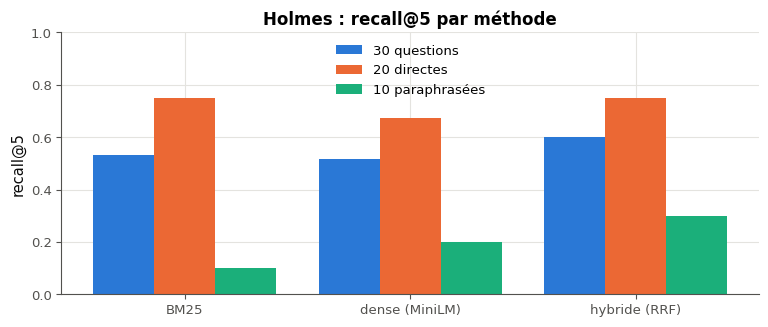

In [50]:
table_20 = None
if INDEX_20 is not None and written(lambda: evaluate_20(INDEX_20, QA[:1], "bm25")):
    with checked("B4.20"):
        start_20 = time.perf_counter()
        groups_20 = {"30 questions": QA, "20 directes": [q for q in QA if not q["paraphrased"]],
                     "10 paraphrasées": [q for q in QA if q["paraphrased"]]}
        table_20 = {}
        for method in ("bm25", "dense", "hybrid"):
            for group, items in groups_20.items():
                table_20["Holmes · MiniLM", method, group] = evaluate_20(INDEX_20, items, method)
        if SM_E5 is not None:
            chunks_fr = [c for _, body in DOCS_FR for c in mylearn.retrieval.chunk_text(body, chunk_size=120, overlap=20)]
            for name, model in (("Verne · e5", SM_E5), ("Verne · MiniLM", SM_19)):
                index_fr = build_index_20(chunks_fr, model, "b4-verne-120-20")
                for method in ("bm25", "dense", "hybrid"):
                    table_20[name, method, "10 questions"] = evaluate_20(index_fr, QA_FR, method)
        print(f"({fr(time.perf_counter() - start_20, 1)} s)\n{'corpus · modèle':18} {'méthode':8} {'questions':16} "
              "recall@1  recall@5   MRR")
        for (corpus, method, group), r in table_20.items():
            print(f"{corpus:18} {method:8} {group:16} {fr(r['recall@1'], 3):>8} {fr(r['recall@5'], 3):>9} "
                  f"{fr(r['mrr'], 3):>6}")
        print("\ne5 sur Holmes (précalculé, mode complet ; ≈ 1 min d'embeddings sur CPU) :")
        for method, group, r in E5_HOLMES_20:
            print(f"{'Holmes · e5':18} {method:8} {group:16} {fr(r['recall@1'], 3):>8} {fr(r['recall@5'], 3):>9} "
                  f"{fr(r['mrr'], 3):>6}")
        labels_20 = ["bm25", "dense", "hybrid"]
        fig, ax = plt.subplots(figsize=(9, 3.4))
        for k, group in enumerate(groups_20):
            ax.bar(np.arange(3) + 0.27 * (k - 1), [table_20["Holmes · MiniLM", m, group]["recall@5"] for m in labels_20],
                   width=0.27, label=group)
        ax.set_xticks(range(3), ["BM25", "dense (MiniLM)", "hybride (RRF)"])
        ax.set_ylabel("recall@5")
        ax.set_ylim(0, 1)
        ax.set_title("Holmes : recall@5 par méthode")
        ax.legend()
        plt.show()
else:
    print("⏳ Ex B4.20 : le tableau attend tes trois fonctions (et ta librairie de B4.17 et B4.18).")

### Ex B4.21 — Un RAG complet sur Holmes : récupération hybride, prompt avec citations, réponse d'un petit modèle 📦 ★★★ ⏱️ 60 min
**Objectif :** assembler un RAG qui cite ses passages, et vérifier ses citations contre les passages.  
**Prérequis :** Ex B4.20 · Ex B4.14 · fiche §204.7 (« Les quatre étapes », « Le contexte : combien, et dans quel ordre », « Évaluer et diagnostiquer ») · **Fil rouge :** Holmes · **Parcours :** R, C

Le générateur est Qwen2.5-0.5B-Instruct (494 M de paramètres, Apache 2.0, environ 1 Go à télécharger une fois) : SmolLM2-135M ne suit pas la consigne de citer. La cellule suivante donne `QWEN` (ses poids ne sont chargés qu'à la première génération que le cache ne connaît pas), `SYSTEM_21` (les règles : seulement les passages, une réponse courte suivie du numéro du passage entre crochets, « I don't know » sinon), `EXAMPLE_21` (un échange d'exemple qui montre le format de la réponse) et `QUESTIONS_21` (en mode rapide, 10 des 30 questions, dont 3 paraphrasées ; les 30 en mode complet).

**Contrat**
- `rag_messages_21(question, passages)` rend les messages : `{"role": "system", "content": SYSTEM_21}`, les deux messages de `EXAMPLE_21`, puis un message `user` au contenu exact `"Passages:\n[1] <premier passage>\n[2] <deuxième>…\n\nQuestion: <question>"` : les passages numérotés à partir de 1, dans l'ordre reçu, un par ligne, la question en dernier.
- `parse_reply_21(reply)` rend `(answer, cited)` : la réponse sans ses citations « [n] » (les blancs réduits à une espace, les blancs et les points retirés aux deux bouts), et la liste des numéros cités, dans l'ordre de leur première apparition, chacun une fois.
- `verify_21(answer, cited, passages)` rend `True` quand les citations tiennent : `cited` n'est pas vide, chaque numéro est un passage (de 1 à `len(passages)`), et au moins un passage cité contient **tous** les mots de contenu de la réponse : `wbrag.content_words(answer)`, non vide, inclus dans `set(tokenize(passage))`.
- `rag_21(question, index, llm, k=3)` enchaîne `search_20(index, question, "hybrid", k)`, les passages (`index["chunks"]`), `rag_messages_21`, une réponse gloutonne de 24 tokens au plus par le cache (`llm.generate(messages, max_new_tokens=24, cache=CACHE)`), `parse_reply_21` et `verify_21`, et rend `{"ids", "passages", "reply", "answer", "cited", "verified"}`.

La cellule de vérification compare `rag_messages_21` au prompt de référence, essaie `parse_reply_21` sur cinq réponses et `verify_21` sur huit cas. L'expérience fait tourner ton RAG sur `QUESTIONS_21` avec ton index de B4.20 (environ 40 s pour 10 questions la première fois, puis le cache) : pour chaque question, le passage pertinent est-il parmi les 3, la réponse est-elle juste (`wbrag.answer_in` : la réponse attendue ou une variante, en mots entiers), la citation est-elle vérifiée ? Elle compare enfin ta chaîne à la référence (`wbrag.ReferenceRAG`) sur la première question.

Dans tes notes : combien de réponses justes ne sont pas vérifiées, et pourquoi (le numéro cité, ou les mots de la réponse) ? Une réponse juste sans le bon passage dans les 3 : d'où vient-elle (fiche §204.5, contamination) ? Que vaut une citation que l'on ne vérifie pas ? La règle de `verify_21` accepte-t-elle une réponse fausse, ou refuse-t-elle une réponse juste ? Donne un exemple de chaque.

In [51]:
QWEN = wbllm.try_llm("qwen2.5", "B4.21")      # Qwen2.5-0.5B-Instruct (494 M parameters), weights loaded at first use
SYSTEM_21 = wbrag.RAG_SYSTEM                     # the rules: only the passages, a short answer, its citation [n]
EXAMPLE_21 = wbrag.RAG_EXAMPLE                   # one example exchange (user, assistant): the format of the reply
QUESTIONS_21 = [q for q in QA if q["id"] in wbrag.FAST_IDS] if FAST_MODE else QA
print("Le message système :", SYSTEM_21)
print("L'exemple :", EXAMPLE_21)

Le message système : You answer questions about the Sherlock Holmes stories. Use only the numbered passages. Give a short answer followed by the number of the passage that contains it, in square brackets. If no passage contains the answer, reply exactly: I don't know.
L'exemple : [{'role': 'user', 'content': 'Passages:\n[1] Watson took his hat and followed Holmes into the street.\n[2] The letter was posted at Charing Cross on Monday.\n\nQuestion: Where was the letter posted?'}, {'role': 'assistant', 'content': 'Charing Cross [2]'}]


In [52]:
def rag_messages_21(question, passages):
    """System rules, one example exchange, then the numbered passages and the question (last)."""
    numbered = "\n".join(f"[{n}] {p}" for n, p in enumerate(passages, start=1))
    return ([{"role": "system", "content": SYSTEM_21}] + [dict(m) for m in EXAMPLE_21]
            + [{"role": "user", "content": f"Passages:\n{numbered}\n\nQuestion: {question}"}])


def parse_reply_21(reply):
    """The answer without its citations, and the cited numbers (first appearance, each once)."""
    import re
    cited = []
    for match in re.finditer(r"\[(\d+)\]", reply):
        if int(match.group(1)) not in cited:
            cited.append(int(match.group(1)))
    answer = " ".join(re.sub(r"\[\d+\]", " ", reply).split()).strip(" .")
    return answer, cited


def verify_21(answer, cited, passages):
    """Every citation is a passage, and one cited passage holds every content word of the answer."""
    words = wbrag.content_words(answer)
    if not cited or not words or any(not 1 <= n <= len(passages) for n in cited):
        return False
    return any(words <= set(tokenize(passages[n - 1])) for n in cited)


def rag_21(question, index, llm, k=3):
    """Search, prompt, greedy reply, parse and verify."""
    ids = search_20(index, question, "hybrid", k)
    passages = [index["chunks"][i] for i in ids]
    reply = llm.generate(rag_messages_21(question, passages), max_new_tokens=24, cache=CACHE)
    answer, cited = parse_reply_21(reply)
    return {"ids": ids, "passages": passages, "reply": reply, "answer": answer, "cited": cited,
            "verified": verify_21(answer, cited, passages)}


with checked("B4.21"):
    msgs_21 = rag_messages_21("Who is it?", ["first passage", "second passage"])
    if returned("B4.21", "rag_messages_21", msgs_21):
        want_21 = wbrag.rag_messages("Who is it?", ["first passage", "second passage"])
        verdict("B4.21", msgs_21 == want_21, "rag_messages_21 : système, exemple, passages numérotés, question en dernier.",
                f"rag_messages_21 devrait rendre {len(want_21)} messages, le dernier : {want_21[-1]['content']!r} ; "
                f"reçu {str(msgs_21)[-160:]}.")
with checked("B4.21"):
    for reply_21, want_21 in (("Duke of Balmoral [2]", ("Duke of Balmoral", [2])),
                              ("Sir George Burnwell [1][3].", ("Sir George Burnwell", [1, 3])),
                              ("In London [2], at Baker Street [2].", ("In London , at Baker Street", [2])),
                              ("I don't know.", ("I don't know", [])),
                              ("  lawyer  ", ("lawyer", []))):
        got_21 = parse_reply_21(reply_21)
        verdict("B4.21", tuple(got_21) == want_21 if isinstance(got_21, (tuple, list)) else False,
                f"parse_reply_21({reply_21!r}) = {want_21}",
                f"parse_reply_21({reply_21!r}) devrait rendre {want_21} ; reçu {got_21!r}.")
with checked("B4.21"):
    passages_21 = ["Holmes plays the violin.", "The Duke of Balmoral has two sons."]
    for args_21, want_21 in ((("Duke of Balmoral", [2]), True), (("Duke of Balmoral", [1]), False),
                             (("Duke of Balmoral", [1, 2]), True), (("Duke of Balmoral", [3]), False),
                             (("Duke of Balmoral", []), False), (("the", [1]), False),
                             (("violin", [1, 3]), False), (("violin, of course", [1]), False)):
        got_21 = verify_21(*args_21, passages_21)
        verdict("B4.21", got_21 is want_21 or got_21 == want_21, f"verify_21{args_21} = {want_21}",
                f"verify_21{args_21} avec les passages {passages_21} devrait rendre {want_21} ; reçu {got_21!r}.")

✅ Ex B4.21 : rag_messages_21 : système, exemple, passages numérotés, question en dernier.
✅ Ex B4.21 : parse_reply_21('Duke of Balmoral [2]') = ('Duke of Balmoral', [2])
✅ Ex B4.21 : parse_reply_21('Sir George Burnwell [1][3].') = ('Sir George Burnwell', [1, 3])
✅ Ex B4.21 : parse_reply_21('In London [2], at Baker Street [2].') = ('In London , at Baker Street', [2])
✅ Ex B4.21 : parse_reply_21("I don't know.") = ("I don't know", [])
✅ Ex B4.21 : parse_reply_21('  lawyer  ') = ('lawyer', [])
✅ Ex B4.21 : verify_21('Duke of Balmoral', [2]) = True
✅ Ex B4.21 : verify_21('Duke of Balmoral', [1]) = False
✅ Ex B4.21 : verify_21('Duke of Balmoral', [1, 2]) = True
✅ Ex B4.21 : verify_21('Duke of Balmoral', [3]) = False
✅ Ex B4.21 : verify_21('Duke of Balmoral', []) = False
✅ Ex B4.21 : verify_21('the', [1]) = False
✅ Ex B4.21 : verify_21('violin', [1, 3]) = False
✅ Ex B4.21 : verify_21('violin, of course', [1]) = False


In [53]:
rows_21 = None
if QWEN is None or globals().get("INDEX_20") is None:
    print("⏳ Ex B4.21 : le RAG attend Qwen2.5 et ton index de B4.20.")
elif written(lambda: rag_21(QA[0]["question"], INDEX_20, QWEN)):
    with checked("B4.21"):
        start_21 = time.perf_counter()
        rows_21 = []
        for item in QUESTIONS_21:
            out = rag_21(item["question"], INDEX_20, QWEN)
            relevant = wbrag.relevant_ids(INDEX_20["chunks"], item)
            rows_21.append({"id": item["id"], "found": bool(relevant & set(out["ids"])),
                            "correct": wbrag.answer_in(out["answer"], item), "verified": out["verified"],
                            "idk": wbrag.is_idk(out["reply"]), "reply": out["reply"], "gold": item["answer"]})
        print(f"{len(rows_21)} questions en {fr(time.perf_counter() - start_21, 1)} s (cache : {CACHE.hits} réponses "
              f"relues, {CACHE.misses} générées)\n")
        print(f"{'id':4} {'trouvé':6} {'juste':6} {'citation':9} réponse  (attendu)")
        for r in rows_21:
            print(f"{r['id']:4} {'oui' if r['found'] else 'non':6} {'oui' if r['correct'] else 'non':6} "
                  f"{'vérifiée' if r['verified'] else '—':9} {r['reply']!r}  ({r['gold']})")
        n_21 = len(rows_21)
        print(f"\nPassage pertinent dans les 3 : {sum(r['found'] for r in rows_21)}/{n_21} · réponses justes : "
              f"{sum(r['correct'] for r in rows_21)}/{n_21} · citations vérifiées : {sum(r['verified'] for r in rows_21)}/{n_21}"
              f" · justes et vérifiées : {sum(r['correct'] and r['verified'] for r in rows_21)}/{n_21} · « I don't know » : "
              f"{sum(r['idk'] for r in rows_21)}/{n_21}")
        ref_rag_21 = wbrag.ReferenceRAG(QWEN, wbrag.ReferenceIndex(REF_CHUNKS, SM_19, subset="b4-holmes-120-20"),
                                        cache=CACHE)
        want_21 = ref_rag_21.answer(QUESTIONS_21[0]["question"])
        got_21 = rag_21(QUESTIONS_21[0]["question"], INDEX_20, QWEN)
        verdict("B4.21", got_21["reply"] == want_21["reply"] and got_21["verified"] == want_21["verified"],
                "ta chaîne rend la réponse et la vérification de la référence sur la première question.",
                f"sur {QUESTIONS_21[0]['question']!r}, la référence obtient {want_21['reply']!r} (vérifiée : "
                f"{want_21['verified']}) ; ton RAG {got_21['reply']!r} ({got_21['verified']}) : relis le contrat "
                "(hybride, k = 3, glouton, 24 tokens).")
else:
    print("⏳ Ex B4.21 : le RAG attend tes quatre fonctions.")

10 questions en 0,5 s (cache : 257 réponses relues, 0 générées)

id   trouvé juste  citation  réponse  (attendu)
H02  oui    oui    —         'lawyer'  (lawyer)
H03  oui    oui    —         'Pawnbroker’s business [2]'  (pawnbroker)
H05  non    non    vérifiée  'Fleet Street [3]'  (The Morning Chronicle)
H08  oui    oui    vérifiée  'Mr. John Turner [1]'  (John Turner)
H12  oui    oui    vérifiée  'Bar of Gold [3]'  (the Bar of Gold)
H16  oui    non    —         'on the western border of Surrey [2]'  (Stoke Moran)
H19  oui    oui    —         'Sir George Burnwell'  (Sir George Burnwell)
H21  oui    oui    —         'seventeen [2]'  (seventeen)
H25  non    non    —         'three'  (thirty-nine)
H28  non    non    —         'one penny [2]'  (twopence a sheet)

Passage pertinent dans les 3 : 7/10 · réponses justes : 6/10 · citations vérifiées : 3/10 · justes et vérifiées : 2/10 · « I don't know » : 0/10
✅ Ex B4.21 : ta chaîne rend la réponse et la vérification de la référence sur la premi

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu dire si un modèle tient en mémoire, poids et KV cache compris, selon son dtype ?
2. Sais-tu appliquer à la main un chat template et compter les tokens d'un prompt ?
3. Sais-tu calculer BM25, recall@k et MRR à la main ?
4. Sais-tu compter les paramètres de LoRA et dériver les gradients de $\mathbf{A}$ et $\mathbf{B}$ ?

**Pour aller plus loin** : le cours LLM de Hugging Face et l'article de LoRA, cités dans la fiche. La suite : le bonus B5, les modèles génératifs d'images.

*Les exercices B4.22 à B4.30 (la suite du RAG, le fine-tuning, la livraison) seront ajoutés à la prochaine session de génération ; relance alors `python tools/start_chapter.py B4` pour obtenir le notebook complet.*